( Previous: [**6.1  Vacuum Triodes**](../Chapter.6/chapter6.ipynb)( [**TOC**](../TOC.md) | Next: [**8.1 Wave Shaping And Amplification**](../chapter.8/chapter8.ipynb) )

**Chapter 7**

## Other Control Valves and their Circuit Models

**By Abbas Kohan and M. B. Ghaznavi-Ghoushchi**

## 7.1	Introduction

In the preceding chapters the properties of diodes, vacuum triodes, and transistors have been treated in some detail. There are, of course, many other electronic devices, each vvith its own peculiarities.  In this
chapter some of the fundamental properties of control valves are discussed and three specific devices, the vacuum pentode, the **cryotron,*** and
the thyratron, are considered as examples. The purpose of this chapter is to suggest the generality and usefulness of a few simple ideas in the process of characterizing an electronic device.

* D. A. Buck, The Cryotron -  A Superconductive Computer Component, Proc.
I.R.E., Vol. 44, p. 482 (1956).



## 7.2	The Control Valve

By the word "valve" we mean a physical device which imposes some constraint or relationship bet,veen two physical variables whose product is power. If the relationship does not involve time, then the valve is said to be "amnesic" or "memoryless." Figure 7.1 shows (a) an an1nesic valve for which the flow-versus-pressure relationship may be either linear, as in (b), or nonlinear, as in (c). In each case, (b) or (c), the valve is passive, since the curve never enters the second or fourth quadrants of the flow-pressure plane, and the instantaneous power absorbed by the valve is therefore never negative.

By a control valve we mean a valve whose flow-versus-pressure relationship is influenced by some other physical variable called the control parameter or control variable.  


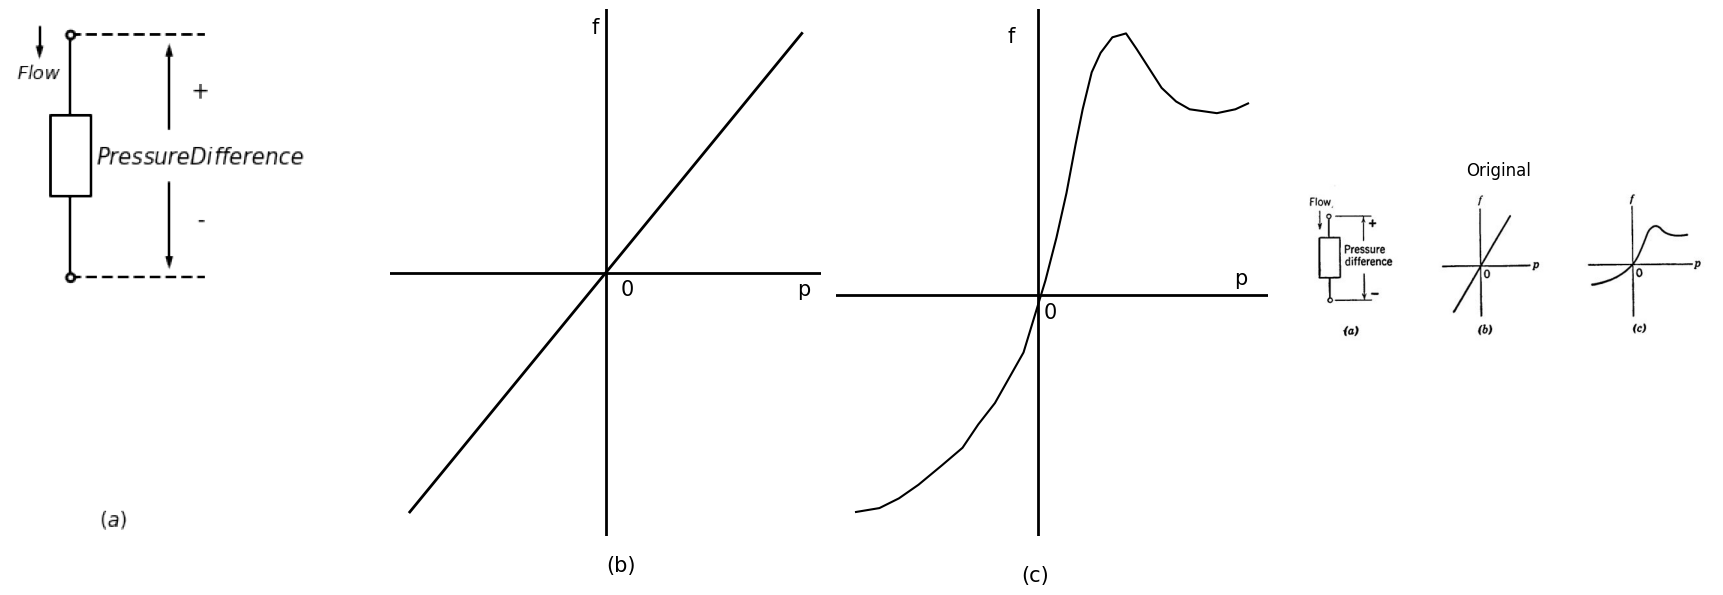

In [159]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 4, figsize=(18, 6))

#Data
P = [-9.211353423,-7.836701497,-6.688401202,-5.538446693,-4.157177911,-2.94836095,-2.023103857,-1.041465634,0.639078051,1.928262248,2.575749221,3.166855063,
     3.702406882,4.117752474,4.64834165,5.171486863,5.864602575,6.667172121,7.289845882,8.025281906,8.760717929,9.613051749,10.41065865,12.0108351,
     13.09944584,13.84563425]
F = [-6.448192771,-6.33253012,-6.043373494,-5.638554217,-5.060240964,-4.539759036,-3.845783133,-3.209638554,-1.706024096,0.43373494,1.706024096,3.036144578,
     4.481927711,5.522891566,6.621686747,7.2,7.662650602,7.778313253,7.315662651,6.737349398,6.159036145,5.754216867,5.522891566,5.407228916,5.522891566,
     5.696385542]

axs[2].plot(P, F, 'black',linestyle='-')
axs[2].axhline(0, color='black',linewidth=2, ls='-')
axs[2].axvline(1.5, color='black',linewidth=2, ls='-')
axs[2].text(-0.3,7.5, 'f', fontsize=15)
axs[2].text(13,0.3, 'p', fontsize=15)
axs[2].text(1.8,-0.7, '0', fontsize=15)
axs[2].text(0.5,-8.5, '(c)', fontsize=15)
axs[2].axis('off')

#rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', circuit.gnd, 2.5@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-4, 4, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=2)
axs[1].axhline(0, color='black',linewidth=2, ls='-')
axs[1].axvline(0, color='black',linewidth=2, ls='-')
axs[1].text( 0.3, -0.15, '0', fontsize=15)
axs[1].text( -0.3, 1.6, 'f', fontsize=15)
axs[1].text( 3.9, -0.15, 'p', fontsize=15)
axs[1].text(0,-2, '(b)', fontsize=15)
axs[1].axis('off')

d = schemdraw.Drawing()
d += ( T := dsp.Box(w=0.75, h=1.5).anchor('W'))
center_x, center_y = T.center
l1 = d.add(elm.Line().up().at((center_x+0, center_y + 0.75)).length(1.5).label('$Flow$').dot(open=True))
d += elm.Arrow().length(0.6).at((-0.2,2.4)).down()
l2 = d.add(elm.Line().down().at((center_x+0, center_y - 0.75)).length(1.5).dot(open=True))
d += elm.Line().right().length(2.5).at(l2.end).linestyle('--')
d += elm.Line().right().length(2.5).at(l1.end).linestyle('--')
d += elm.Gap().up().at((center_x+2.4, center_y - 1.5)).label(['-','','','' , '$Pressure Difference$' ,'','','', '+'] , fontsize = 16)
d += elm.Arrow().right().length(1.6).at((2.2,0.5)).up()
d += elm.Arrow().left().length(1.6).at((2.2,-0.5)).down()
d += elm.Gap().up().at((center_x+0.8, center_y - 8)).label('$(a)$'  , fontsize = 15)
d.save('./Drawings/fig1.png')
d.save('./Drawings/fig1.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display

img_sample = mpimg.imread('images/1.JPG')  # Load the PNG file
axs[3].imshow(img_sample)
axs[3].axis('off')  # Hide axes for image display
axs[3].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig.7.1  Valves and valve curves

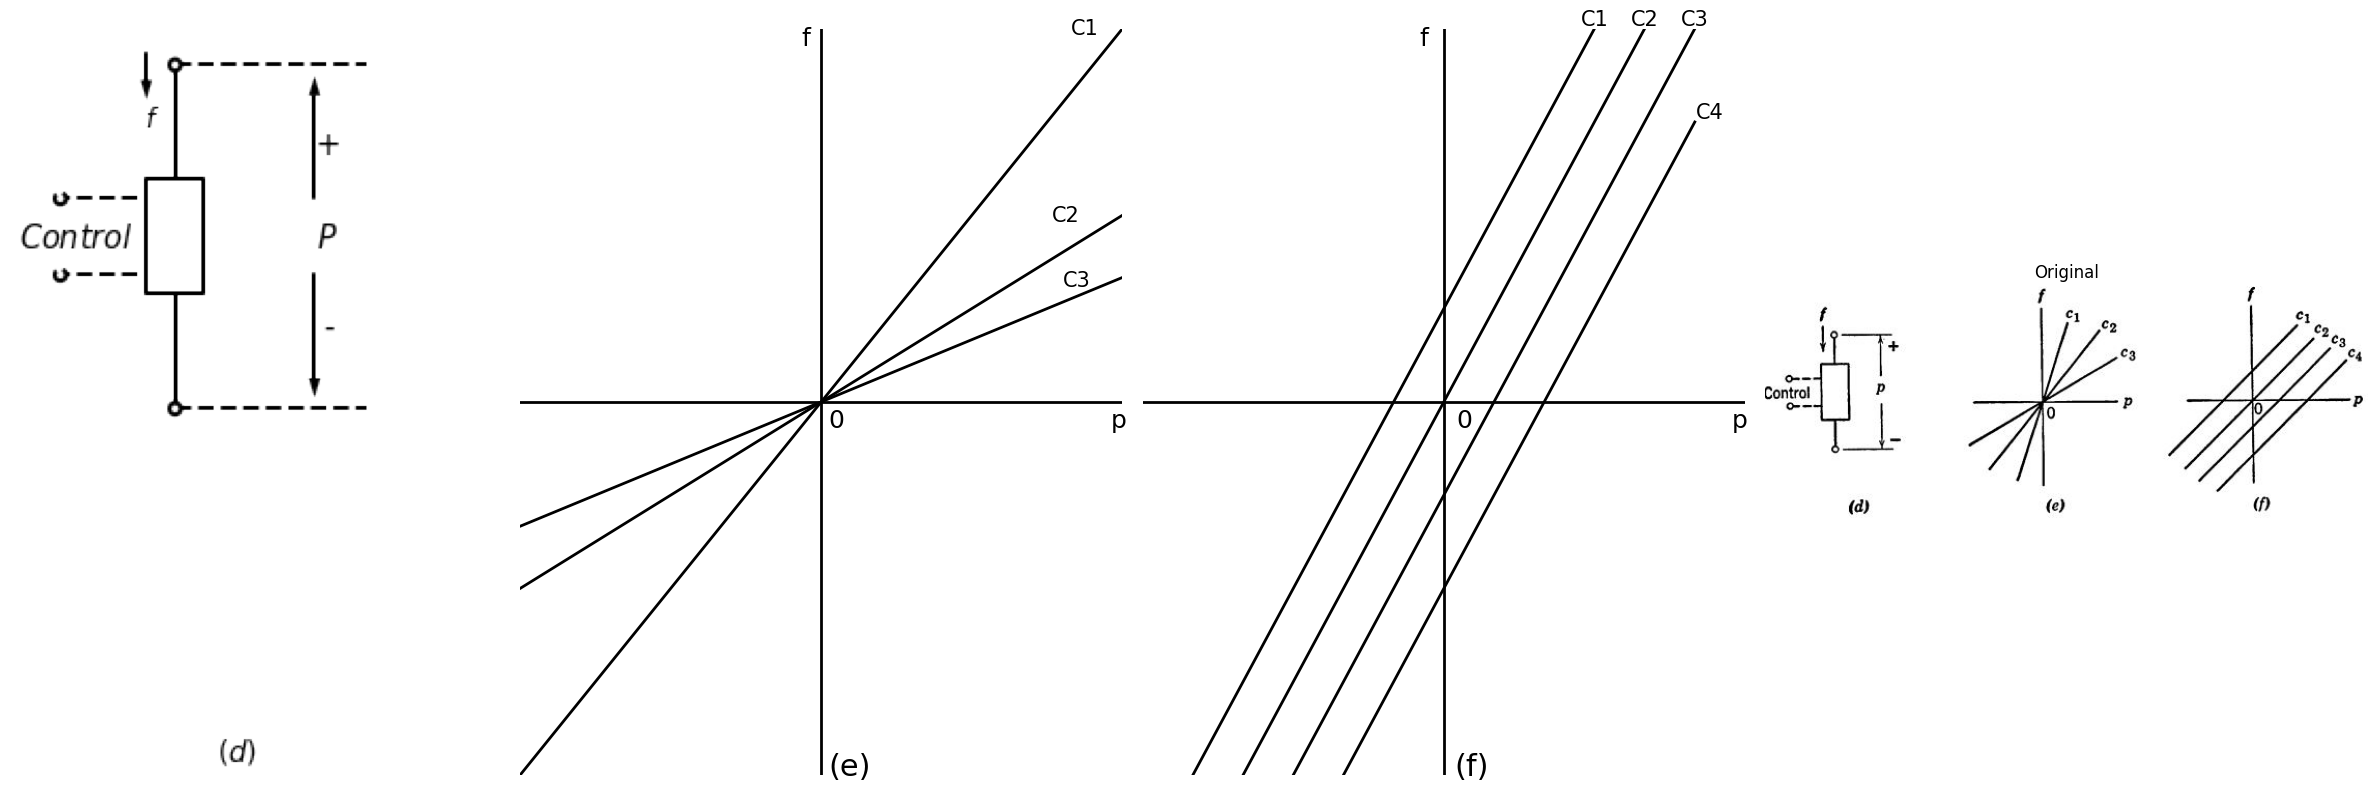

In [160]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 4, figsize=(25, 8))

d = schemdraw.Drawing()
d += ( T := dsp.Box(w=0.75, h=1.5).anchor('W'))
center_x, center_y = T.center
l1 = d.add(elm.Line().up().at((center_x-0., center_y + 0.75)).length(1.5).label('$f$').dot(open=True))
d += elm.Arrow().length(0.6).at((0,2.4)).down()
l2 = d.add(elm.Line().down().at((center_x+0, center_y - 0.75)).length(1.5).dot(open=True))
d += elm.Line().right().length(2.5).at(l2.end).linestyle('--')
d += elm.Line().right().length(2.5).at(l1.end).linestyle('--')
d += elm.Line().left().length(1).at((center_x-0.5, center_y + 0.5)).linestyle('--').dot(open=True)
d += elm.Line().left().length(1).at((center_x-0.5, center_y - 0.5)).linestyle('--').dot(open=True)
d += elm.Gap().up().at((center_x+2, center_y - 1.5)).label(['-','','','' , '$P$' ,'','','', '+'] , fontsize = 16)
d += elm.Gap().up().at((center_x-1.3, center_y - 1.5)).label([ '$Control$' ] , fontsize = 16)
d += elm.Arrow().right().length(1.6).at((2.2,0.5)).up()
d += elm.Arrow().left().length(1.6).at((2.2,-0.5)).down()
d += elm.Gap().up().at((center_x+0.8, center_y - 8)).label('$(d)$'  , fontsize = 15)
d.save('./Drawings/fig2.png')
d.save('./Drawings/fig2.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig2.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display

#rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-8, 8, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linewidth=2)

circuit = Circuit('v-i curve1')
Vt = circuit.V('t', '1', circuit.gnd, 0@u_V)
circuit.R(2 ,'1', circuit.gnd, 4@u_Ohm )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vt=slice(-8, 8, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vt),'black',linewidth=2)

circuit = Circuit('v-i curve2')
Vp = circuit.V('p', '1', circuit.gnd, 0@u_V)
circuit.R(2 ,'1', circuit.gnd, 6@u_Ohm )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vp=slice(-8, 8, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vp),'black',linewidth=2)

axs[1].axhline(0, color='black',linewidth=2, ls='-')
axs[1].axvline(0, color='black',linewidth=2, ls='-')
axs[1].text(7, 4, 'C1', ha='center', va='center', color='black', fontsize=15)
axs[1].text( 6.5, 2, 'C2', ha='center', va='center', color='black', fontsize=15)
axs[1].text( 6.8, 1.3, 'C3', ha='center', va='center', color='black', fontsize=15)
axs[1].text( -0.4, 3.9, 'f', ha='center', va='center', color='black', fontsize=18)
axs[1].text( 7.9, -0.2, 'p', ha='center', va='center', color='black', fontsize=18)
axs[1].text( 0.4, -0.2, '0', ha='center', va='center', color='black', fontsize=18)
axs[1].text(0.2,-4, '(e)', fontsize=22)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_xlim(-8, 8)
axs[1].set_ylim(-4,4)

#rcParams['font.weight'] = 'bold'
circuit = Circuit('Resistance and voltage')  
Vth = circuit.V('th', '1', circuit.gnd, 5@u_V)
circuit.R(1, '1', '2', 1@u_Ohm)
circuit.V('fixed', '2', circuit.gnd, 0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-5, 5, 0.1))
axs[2].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Resistance and voltage1')  
Vth1 = circuit.V('th1', '1', circuit.gnd, 5@u_V)
circuit.R(2, '1', '2', 1@u_Ohm)
circuit.V('fixed1', '2', circuit.gnd, 1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth1=slice(-5, 5, 0.1))
axs[2].plot(analysis['1'], u_A(-analysis.Vth1),'black',linestyle='-',linewidth=2)

circuit = Circuit('Resistance and voltage2')  
Vth2 = circuit.V('th2', '1', circuit.gnd, 5@u_V)
circuit.R(3, '1', '2', 1@u_Ohm)
circuit.V('fixed2', '2', circuit.gnd, 2@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth2=slice(-5, 5, 0.1))
axs[2].plot(analysis['1'], u_A(-analysis.Vth2),'black',linestyle='-',linewidth=2)

circuit = Circuit('Resistance and voltage3')  
Vth3 = circuit.V('th3', '1', circuit.gnd, 5@u_V)
circuit.R(2, '1', '2', 1@u_Ohm)
circuit.V('fixed3', '2', circuit.gnd, -1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth3=slice(-5, 5, 0.1))
axs[2].plot(analysis['1'], u_A(-analysis.Vth3),'black',linestyle='-',linewidth=2)

axs[2].axhline(0, color='black',linewidth=2, ls='-')
axs[2].axvline(0, color='black',linewidth=2, ls='-')
axs[2].text(5.3, 3.1, 'C4', ha='center', va='center', color='black', fontsize=15)
axs[2].text( 3, 4.1, 'C1', ha='center', va='center', color='black', fontsize=15)
axs[2].text( 4, 4.1, 'C2', ha='center', va='center', color='black', fontsize=15)
axs[2].text( 5, 4.1, 'C3', ha='center', va='center', color='black', fontsize=15)
axs[2].text( -0.4, 3.9, 'f', ha='center', va='center', color='black', fontsize=18)
axs[2].text( 5.9, -0.2, 'p', ha='center', va='center', color='black', fontsize=18)
axs[2].text( 0.4, -0.2, '0', ha='center', va='center', color='black', fontsize=18)
axs[2].text(0.2,-4, '(f)', fontsize=22)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_xlim(-6, 6)
axs[2].set_ylim(-4,4)

img_sample = mpimg.imread('images/2.JPG')  # Load the PNG file
axs[3].imshow(img_sample)
axs[3].axis('off')  # Hide axes for image display
axs[3].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig.7.1  Valves and valve curves

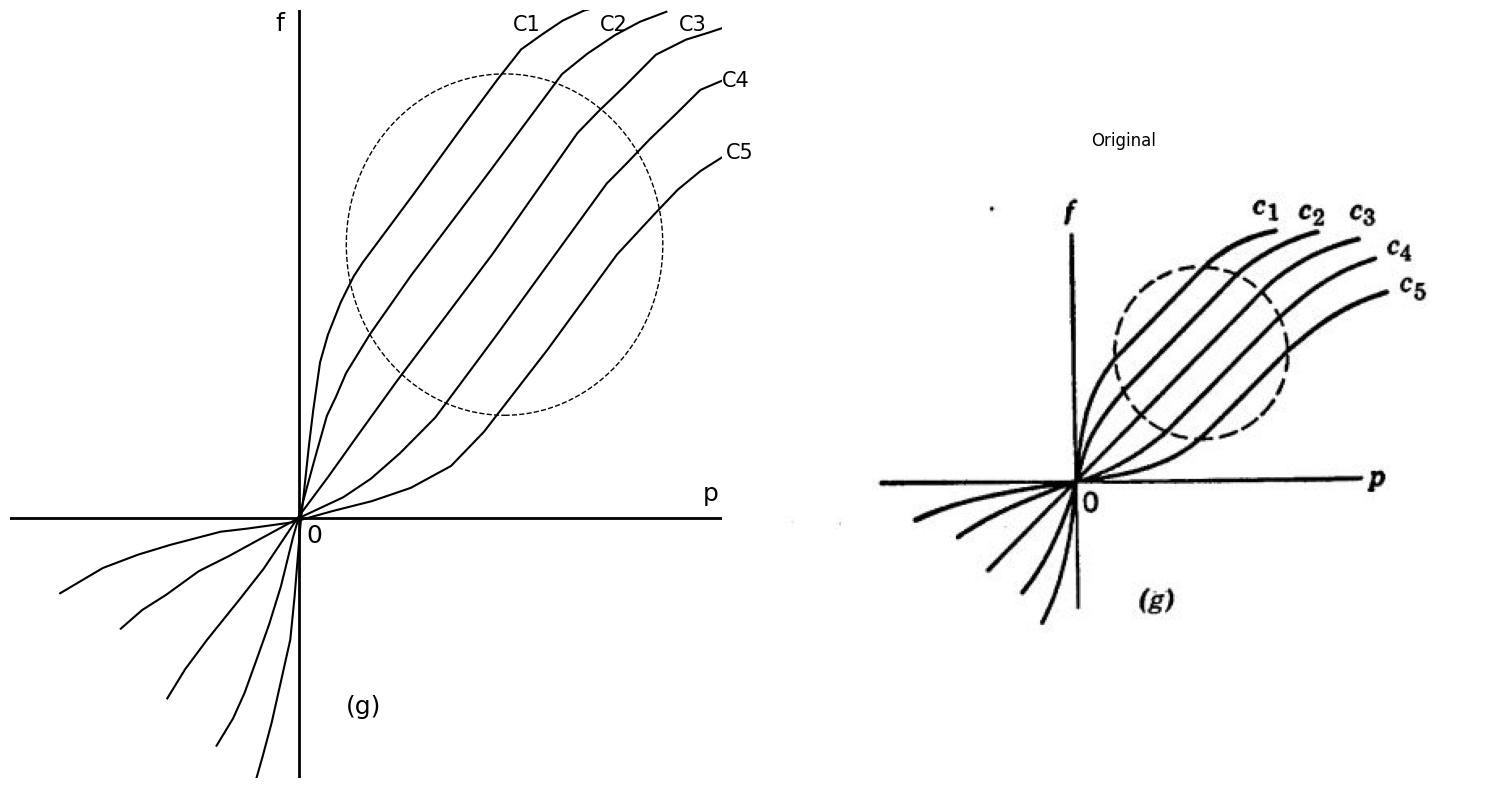

In [161]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(15, 8))

#Data
P1 = [-2.011709943,-1.814671268,-1.616499372,-1.384543348,-1.150320882,-0.916098417,-0.807380097,-0.657511716,-0.442341516,-0.336456247,-0.163002719,
      0.035169176,0.361111658,0.684787698,0.909944401,2.193316361,3.477254931,4.343531004,4.920481776,5.461381978,5.970197881,6.509398252,6.983863415]
F1 = [-8.709679196,-8.146043763,-7.501524732,-6.695663465,-5.728035004,-4.760406543,-3.750636453,-2.053780745,-0.196007759,0.611553338,1.741798908,
      2.386317939,3.150462535,3.752839937,4.073399621,5.674073258,7.315188693,8.395643398,9.075504736,9.432256643,9.748991709,9.984418221,10.09936925]
P2 = [-2.779254199,-2.360458482,-2.06830013,-1.70857352,-1.446799636,-1.150675014,-0.85115073,-0.652978835,-0.321936862,0.0085385,0.235395034,0.495469086,
      1.107337208,2.135167996,4.059659326,5.53553708,5.952632966,6.589786065,7.289407932,7.92429459,8.589565717]
F2 = [-7.24315051,-6.601606182,-5.998803823,-5.073316991,-4.389206077,-3.503311128,-2.374765388,-1.730246357,-0.602125575,0.485553409,0.927438489,
      1.490224008,2.412311179,3.773733685,6.134302342,7.975077024,8.495295955,8.972098386,9.407609102,9.722644338,9.956371019]
P3 = [-4.02466328,-3.573783264,-3.028350181,-2.195291627,-1.586256556,-0.718280653,0.051742523,0.79024801,1.785427889,4.191183704,6.343098177,6.886264819,
      7.556635438,8.323258953,9.084782977,9.622850128,10.12939959]
F3 = [-6.134223646,-5.452662477,-4.772376182,-3.812821915,-3.092943736,-1.891163636,-0.930759454,0.030069685,1.311033552,4.271854822,7.114750357,
      7.633269459,8.230972327,8.948725717,9.302502922,9.457045836,9.612013709]
P4 = [-5.199671051,-4.657637629,-4.05370205,-3.226309597,-2.464785573,-1.766296927,-0.750364952,0.423155468,1.122777334,1.85618333,2.750577431,4.322708082,
      7.083091016,7.594173359,8.1694243,8.839794919,9.446563549,10.14391897,10.71520365]
F4 = [-4.500403316,-4.062767812,-3.70686582,-3.151729538,-2.797952334,-2.443325215,-1.931180477,-1.421160528,-0.985649811,-0.388796858,0.448582097,
      2.409407302,5.931739218,6.410241478,6.968777421,7.566480289,8.124591273,8.398334796,8.673778149]
P5 = [-6.732705603,-5.652605029,-4.76557686,-3.942717289,-2.677476854,-2.014472167,-0.877568928,0.166481076,1.146929091,2.128510327,3.144442302,3.975234415,
      5.578316145,7.3435192,8.302648509,8.87789945,9.451450561,10.05538614,10.81634355,11.13378688]    
F5 = [-3.670744423,-3.078566004,-2.766930429,-2.535328536,-2.228792451,-2.156832964,-2.010364244,-1.741295255,-1.51181815,-1.201457447,-0.68931271,
      0.108474363,2.028432811,4.26980086,5.227655296,5.786191239,6.223401786,6.579303778,6.892639183,7.050156801]    
axs[0].plot(P1, F1, 'black',linestyle='-')
axs[0].plot(P2, F2, 'black',linestyle='-')
axs[0].plot(P3, F3, 'black',linestyle='-')
axs[0].plot(P4, F4, 'black',linestyle='-')
axs[0].plot(P5, F5, 'black',linestyle='-')
axs[0].axhline(-1.9, color='black',linewidth=2, ls='-')
axs[0].axvline(-0.7, color='black',linewidth=2, ls='-')
axs[0].text(-1.3,9.5, 'f', fontsize=18)
axs[0].text(9.5,-1.5, 'p', fontsize=18)
axs[0].text(-0.5,-2.5, '0', fontsize=18)
axs[0].text(0.5,-6.5, '(g)', fontsize=18)
axs[0].text(4.7,9.5, 'C1', fontsize=15)
axs[0].text(6.9,9.5, 'C2', fontsize=15)
axs[0].text(8.9,9.5, 'C3', fontsize=15)
axs[0].text(10,8.2, 'C4', fontsize=15)
axs[0].text(10.1,6.5, 'C5', fontsize=15)

circle = plt.Circle((4.5, 4.5), 4, color='black',linestyle='--', fill=False)
axs[0].add_patch(circle)
axs[0].set_xlim(-8, 10)
axs[0].set_ylim(-8,10)
axs[0].axis('off')

img_sample = mpimg.imread('images/3.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig.7.1  Valves and valve curves

The control variable is itself either a pressure or a flow and is applied to the valve at some auxiliary terminalpair as indicated in Fig. 7.1(d). Hence the control variable is one of a pair of variables whose product is power, and the relationship between these two variables is fixed by the characteristics of the control valve.
We shall say that the control valve is unilateral if the control-variable pair relationship is unaffected by the value of the pressure or flow in the main part of the valve. In other words, the control influences the valve but there is no reaction or influence in the reverse direction. If application and maintenance of the control signal require negligible power, then the valve has ideal control.

An ideal unilateral amnesic control valve is completely described by a family of valve curves such a.s that shown in Fig. 7.l(e), one curve for each of a number of different values of the control parameter c, with the tacit assumption that we can interpolate between these curves for other values of c.  (If the valve is not unilateral, we require another such family of curves to relate the two variables at the control point, with either f or p playing the role of a control parameter in the reverse direction.)

The ideal unilateral control valve of Fig. 7.l(e) is passive (at least for the range of c shown), since none of the curves enter thesecond or fourth quadrants. For any fixed c, the relationship between **f** and **p** is linear, but the complete function **f (p, c)** is nonlinear.  An ideal multiplier **(f = pc)** or divider **(f = p/c)** has characteristic curves like those in Fig. 7.1(e). The carbon microphone and the kitchen faucet fall roughly into this category.

If the function f (p, c) is linear, then the valve curves are parallel straight lines with equal spacing for equal increments of the control parameter, as shown in Fig. 7.l(f). It is apparent, therefore, that an ideal unilateral control valve cannot be passive if it is linear.

Many devices exhibit a control effect arising from physical laws that are inherently linear over a significant region of operation. In the vacuum triode, for example, grid control is governed, essentially, by electrostatic field equations. The uniform horizontal spacing µ. of the triode curves in the central region of operation is a consequence of the linearity of these field equations. Similarly, the emitter-to-collector current-control ratio of a transistor is essentially a constant dependent upon the transistor geometry, with the result that thetransistor collector curves are very nearly parallel and equally spaced in the usual region of interest. Thus we have some reason to be concerned with control devices which are regionally-linear as indicated by the curves within the dashed contour in Fig. 7.1(g). The point is that if an ideal unilateral amnesic control valve is linear in some region, then it must necessarily become nonlinear outside this region in order to remain passive, as illustrated in Fig. 7.1(g).

The above discussion gives us the background for a better understanding of the circuit models for such devices. In the next two articles we shall see how the circuit model of an ideal unilateral amnesi'c passive regionally-linear control valve can be represented as a combination of two parts, one providing ideal unilateral linear control and the other providing the nonlinearities necessary to insure passivity.





## 7.3	The Energy Valve

Figure 7.2(a) shows the ideal diode or ideal rectifier, a circuit element that hasappeared repeatedly in the preceding chapters.	The ideal diode is not only passive but also lossless, since the product **vi** is always identically equal to zero.	The ideal diode can be completely characterized by statements that its current is never negative, its voltage is never positive, and the product **vi** is always zero.	The combination of two diodes indicated in Fig. 7.2(b) is a two-terminal-pair "filter" having the n1arvelous property that energy can flow through the filter from left to right but never from right to left!	To see this, first observe that **i1** is never negative and that **v1** cannot be negative when **i1** is positive.	Thus, the instantaneous power **v1.i1** can never be negative.	Now, since each of the diodes is lossless, the complete circuit must be lossless and the output power **v2.i2**  must be equal to the input power **v1.i1**.		Hence the circuit shown in Fig. 7.2(b) is a trapdoor or valve through which energy can pass in only one direction.

Parts (c) and (d) of Fig. 7.2 offer two additional forms of the lossless energy valve. The lattice structure (d) is recognizable as a diode bridge circuit and is obtainable by connecting two circuits of the type shown in part (c) with their outputs in parallel and their inputs in series opposition.

The energy valve is a useful building block in the construction of a circuit model for a passive device.	No matter what we may connect to
the output terminals, the complete circuit, as viewed from the input terminals, **v1** and **i1**, is automatically passive.


## 7.4	Circuit Models for Control Valves

Figure 7.3(a) shows the circuit model for an ideal unilateral linear (but not passive) control valve. The voltage source Vis assumed to be unilaterally controlled by some physical variable at an ideal control point not shown in the figure. The associated valve curves are indicated in (b). The model is obviously not passive since power can be extracted from it for any nonzero **V** by proper adjustment of an applied voltage **v** or current **i**.


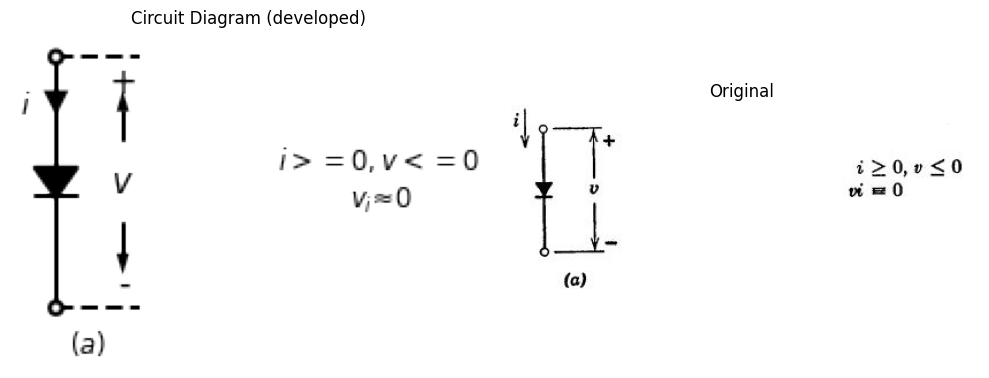

In [203]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
D1 = d.add(elm.Diode(fill=True).down().dot(open=True))
d += elm.lines.CurrentLabelInline().at(D1).down().label('$i$').color('black')
d += elm.Gap().up().label(['-','','','' , '$v$' ,'','','', '+'], ofst=-0.8 , fontsize = 16).color('black')
d += elm.Line().right().length(1).at(D1.end).color('black').linestyle('--')
d += elm.Line().right().length(1).at(D1.start).color('black').linestyle('--')
d += elm.Arrow().right().length(0.6).at((0.8,-1)).color('black').up()
d += elm.Arrow().left().length(0.6).at((0.8,-2)).color('black').down()
d += elm.Gap().up().at((center_x+3.5, center_y -2.5)).color('black').label('$i>=0,v<=0$'  , fontsize = 13)
d += elm.Gap().up().at((center_x+3.5, center_y -3)).label('$v_i≈0$'  , fontsize = 13)
d += elm.Gap().up().at((center_x+0.0, center_y -4.7)).label('$(a)$'  , fontsize = 13)
d.save('./Drawings/fig4.png')
d.save('./Drawings/fig4.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig4.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/4.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig. 7.2.	Ideal valves.	(a) The ideal diode valve, into which no energy flows.

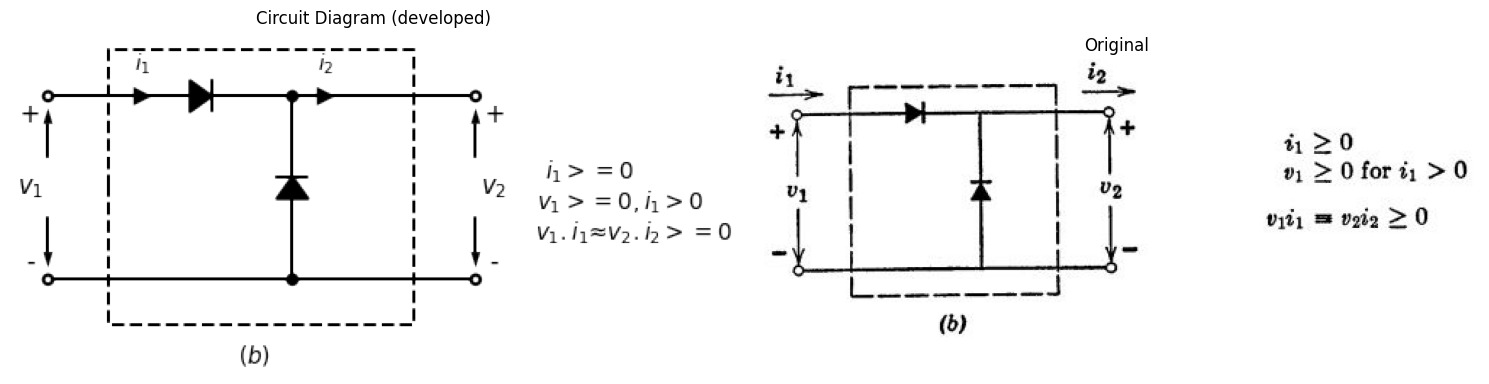

In [206]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
    
d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
l0 = d.add(elm.Line().right().length(1))
d += ( T := dsp.Box(w=5, h=4.5).anchor('W').linestyle('--').at((1,-1.5)))
D1 = d.add(elm.Diode(fill=True).right().dot())
d += elm.lines.CurrentLabelInline().at(D1).right().label('$i_1$')
l1 = d.add(elm.Line().right().dot(open=True))
d += elm.Gap().up().at((-1.3,-3)).label(['-' ,'','','', '$v_1$' ,'','','', '+'], ofst=-1 , fontsize = 16)
d += elm.lines.CurrentLabelInline().at(l1).right().label('$i_2$')
D2 = d.add(elm.Diode(fill=True).down().reverse().at(D1.end).dot())
l2 = d.add(elm.Line().right().dot(open=True))
d += elm.Gap().up().at((6.3,-3)).label(['-' ,'','','', '$v_2$' ,'','','', '+'], ofst=-1 , fontsize = 16)
l3 = d.add(elm.Line().left().at(D2.end).length(4).dot(open=True))

d += elm.Arrow().right().length(0.8).at((0,-1)).color('black').up()
d += elm.Arrow().left().length(0.8).at((0,-2)).color('black').down()
d += elm.Arrow().right().length(0.8).at((7,-1)).color('black').up()
d += elm.Arrow().left().length(0.8).at((7,-2)).color('black').down()
d += elm.Gap().up().at((center_x+8.5, center_y -2.5)).label('$i_1>=0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+9, center_y -3)).label('$v_1>=0 , i_1>0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+9.2, center_y -3.5)).label('$v_1.i_1≈v_2.i_2>=0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+3.0, center_y -5.5)).label('$(b)$'  , fontsize = 15)
d.save('./Drawings/fig5.png')
d.save('./Drawings/fig5.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig5.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig. 7.2. Ideal valves.	 (b) Energy valves, through which energy can flow in only one direction.

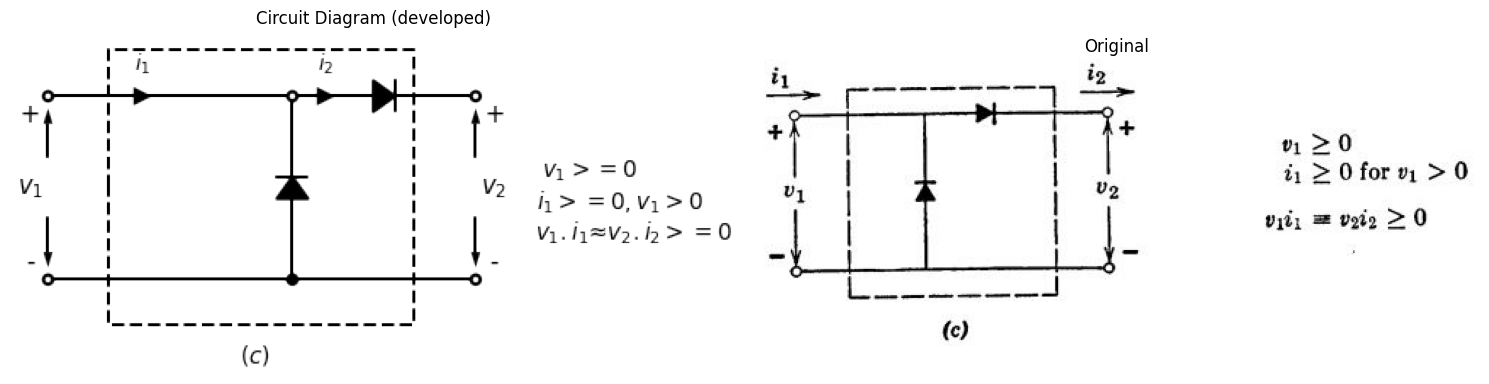

In [208]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
    
d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
l0 = d.add(elm.Line().right().length(1))
d += ( T := dsp.Box(w=5, h=4.5).anchor('W').linestyle('--').at((1,-1.5)))
l1 = d.add(elm.Line().right().dot(open=True))
D1 = d.add(elm.Diode(fill=True).down().reverse().dot())
d += elm.lines.CurrentLabelInline().at(l1).right().label('$i_1$')
d += elm.Gap().up().at((-1.3,-3)).label(['-' ,'','','', '$v_1$' ,'','','', '+'], ofst=-1 , fontsize = 16)
D2 = d.add(elm.Diode(fill=True).right().at(l1.end).dot(open=True))
d += elm.lines.CurrentLabelInline().at(D2).right().label('$i_2$')
l2 = d.add(elm.Line().right().at(D1.end).dot(open=True))
d += elm.Gap().up().at((6.3,-3)).label(['-' ,'','','', '$v_2$' ,'','','', '+'], ofst=-1 , fontsize = 16)
l3 = d.add(elm.Line().left().at(D1.end).length(4).dot(open=True))

d += elm.Arrow().right().length(0.8).at((0,-1)).color('black').up()
d += elm.Arrow().left().length(0.8).at((0,-2)).color('black').down()
d += elm.Arrow().right().length(0.8).at((7,-1)).color('black').up()
d += elm.Arrow().left().length(0.8).at((7,-2)).color('black').down()
d += elm.Gap().up().at((center_x+8.5, center_y -2.5)).label('$v_1>=0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+9, center_y -3)).label('$i_1>=0 , v_1>0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+9.2, center_y -3.5)).label('$v_1.i_1≈v_2.i_2>=0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+3.0, center_y -5.5)).label('$(c)$'  , fontsize = 15)
d.save('./Drawings/fig6.png')
d.save('./Drawings/fig6.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig6.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/6.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig. 7.2. Ideal valves.	  (c) Energy valves, through which energy can flow in only one direction.

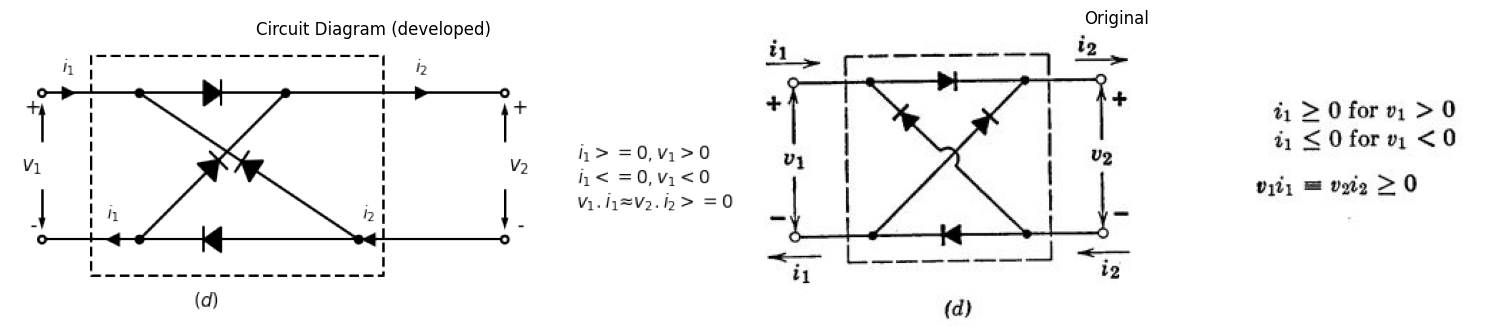

In [345]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
    
d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
l0 = d.add(elm.Line().right().length(1))
l1 = d.add(elm.Line().right().length(1).dot())
d += ( T := dsp.Box(w=6, h=4.5).anchor('W').linestyle('--').at((1,-1.5)))
d += elm.lines.CurrentLabelInline().at(l1).right().label('$i_1$')
d += elm.Gap().up().at((-1.2,-3)).label(['-' ,'','','', '$v_1$' ,'','','', '+'], ofst=-1 , fontsize = 16)
D1 = d.add(elm.Diode(fill=True).right().at(l1.end).dot())
l2 = d.add(elm.Line().right())
l3 = d.add(elm.Line().right().length(1.5).dot(open=True))
d += elm.lines.CurrentLabelInline().at(l3).right().label('$i_2$')
d += elm.Dot(open=True).at((0,-3))
l4 = d.add(elm.Line().right().length(1))
d += elm.lines.CurrentLabelInline().at(l4).left().label('$i_1$')
l5 = d.add(elm.Line().right().length(1).dot())
D2 = d.add(elm.Diode(fill=True).right().reverse())
l6 = d.add(elm.Line().right().length(1.5).dot())
l7 = d.add(elm.Line().right().dot(open=True))
d += elm.lines.CurrentLabelInline().at(l6).left().label('$i_2$')
D3 = d.add(elm.Diode(fill=True).endpoints(l5.end,D1.end))
D4 = d.add(elm.Diode(fill=True).endpoints(l6.end,D1.start))
d += elm.Gap().up().at((8.8,-3)).label(['-' ,'','','', '$v_2$' ,'','','', '+'], ofst=-1 , fontsize = 16)
d += elm.Arrow().right().length(0.8).at((0,-1)).color('black').up()
d += elm.Arrow().left().length(0.8).at((0,-2)).color('black').down()
d += elm.Arrow().right().length(0.8).at((9.5,-1)).color('black').up()
d += elm.Arrow().left().length(0.8).at((9.5,-2)).color('black').down()
d += elm.Gap().up().at((center_x+12, center_y -2.5)).label('$i_1>=0 , v_1>0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+12, center_y -3)).label('$i_1<=0 , v_1<0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+12.2, center_y -3.5)).label('$v_1.i_1≈v_2.i_2>=0$'  , fontsize = 15)
d += elm.Gap().up().at((center_x+3.0, center_y -5.5)).label('$(d)$'  , fontsize = 15)
d.save('./Drawings/fig7.png')
d.save('./Drawings/fig7.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig7.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/7.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig. 7.2. Ideal valves.	  (d) Energy valves, through which energy can flow in only one direction.

Insertion of an energy valve, as shown in Fig. 7.3(c), assures passivity without disturbin the character of the valve curves within the first quadrant of the **i** vs. **v** plane. The energy valve introduces the nonlinearity indicated in (d) and makes the second and fourth (nonpassive) quadrants forbidden ground.  With **V** replaced by the negative of **µec**, where **ec** is the grid control voltage of a vacuum triode, we recognize Fig. 7.3(d) as the piecewise-linear approximation to the plate curves of that triode [see Fig. 6.10 (d)].


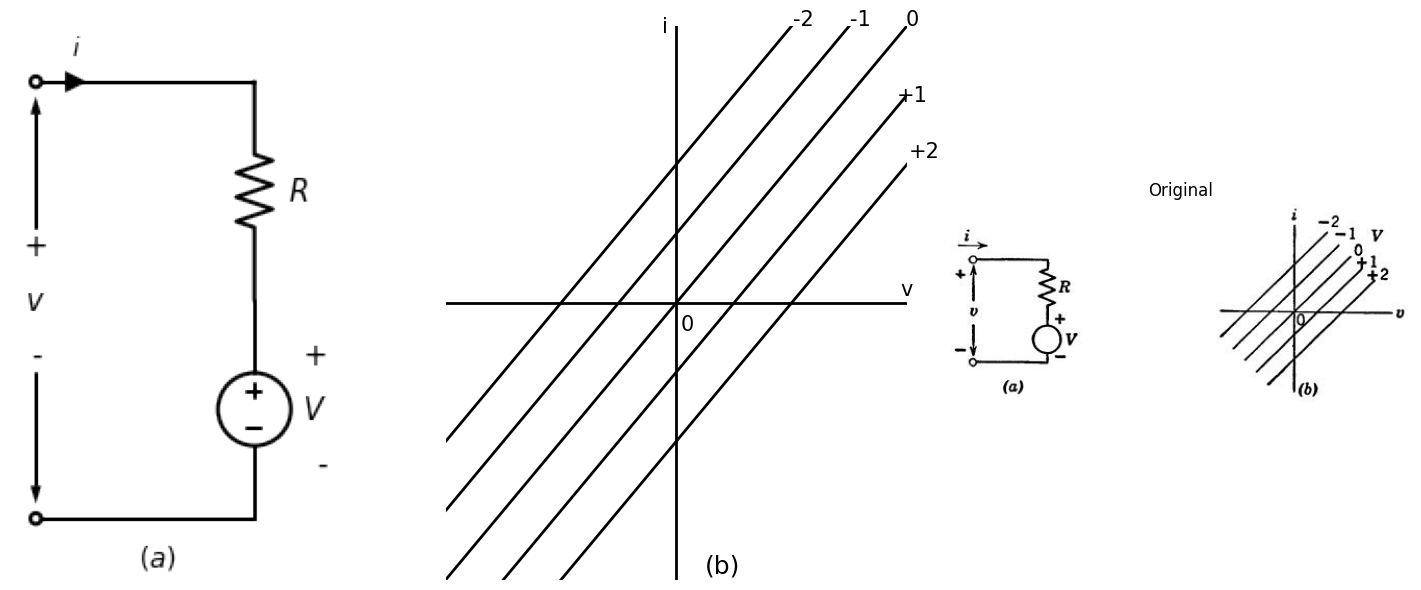

In [292]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
l1 = d.add(elm.Line().right())
d += elm.lines.CurrentLabelInline().at(l1).right().label('$i$')
d += ( R1 := elm.Resistor().down().label(['$R$'] , ofst=-1 , fontsize = 16))
d += ( V := elm.SourceV().down().reverse().label(['+','$V$','-'] , ofst=-1.5 , fontsize = 16))
d += elm.Line().left().dot(open=True)
d += elm.Gap().up().at((-1,-4.5)).label(['-' , '$v$' , '+'], ofst=-1 , fontsize = 16)
d += elm.Arrow().right().length(1.8).at((0,-2)).color('black').up()
d += elm.Arrow().left().length(1.8).at((0,-4)).color('black').down()
d += elm.Gap().up().at((center_x+1.3, center_y -7.8)).label('$(a)$'  , fontsize = 15)
d.save('./Drawings/fig8.png')
d.save('./Drawings/fig8.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig8.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display

#rcParams['font.weight'] = 'bold'

circuit = Circuit('Resistance and voltage')  
Vth = circuit.V('th', '1', circuit.gnd, 5@u_V)
circuit.R(1, '1', '2', 1@u_Ohm)
circuit.V('fixed', '2', circuit.gnd, 0@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-5, 5, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Resistance and voltage1')  
Vth1 = circuit.V('th1', '1', circuit.gnd, 5@u_V)
circuit.R(2, '1', '2', 1@u_Ohm)
circuit.V('fixed1', '2', circuit.gnd, 1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth1=slice(-5, 5, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vth1),'black',linestyle='-',linewidth=2)

circuit = Circuit('Resistance and voltage2')  
Vth2 = circuit.V('th2', '1', circuit.gnd, 5@u_V)
circuit.R(3, '1', '2', 1@u_Ohm)
circuit.V('fixed2', '2', circuit.gnd, 2@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth2=slice(-5, 5, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vth2),'black',linestyle='-',linewidth=2)

circuit = Circuit('Resistance and voltage3')  
Vth3 = circuit.V('th3', '1', circuit.gnd, 5@u_V)
circuit.R(2, '1', '2', 1@u_Ohm)
circuit.V('fixed3', '2', circuit.gnd, -1@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth3=slice(-5, 5, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vth3),'black',linestyle='-',linewidth=2)

circuit = Circuit('Resistance and voltage4')  
Vth3 = circuit.V('th4', '1', circuit.gnd, 5@u_V)
circuit.R(3, '1', '2', 1@u_Ohm)
circuit.V('fixed4', '2', circuit.gnd, -2@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth4=slice(-5, 5, 0.1))
axs[1].plot(analysis['1'], u_A(-analysis.Vth4),'black',linestyle='-',linewidth=2)

axs[1].text(4.3, 2.2, '+2', ha='center', va='center', fontsize=15)
axs[1].text(4.1, 3, '+1', ha='center', va='center', fontsize=15)
axs[1].text(4.1, 4.1, '0', ha='center', va='center', fontsize=15)
axs[1].text(3.2, 4.1, '-1', ha='center', va='center', fontsize=15)
axs[1].text(2.2, 4.1, '-2', ha='center', va='center', fontsize=15)
axs[1].text(0.2, -0.3, '0', ha='center', va='center', fontsize=15)
axs[1].text(-0.2, 4, 'i', ha='center', va='center', fontsize=15)
axs[1].text(4, 0.2, 'v', ha='center', va='center', fontsize=15)
axs[1].text(0.8, -3.8, '(b)', ha='center', va='center', fontsize=18)

axs[1].axhline(0, color='black',linewidth=2, ls='-')
axs[1].axvline(0, color='black',linewidth=2, ls='-')
axs[1].set_xlim(-4, 4)
axs[1].set_ylim(-4, 4)
axs[1].axis('off')  # Hide axes for image display


# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig.  7.3. Ideal control valves and associated curves.(a),(b)

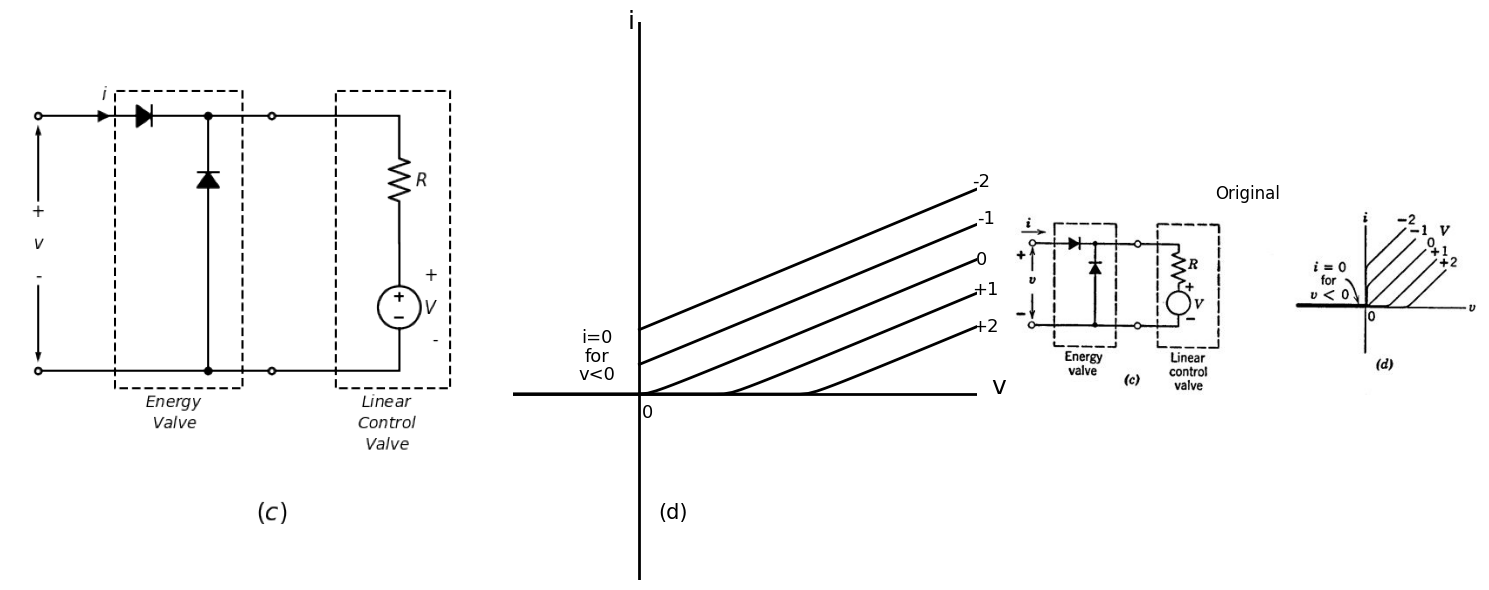

In [328]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
l0 = d.add(elm.Line().right().length(1))
D1 = d.add(elm.Diode(fill=True).right().dot())
d += ( T := dsp.Box(w=3, h=7).anchor('W').linestyle('--').at((1.8,-2.9)))
d += elm.lines.CurrentLabelInline().at(D1).right().label('$i$', fontsize = 16)
l1 = d.add(elm.Line().right().length(1.5).dot(open=True))
l2 = d.add(elm.Line().right())
d += ( R1 := elm.Resistor().down().label(['$R$'] , ofst=-0.9 , fontsize = 16))
d += ( V := elm.SourceV().down().reverse().label(['+','$V$','-'] , ofst=-1.4 , fontsize = 16))
l3 = d.add(elm.Line().left().dot(open=True))
l4 = d.add(elm.Line().left().length(1.5).dot())
l5 = d.add(elm.Line().left().length(4).dot(open=True))
l6 = d.add(elm.Line().up().at(l4.end))
d += elm.Gap().up().at((-1,-4.5)).label(['-' , '$v$' , '+'], ofst=-1 , fontsize = 16)
D2 = d.add(elm.Diode(fill=True).down().reverse().at(D1.end))
d += elm.Arrow().right().length(1.8).at((0,-2)).color('black').up()
d += elm.Arrow().left().length(1.8).at((0,-4)).color('black').down()
d += ( T := dsp.Box(w=2.7, h=7).anchor('W').linestyle('--').at((7,-2.9)))
d += elm.Gap().up().at((3.2,-8)).label('$Energy$'  , fontsize = 15)
d += elm.Gap().up().at((3.2,-8.5)).label('$Valve$'  , fontsize = 15)
d += elm.Gap().up().at((8.2,-8)).label('$Linear$'  , fontsize = 15)
d += elm.Gap().up().at((8.2,-8.5)).label('$Control$'  , fontsize = 15)
d += elm.Gap().up().at((8.2,-9)).label('$Valve$'  , fontsize = 15)
d += elm.Gap().up().at((5.5,-10.5)).label('$(c)$'  , fontsize = 22)
d.save('./Drawings/fig9.png')
d.save('./Drawings/fig9.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig9.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display

#rcParams['font.weight'] = 'bold'

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 0@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-3, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, -2@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, -4@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 2@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-3, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 4@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

axs[1].text(8.2, 0.28, '+1', ha='center', va='center', fontsize = 13)
axs[1].text(8.2, 0.18, '+2', ha='center', va='center', fontsize = 13)
axs[1].text(8.1, 0.36, '0', ha='center', va='center', fontsize = 13)
axs[1].text(8.2, 0.47, '-1', ha='center', va='center', fontsize = 13)
axs[1].text(8.1, 0.57, '-2', ha='center', va='center', fontsize = 13)
axs[1].text(0.2, -0.05, '0', ha='center', va='center', fontsize = 13)
axs[1].text(-1, 0.15, 'i=0', ha='center', va='center', fontsize = 13)
axs[1].text(-1, 0.1, 'for', ha='center', va='center', fontsize = 13)
axs[1].text(-1, 0.05, 'v<0', ha='center', va='center', fontsize = 13)
axs[1].text(-0.2, 1, 'i', ha='center', va='center', fontsize = 18)
axs[1].text(8.5, 0.02, 'v', ha='center', va='center', fontsize = 18)
axs[1].text(0.8, -0.32, '(d)', ha='center', va='center', fontsize=15)

axs[1].axhline(0, color='black',linewidth=2, ls='-')
axs[1].axvline(0, color='black',linewidth=2, ls='-')
axs[1].set_xlim(-3, 8)
axs[1].set_ylim(-0.5, 1)
axs[1].axis('off')  # Hide axes for image display

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/9.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig.  7.3.Ideal control valves and associated curves.(c),(d)

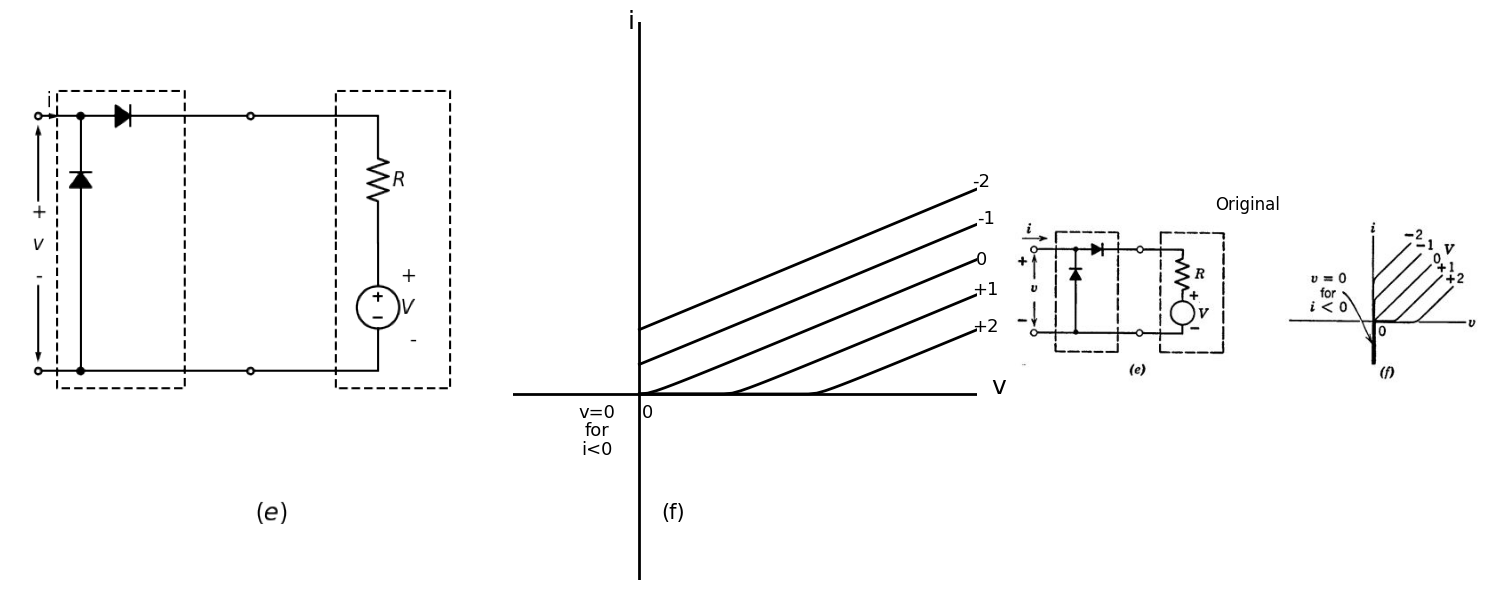

In [351]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
l0 = d.add(elm.Line().right().length(1).dot())
d += elm.Arrow().right().length(0.5).label('i', loc='top', fontsize = 18). at((0,0))
D1 = d.add(elm.Diode(fill=True).right())
d += ( T := dsp.Box(w=3, h=7).anchor('W').linestyle('--').at((0.45,-2.9)))
l1 = d.add(elm.Line().right().length(1.5).dot(open=True))
l2 = d.add(elm.Line().right())
d += ( R1 := elm.Resistor().down().label(['$R$'] , ofst=-0.9 , fontsize = 18))
d += ( V := elm.SourceV().down().reverse().label(['+','$V$','-'] , ofst=-1.4 , fontsize = 18))
l3 = d.add(elm.Line().left().dot(open=True))
l4 = d.add(elm.Line().left().length(4).dot())
l5 = d.add(elm.Line().left().length(1).dot(open=True))
l6 = d.add(elm.Line().up().at(l4.end))
D2 = d.add(elm.Diode(fill=True).up())
d += elm.Gap().up().at((-1,-4.5)).label(['-' , '$v$' , '+'], ofst=-1 , fontsize = 18)
d += elm.Arrow().right().length(1.8).at((0,-2)).color('black').up()
d += elm.Arrow().left().length(1.8).at((0,-4)).color('black').down()
d += ( T := dsp.Box(w=2.7, h=7).anchor('W').linestyle('--').at((7,-2.9)))
d += elm.Gap().up().at((5.5,-10.5)).label('$(e)$'  , fontsize = 22)
d.save('./Drawings/fig10.png')
d.save('./Drawings/fig10.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig10.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display

#rcParams['font.weight'] = 'bold'

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 5@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 0@u_V)
circuit.D(2,circuit.gnd ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 2@u_V)
circuit.D(2,circuit.gnd ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 4@u_V)
circuit.D(2,circuit.gnd ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, -2@u_V)
circuit.D(2,circuit.gnd ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, -4@u_V)
circuit.D(2,circuit.gnd ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

axs[1].text(8.2, 0.28, '+1', ha='center', va='center', fontsize = 13)
axs[1].text(8.2, 0.18, '+2', ha='center', va='center', fontsize = 13)
axs[1].text(8.1, 0.36, '0', ha='center', va='center', fontsize = 13)
axs[1].text(8.2, 0.47, '-1', ha='center', va='center', fontsize = 13)
axs[1].text(8.1, 0.57, '-2', ha='center', va='center', fontsize = 13)
axs[1].text(0.2, -0.05, '0', ha='center', va='center', fontsize = 13)
axs[1].text(-1, -0.05, 'v=0', ha='center', va='center', fontsize = 13)
axs[1].text(-1, -0.1, 'for', ha='center', va='center', fontsize = 13)
axs[1].text(-1, -0.15, 'i<0', ha='center', va='center', fontsize = 13)
axs[1].text(-0.2, 1, 'i', ha='center', va='center', fontsize = 18)
axs[1].text(8.5, 0.02, 'v', ha='center', va='center', fontsize = 18)
axs[1].text(0.8, -0.32, '(f)', ha='center', va='center', fontsize=15)

axs[1].axhline(0, color='black',linewidth=2, ls='-')
axs[1].axvline(0, color='black',linewidth=2, ls='-')
axs[1].set_xlim(-3,8)
axs[1].set_ylim(-0.5, 1)
axs[1].axis('off')  # Hide axes for image display

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/10.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig.  7.3.	Ideal control valves and associated curves.(e),(f)

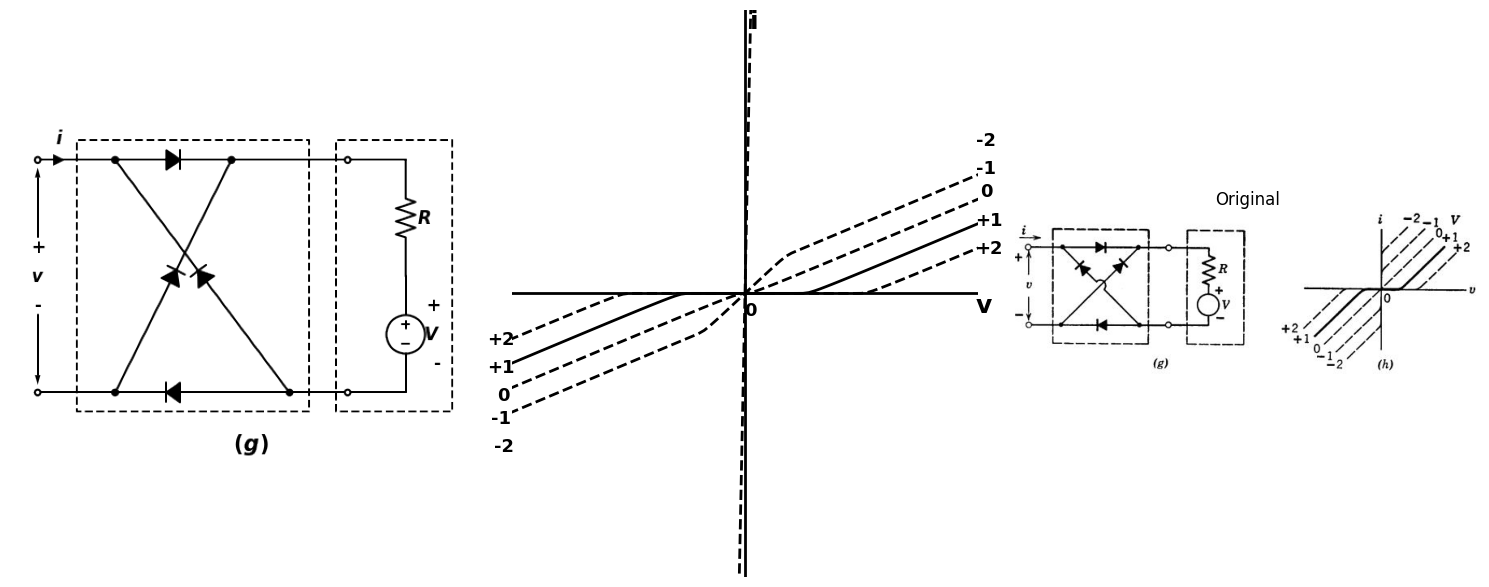

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
l0 = d.add(elm.Line().right().length(1))
l1 = d.add(elm.Line().right().length(1).dot())
d += ( T := dsp.Box(w=6, h=7).anchor('W').linestyle('--').at((1,-3)))
d += elm.lines.CurrentLabelInline().at(l1).right().label('$i$', fontsize = 18)
d += elm.Gap().up().at((-1,-4.5)).label(['-' , '$v$' , '+'], ofst=-1 , fontsize = 18)
D1 = d.add(elm.Diode(fill=True).right().at(l1.end).dot())
l2 = d.add(elm.Line().right().length(1.5))
l3 = d.add(elm.Line().right().length(1.5).dot(open=True))
l9 = d.add(elm.Line().right().length(1.5))
d += ( R1 := elm.Resistor().down().label(['$R$'] , ofst=-0.9 , fontsize = 18))
d += ( V := elm.SourceV().down().reverse().label(['+','$V$','-'] , ofst=-1.4 , fontsize = 18))
d += elm.Dot(open=True).at((0,-6))
l4 = d.add(elm.Line().right().length(1))
l5 = d.add(elm.Line().right().length(1).dot())
D2 = d.add(elm.Diode(fill=True).right().reverse())
l6 = d.add(elm.Line().right().length(1.5).dot())
l7 = d.add(elm.Line().right().length(1.5).dot(open=True))
l8 = d.add(elm.Line().right().length(1.5))
D3 = d.add(elm.Diode(fill=True).endpoints(l5.end,D1.end))
D4 = d.add(elm.Diode(fill=True).endpoints(l6.end,D1.start))
d += elm.Arrow().right().length(1.8).at((0,-2)).color('black').up()
d += elm.Arrow().left().length(1.8).at((0,-4)).color('black').down()
d += ( T := dsp.Box(w=3, h=7).anchor('W').linestyle('--').at((7.7,-3)))
d += elm.Gap().up().at((5.5,-8.5)).label('$(g)$'  , fontsize = 22)
d.save('./Drawings/fig11.png')
d.save('./Drawings/fig11.svg')

#rcParams['font.weight'] = 'bold'

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 6@u_Ohm)
circuit.V('fixed', '3','4', 0@u_V)
circuit.D(2,'4' ,circuit.gnd, model = 'BAV21')
circuit.D(3,circuit.gnd ,'2', model = 'BAV21')
circuit.D(4,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-10, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='--',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS=100e-5, N=1)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 600@u_Ohm)
circuit.V('fixed', '3','4', 2@u_V)
circuit.D(2,'4' ,circuit.gnd, model = 'BAV21')
circuit.D(3,circuit.gnd ,'2', model = 'BAV21')
circuit.D(4,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-10, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS=100e-5, N=1)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 600@u_Ohm)
circuit.V('fixed', '3','4', 4@u_V)
circuit.D(2,'4' ,circuit.gnd, model = 'BAV21')
circuit.D(3,circuit.gnd ,'2', model = 'BAV21')
circuit.D(4,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-10, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='--',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS=100e-5, N=1)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 600@u_Ohm)
circuit.V('fixed', '3','4', -2@u_V)
circuit.D(2,'4' ,circuit.gnd, model = 'BAV21')
circuit.D(3,circuit.gnd ,'2', model = 'BAV21')
circuit.D(4,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-10, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='--',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS=100e-5, N=1)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 600@u_Ohm)
circuit.V('fixed', '3','4', -4@u_V)
circuit.D(2,'4' ,circuit.gnd, model = 'BAV21')
circuit.D(3,circuit.gnd ,'2', model = 'BAV21')
circuit.D(4,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-10, 10, 0.2))
axs[1].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='--',linewidth=2)

axs[1].text(8.4, 0.13, '+1', ha='center', va='center', fontsize = 13)
axs[1].text(8.4, 0.08, '+2', ha='center', va='center', fontsize = 13)
axs[1].text(8.3, 0.18, '0', ha='center', va='center', fontsize = 13)
axs[1].text(8.3, 0.22, '-1', ha='center', va='center', fontsize = 13)
axs[1].text(8.3, 0.27, '-2', ha='center', va='center', fontsize = 13)
axs[1].text(-8.4, -0.13, '+1', ha='center', va='center', fontsize = 13)
axs[1].text(-8.4, -0.08, '+2', ha='center', va='center', fontsize = 13)
axs[1].text(-8.3, -0.18, '0', ha='center', va='center', fontsize = 13)
axs[1].text(-8.4, -0.22, '-1', ha='center', va='center', fontsize = 13)
axs[1].text(-8.3, -0.27, '-2', ha='center', va='center', fontsize = 13)
axs[1].text(0.2, -0.03, '0', ha='center', va='center', fontsize = 13)
axs[1].text(0.3, 0.48, 'i', ha='center', va='center', fontsize = 18)
axs[1].text(8.2, -0.02, 'v', ha='center', va='center', fontsize = 18)
axs[1].axhline(0, color='black',linewidth=2, ls='-')
axs[1].axvline(0, color='black',linewidth=2, ls='-')
axs[1].set_xlim(-8, 8)
axs[1].set_ylim(-0.5,0.5)
axs[1].axis('off')  # Hide axes for image display.text(0.3, 0.48, 'i', ha='center', va='center', fontsize = 18)


# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig11.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/11.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

In [1]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
from matplotlib import rcParams
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()

from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

rcParams['font.weight'] = 'bold'
figure = plt.figure(figsize=(15, 10))


#@interact(Mode1=(True) , Mode2=(True),  Mode3=(True))
@interact(E=widgets.IntSlider(min=-6, max=4, step=1, value=1))
def response(E=1):
    circuit = Circuit('Control Vaves') 
    circuit.model('BAV21','D' ,IS=100e-12, N=1)
    Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
    circuit.D(1,'1' ,'2', model = 'BAV21')
    circuit.R(1, '2', '3', 6@u_Ohm)
    circuit.V('fixed', '3','4', E@u_V)
    circuit.D(2,'4' ,circuit.gnd, model = 'BAV21')
    circuit.D(3,circuit.gnd ,'2', model = 'BAV21')
    circuit.D(4,'4' ,'1', model = 'BAV21')
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vth=slice(-20, 20, 0.2))
    plt.plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)
    plt.axhline(0, color='black',linewidth=2, ls='-')
    plt.axvline(0, color='black',linewidth=2, ls='-')

<Figure size 1500x1000 with 0 Axes>

interactive(children=(IntSlider(value=1, description='E', max=4, min=-6), Output()), _dom_classes=('widget-int…

## Fig.  7.3.Ideal control valves and associated curves.(g),(h)

Two added possibilities, corresponding to the other basic forms of the energy valve, are shown in Fig. 7.3(e) and (g), and the associated curves are given in (f) and (h). The main point here is that resolution of the circuit model into two parts, each having an easily interpretable function, makes the complete circuit appear much less formidable and also suggests the generality of such models for the representation of a wide variety of devices.

# 7.5	The Pentode

From generalities we now shift to the discussion of some specific electronic devices. The first of these is the pentode, a triode with two additional grids. Development of the pentode arose from the desire to overcome certain disadvantages inherent in the vacuum triode. Figure 7.4(a) shows a simple triode amplifier with the grid-to-plate interelectrode capacitance C placed in evidence as a circuit element. At high frequencies the susceptance of this capacitance becomes appreciable.

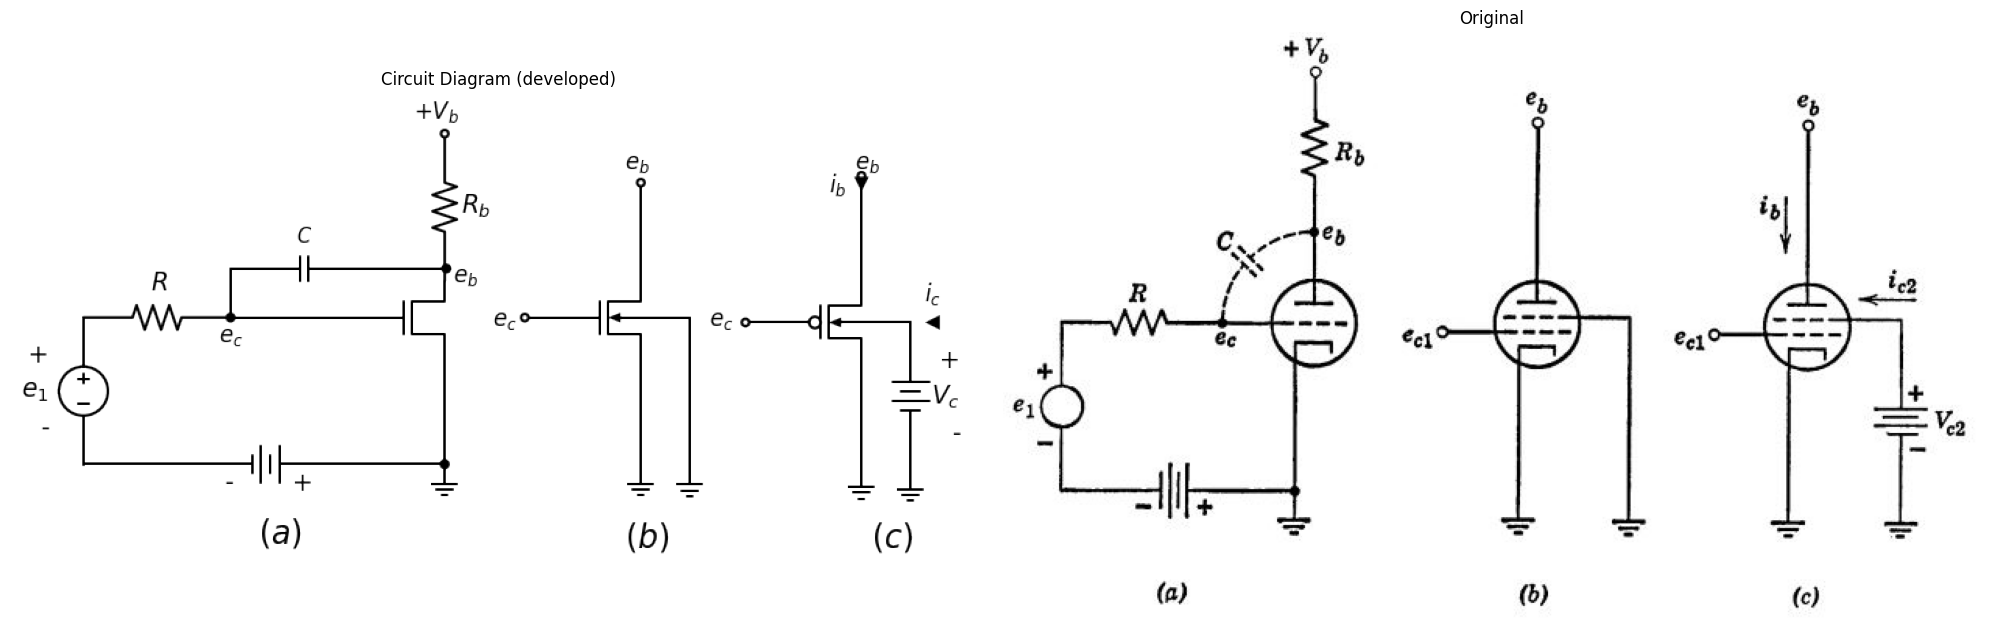

In [222]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(20, 15))
    
d = schemdraw.Drawing()
d.push()
d += ( V1 := elm.SourceV().up().label(['-','$e_1$','+'] , ofst=0.2 , fontsize = 20))
d += ( R1 := elm.Resistor().right().label(['$R$'] , ofst=0.2 , fontsize = 20).dot())
l0 = d.add(elm.Line().right())
d += (M1 := elm.NFet(offset_gate = False).anchor('gate').reverse())
l1 = d.add(elm.Line().down().length(2.24).at(M1.source).dot())
l2 = d.add(elm.Line().left().length(2.15))
d += ( E1 := elm.Battery().left().label(['+','','-'] , ofst=-1,fontsize = 20))
l3 = d.add(elm.Line().left().length(2.2))
d += elm.Ground().at(l1.end)
d += ( R2 := elm.Resistor().up().at(M1.drain).label(['$R_b$'] , ofst=-1.2 , fontsize = 20).dot(open=True))
l4 = d.add(elm.Line().up().length(1).at(R1.end))
C1 = d.add(elm.Capacitor().right().label(['$C$'] , ofst=0.2 , fontsize = 16))
l5 = d.add(elm.Line().length(1.4).right().dot())
d += elm.Gap().up().at((3,1.37)).label('$ e_c $'  , fontsize = 18)
d += elm.Gap().up().at((7.8,2.6)).label('$ e_b $'  , fontsize = 18)
d += elm.Gap().up().at((7.2,6)).label('$ +V_b $'  , fontsize = 18)
d += elm.Gap().up().at((4,-2.5)).label('$ (a) $'  , fontsize = 25)
d.push()
d.move(5, 2.5)
d += elm.Dot(open=True)
l6 = d.add(elm.Line().right().length(1))
d += (M2 := elm.NFet(bulk = True).anchor('gate').reverse())
l7 = d.add(elm.Line().down().length(2.24).at(M2.source))
d += elm.Ground()
l8 = d.add(elm.Line().up().length(2).at(M2.drain).dot(open=True))
l9 = d.add(elm.Line().right().length(1).at(M2.bulk))
l10 = d.add(elm.Line().down())
d += elm.Ground()
d += elm.Gap().up().at((11.3,4.9)).label('$ e_b $'  , fontsize = 18)
d += elm.Gap().up().at((8.6,1.7)).label('$ e_c $'  , fontsize = 18)
d += elm.Gap().up().at((11.5,-2.6)).label('$ (b) $'  , fontsize = 25)
d.push()
d.move(2, 2.5)
d += elm.Dot(open=True)
l11 = d.add(elm.Line().right().length(1))
d += (M3 := elm.PFet(bulk = True).anchor('gate').reverse())
l12 = d.add(elm.Line().up().length(2.24).at(M3.source).dot(open=True))
l13 = d.add(elm.Line().right().length(1).at(M3.bulk))
d += ( E2 := elm.Battery().down().label(['+','$ V_c $','-'] , ofst=-1.4,fontsize = 20))
d += elm.Ground()
l14 = d.add(elm.Line().down().length(2.2).at(M3.drain))
d += elm.Ground()
d += elm.Gap().up().at((16,4.9)).label('$ e_b $'  , fontsize = 18)
d += elm.Gap().up().at((13,1.7)).label('$ e_c $'  , fontsize = 18)
d += elm.Gap().up().at((16.5,-2.6)).label('$ (c) $'  , fontsize = 25)
d += elm.lines.CurrentLabelInline().at(l12).down().label('$i_b$', fontsize = 18)
d += elm.lines.CurrentLabelInline().at(l13).left().label('$i_c$', fontsize = 18)

d.save('./Drawings/fig12.png')
d.save('./Drawings/fig12.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig12.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/12.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7.4.Transition	from	triode	to	tetrode.	(a) Grid-to-plate	interelectrode capacitance which reduces triode gain at high frequencies; (b) Introduction of a screen grid to shield the plate from the control grid; (c) Addition of a screen-grid supply voltage to maintain the flow of plate current.

Signal current flowing in the capacitor must also flow through the source resistance **R** and the resulting voltage drop from **e1** to **ec** reduces the voltage amplification between **e1** and the output **eb**, The loss of amplification is aggravated by the so-called "Miller effect."  The essence of the Miller effect is as follows.  For one volt of **a-c** signal at the grid **a** considerably larger **a-c** signal appears at the plate, say **A** volts, and the polarity of the plate signal is opposite to that of the grid signal. Hence the voltage across the capacitance **C** is larger than the grid signal by a factor **1 + A**. and the capacitive current is therefore **(1 + A)**  times greater than it would be with the same capacitance connected between grid and cathode. The capacitance C therefore has an effect comparable to that of a larger capacitance **C. (1 + A)** between grid and cathode. Thus we see that grid-to-plate capacitance severely limits the operation of a vacuum triode as a high-frequency voltage amplifier.

The capacitance between grid and plate can be greatly reduced by the insertion of an electrostatic shield or screen between the grid and the plate as indicated in Fig. 7.4.(b). This shield cannot, of course, be a solid sheet, for then no current could flow between cathode and plate. Hence a perforated screen is used and this is called the screen grid. If we experiment upon the circuit shown in Fig. 7.4(b), we find that the capacitance between the control grid and the plate is indeed very small, but that hardly any plate current flows unless the plate voltage is raised to a tremendously high value. The reason is that the grounded screen grid not only shields the plate from the control grid but also further shields the plate from the cathode, thereby eliminating the motive force for normal current flow in the tube. The remedy is shown in Fig. 7.4(c). Here the screen grid is held at some fixed positive potential which produces much the same electric field in the region between the screen grid and the cathode as that in a triode. The cathode, control grid, and screen grid are in fact a triode; a triode with holes in its "plate." The large majority of electrons pass through the openings between the screen-grid wires into thedriftspace beyond and are eventually collected by the true plate of the tube.

The tube in Fig. 7.4(c) has four electrodes and is therefore called a tetrode. In examining its properties we shall find reasons for the introduction of still another grid and the tube will then become a pentode. Figure 7.5(a) shows the variation of electric potential between the cathode and plate of a plane-parallel tetrode. Conditions within the "electron gun" portion of the tetrode are much the same as those in a triode. The "gun" shoots electrons through the drift space and into the plate. The "muzzle velocity" of the electron gun is mainly determined by the screen-grid voltage V 02 whereas the number of bullets per second (the cathode current) is mainly fixed by the control grid voltage. For the purposes of this discussion we shall hold the control grid at zero voltage.

Because of the  electrostatic shielding effect of the  two grids, the cathode current is influenced very little by variations in the plate voltage, as indicated by the cathode-current curve in Fig. 7.5(b).  



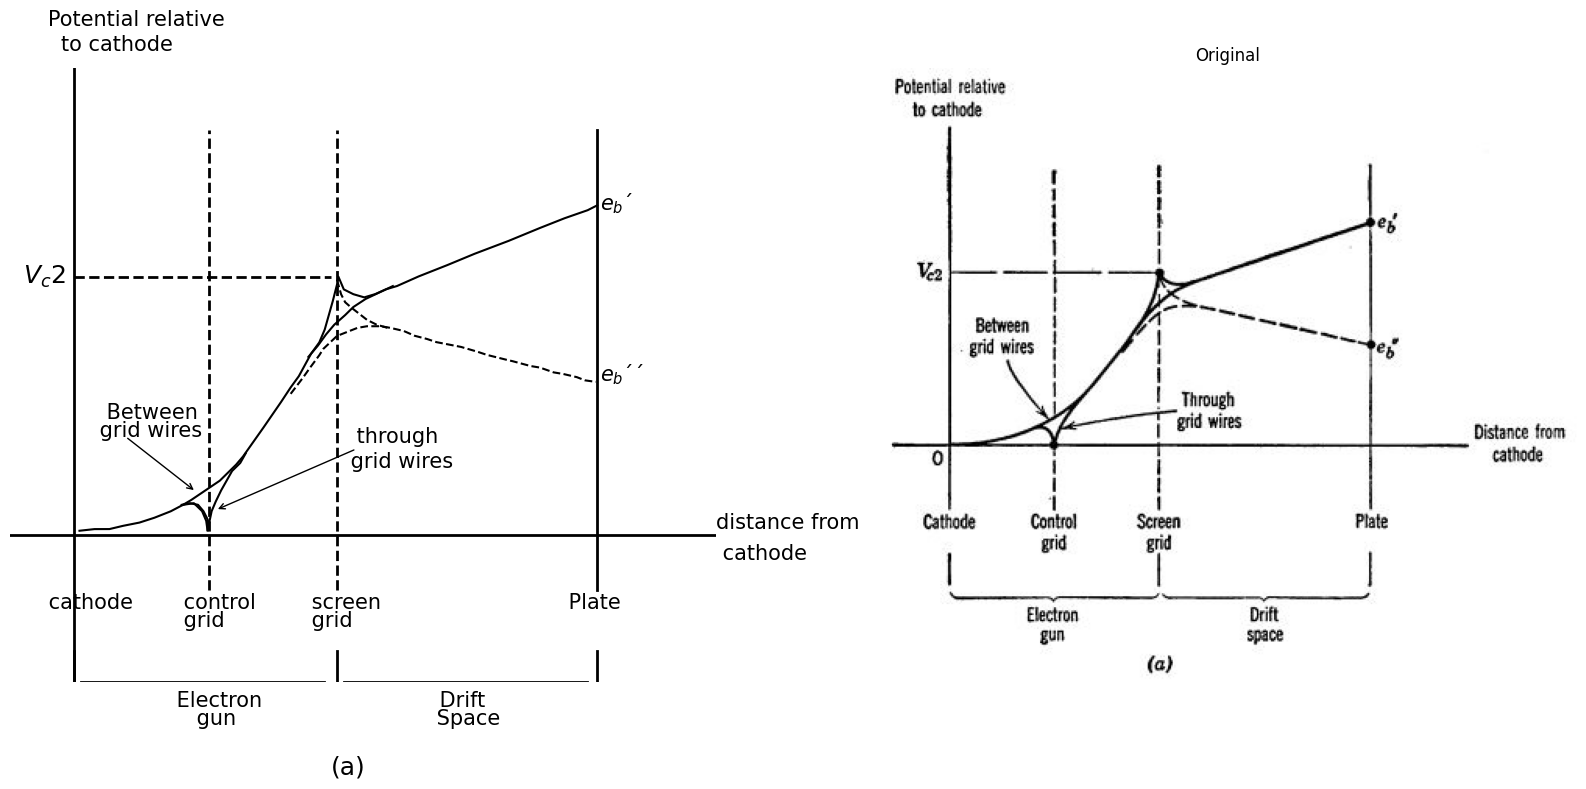

In [150]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(16, 8))
x_values = [0, 4.0]  
y_values = [4.6, 4.6]  

x1_values = [2.1, 2.1]  
y1_values = [-0.5, 7]

x2_values = [4.1, 4.1]  
y2_values = [-0.5, 7]

x3_values = [8.15, 8.15]  
y3_values = [-0.5, 7]

x4_values = [0, 0]  
y4_values = [-2, -1.5]

x5_values = [4.1, 4.1]  
y5_values = [-2, -1.5]

x6_values = [8.15, 8.15]  
y6_values = [-2, -1.5]

x7_values = [0.1, 3.9]  
y7_values = [-2, -2]

x8_values = [4.2, 8.0]  
y8_values = [-2, -2]

#Data
P1 = [0.083011583,0.316602317,0.55019305,0.762548263,1.017374517,1.250965251,1.505791506,1.696911197,1.866795367,1.994208494,2.057915058,2.079150579]
F1 = [0.465166786,0.491885158,0.492440738,0.545271393,0.598203062,0.677247014,0.782504265,0.887609994,0.914176843,0.783665933,0.626840711,0.469914474]

P2 = [1.696911197,1.824324324,1.972972973,2.121621622,2.27027027,2.397683398,2.525096525,2.631274131,2.94980695,3.225868726,3.374517375,3.501930502,
      3.693050193,3.82046332,3.905405405,3.969111969,4.032818533,4.096525097,4.117760618,4.202702703,4.351351351,4.521235521,4.691119691,4.861003861,
      5.030888031,5.200772201,5.370656371,5.561776062,5.816602317,6.241312741,6.772200772,7.260617761,7.642857143,8.003861004,8.152509653]

F2 = [0.887609994,0.96640141,1.071406124,1.176410838,1.281415552,1.412532549,1.543649547,1.674716037,2.146403879,2.565665125,2.801483793,2.984926372,
      3.351660007,3.535102586,3.744606941,3.980223579,4.215840217,4.477619646,4.608484107,4.399383811,4.32124899,4.269327467,4.322057107,4.400949538,
      4.453679178,4.532571608,4.611464039,4.690406977,4.795664227,4.979813909,5.190378917,5.400842911,5.558728787,5.690401365,5.769243288]

P3 = [3.650579151,3.799227799,3.926640927,4.054054054,4.223938224,4.351351351,4.542471042,4.754826255,4.967181467]
F3 = [3.299233411,3.482726497,3.666169076,3.823448864,3.980829667,4.111946664,4.243215184,4.34837142,4.453527656 ]

P4 = [1.675675676,1.803088803,1.930501931,2.015444015,2.079150579,2.079150579,2.142857143,2.206563707,2.291505792,2.376447876,2.461389961,2.588803089,
      2.673745174]
F4 = [0.887559486,0.914025321,0.888165574,0.783716441,0.653054009,0.469914474,0.784019485,0.941147751,1.124489315,1.281668088,1.438846862,1.569963859,
      1.727142633]
P5 = [3.374517375,3.565637066,3.671814672,3.82046332,3.884169884,4.096525097,4.223938224,4.415057915,4.563706564,4.776061776,4.924710425,5.137065637,
      5.306949807,5.498069498,5.646718147,5.901544402,6.028957529,6.283783784,6.432432432,6.72972973,6.835907336,7.111969112,7.260617761,7.472972973,
      7.621621622,7.833976834,7.961389961,8.131274131]    
F5 = [2.69683263,2.958915103,3.116144384,3.32580026,3.430602945,3.640410344,3.693038969,3.771981907,3.798498249,3.799003322,3.773194083,3.721373575,
      3.643289261,3.591418245,3.539446215,3.487726722,3.461866975,3.383984691,3.332012661,3.254231391,3.228321137,3.15048936,3.12468012,3.046696821,
      3.020887582,2.969067074,2.917044536,2.891285804] 
P6 = [4.096525097,4.16023166,4.223938224,4.308880309,4.436293436,4.563706564,4.712355212,4.882239382]
F6 = [4.556108018,4.320794424,4.190131992,4.11184565,4.007497531,3.903149412,3.825014591,3.773093068]

axs[0].plot(P1, F1, 'black',linestyle='-')
axs[0].plot(P2, F2, 'black',linestyle='-')
axs[0].plot(P3, F3, 'black',linestyle='-')
axs[0].plot(P4, F4, 'black',linestyle='-')
axs[0].plot(P5, F5, 'black',linestyle='--')
axs[0].plot(P6, F6, 'black',linestyle='--')
axs[0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
axs[0].plot(x2_values, y2_values, ls='--', color='black', linewidth=2)
axs[0].plot(x3_values, y3_values, ls='-', color='black', linewidth=2)
axs[0].plot(x4_values, y4_values, ls='-', color='black', linewidth=2)
axs[0].plot(x5_values, y5_values, ls='-', color='black', linewidth=2)
axs[0].plot(x6_values, y6_values, ls='-', color='black', linewidth=2)
axs[0].plot(x7_values, y7_values, ls='-', color='black', linewidth=2)
axs[0].plot(x8_values, y8_values, ls='-', color='black', linewidth=2)
axs[0].axhline(0.4, color='black',linewidth=2, ls='-')
axs[0].axvline(0, color='black',linewidth=2, ls='-')
axs[0].text(-0.4,8.7, 'Potential relative', fontsize=15)
axs[0].text(-0.2,8.3, 'to cathode', fontsize=15)
axs[0].text(-0.8,4.5, '$ V_c2 $', fontsize=18)
axs[0].text(4,-3.5, '(a)', fontsize=18)
axs[0].text(10,0.5, 'distance from', fontsize=15)
axs[0].text(10,0, ' cathode', fontsize=15)
axs[0].text(8.2,5.7, '$ e_b´ $', fontsize=15)
axs[0].text(8.2,2.9, '$ e_b´´$', fontsize=15)
axs[0].text(-0.5,-0.8, ' cathode', fontsize=15)
axs[0].text(1.6,-0.8, ' control', fontsize=15)
axs[0].text(1.6,-1.1, ' grid', fontsize=15)
axs[0].text(3.6,-0.8, ' screen', fontsize=15)
axs[0].text(3.6,-1.1, ' grid', fontsize=15)
axs[0].text(7.6,-0.8, ' Plate', fontsize=15)
axs[0].text(4.3,1.9, ' through', fontsize=15)
axs[0].text(4.2,1.5, ' grid wires', fontsize=15)
axs[0].text(0.4,2.3, ' Between', fontsize=15)
axs[0].text(0.3,2, ' grid wires', fontsize=15)
axs[0].text(1.5,-2.4, ' Electron', fontsize=15)
axs[0].text(1.8,-2.7, ' gun', fontsize=15)
axs[0].text(5.6,-2.4, ' Drift', fontsize=15)
axs[0].text(5.55,-2.7, ' Space', fontsize=15)
axs[0].annotate('', xy=(1.9, 1.1), xytext=(0.8, 2.0), arrowprops=dict(arrowstyle='->'))
axs[0].annotate('', xy=(4.4, 1.8), xytext=(2.2, 0.8), arrowprops=dict(arrowstyle='<-'))
axs[0].set_xlim(-1, 10)
axs[0].set_ylim(-2.0,8)
axs[0].axis('off')

img_sample = mpimg.imread('images/13.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 


**Fig. 7.5.**	Tetrode curves.	(a) Electric potential in a planirparallel tetrode.


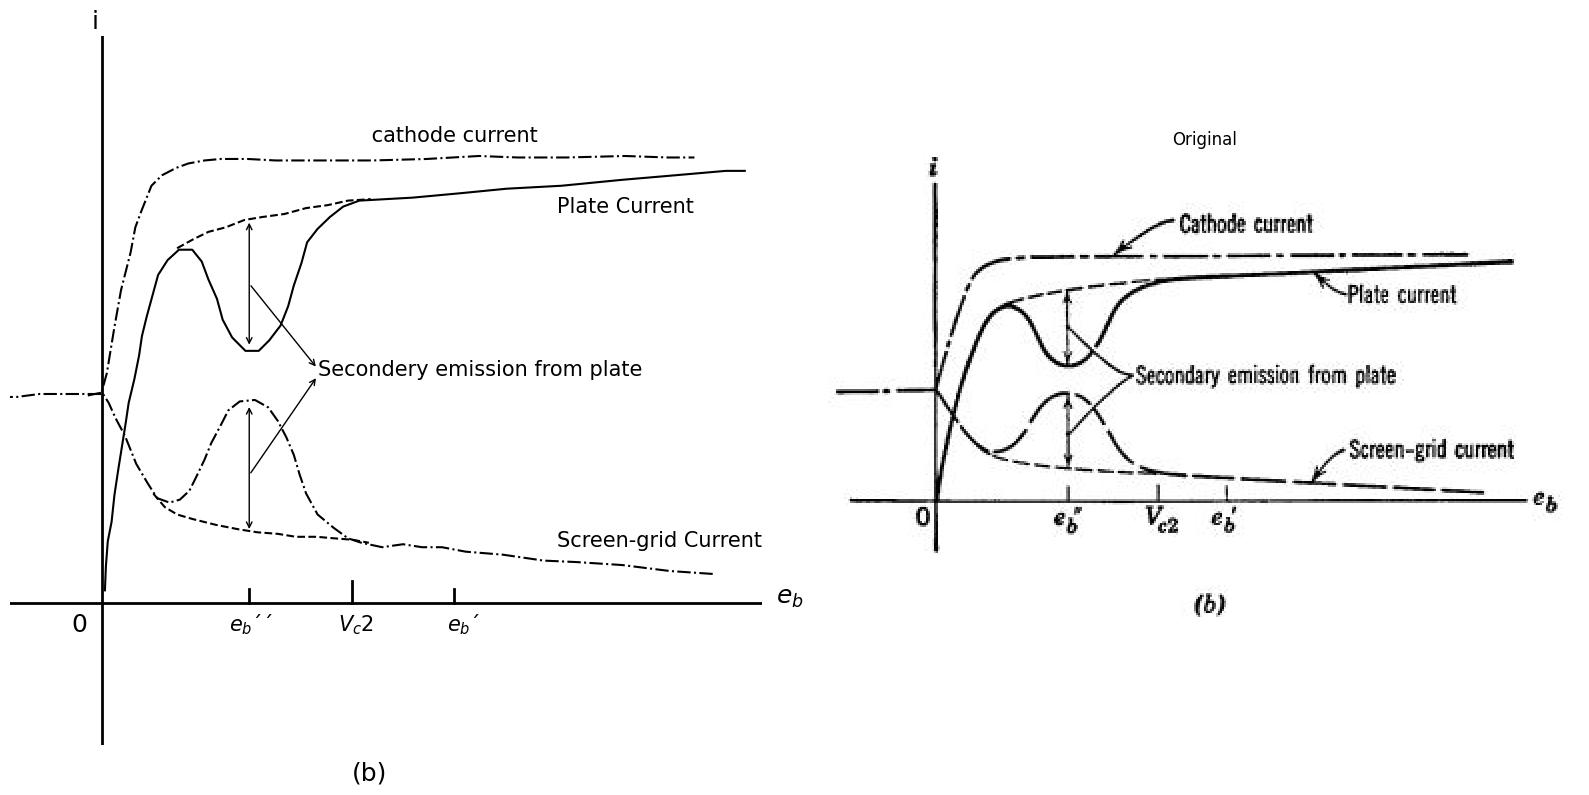

In [219]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(16, 8)) 

x_values = [2.5, 2.5]  
y_values = [0, 0.2]  

x1_values = [4, 4]  
y1_values = [0, 0.3]

x2_values = [5.5, 5.5]  
y2_values = [0, 0.2]
#Data
P1 = [-1.152777778,-0.902777778,-0.569444444,-0.111111111,0.333333333,0.416666667,0.527777778,0.625,0.763888889,0.833333333,0.930555556,1.069444444,
      1.222222222,1.430555556,1.611111111,1.847222222,2.083333333,2.472222222,2.888888889,3.402777778,4.305555556,5.097222222,5.861111111,6.430555556
      ,7.138888889,8,8.625,9.013888889]
F1 = [2.902097902,2.902097902,2.944055944,2.944055944,2.944055944,3.237762238,3.888111888,4.412587413,4.937062937,5.293706294,5.545454545,5.881118881
      ,6.027972028,6.132867133,6.195804196,6.237762238,6.258741259,6.258741259,6.237762238,6.237762238,6.237762238,6.258741259,6.300699301,6.27972028
      ,6.27972028,6.300699301,6.27972028,6.27972028]

P2 = [0.388888889,0.402777778,0.430555556,0.486111111,0.527777778,0.583333333,0.638888889,0.694444444,0.736111111,0.819444444,0.888888889,0.930555556
      ,1,1.083333333,1.166666667,1.305555556,1.472222222,1.666666667,1.805555556,1.902777778,2.027777778,2.111111111,2.25,2.444444444,2.638888889,
      2.791666667,2.958333333,3.069444444,3.152777778,3.263888889,3.347222222,3.5,3.680555556,3.875,4.111111111,4.888888889,5.597222222,6.263888889
      ,7.069444444,7.958333333,8.722222222,9.472222222,9.75]
F2 = [0.174825175,0.51048951,0.867132867,1.13986014,1.517482517,1.874125874,2.20979021,2.545454545,2.818181818,3.153846154,3.48951049,3.762237762
      ,4.034965035,4.328671329,4.622377622,4.832167832,4.979020979,4.979020979,4.811188811,4.559440559,4.286713287,3.993006993,3.741258741,3.552447552
      ,3.552447552,3.699300699,3.909090909,4.181818182,4.475524476,4.79020979,5.083916084,5.272727273,5.440559441,5.587412587,5.671328671,5.713286713
      ,5.776223776,5.839160839,5.881118881,5.965034965,6.027972028,6.090909091,6.090909091]

P3 = [1.444444444,1.680555556,1.902777778,2.152777778,2.430555556,2.694444444,3.013888889,3.333333333,3.652777778,3.944444444,4.277777778]
F3 = [5,5.125874126,5.230769231,5.293706294,5.398601399,5.440559441,5.482517483,5.566433566,5.608391608,5.671328671,5.692307692]

P4 = [0.138888889,0.347222222,0.444444444,0.541666667,0.680555556,0.847222222,1.013888889,1.152777778,1.333333333,1.486111111,1.625,1.722222222,1.847222222
      ,1.944444444,2.083333333,2.194444444,2.361111111,2.583333333,2.777777778,2.916666667,3.041666667,3.152777778,3.236111111,3.333333333,3.5,3.736111111
      ,3.944444444,4.138888889,4.444444444,4.75,5.027777778,5.319444444,5.666666667,6.208333333,6.805555556,7.291666667,7.958333333,8.652777778,9.291666667]
F4 = [2.923076923,2.965034965,2.818181818,2.608391608,2.356643357,1.958041958,1.685314685,1.475524476,1.412587413,1.454545455,1.58041958,1.769230769,
      2.020979021,2.251748252,2.503496503,2.713286713,2.839160839,2.86013986,2.755244755,2.566433566,2.335664336,2.083916084,1.811188811,1.538461538,
      1.244755245,1.055944056,0.909090909,0.846153846,0.783216783,0.825174825,0.783216783,0.783216783,0.72027972,0.678321678,0.594405594,0.573426573
      ,0.531468531,0.447552448,0.405594406]

P5 = [1.097222222,1.263888889,1.444444444,1.666666667,2.013888889,2.347222222,2.625,2.916666667,3.180555556,3.486111111,3.736111111,4.013888889,4.25]

F5 = [1.538461538,1.34965035,1.244755245,1.181818182,1.097902098,1.034965035,0.993006993,0.972027972,0.93006993,0.93006993,0.909090909,0.888111888,0.846153846]

axs[0].plot(P1, F1, 'black',linestyle='-.')
axs[0].plot(P2, F2, 'black',linestyle='-')
axs[0].plot(P3, F3, 'black',linestyle='--')
axs[0].plot(P4, F4, 'black',linestyle='-.')
axs[0].plot(P5, F5, 'black',linestyle='--')
axs[0].plot(x_values, y_values, ls='-', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='-', color='black', linewidth=2)
axs[0].plot(x2_values, y2_values, ls='-', color='black', linewidth=2)
axs[0].axhline(0, color='black',linewidth=2, ls='-')
axs[0].axvline(0.35, color='black',linewidth=2, ls='-')
axs[0].text(-0.1,-0.4, '0', fontsize=18)
axs[0].text(0.2,8.1, 'i', fontsize=18)
axs[0].text(3.8,-0.4, '$ V_c2 $', fontsize=15)
axs[0].text(4,-2.5, '(b)', fontsize=18)
axs[0].text(3.5,3.2, 'Secondery emission from plate', fontsize=15)
axs[0].text(10.2,0, '$ e_b $', fontsize=18)
axs[0].text(5.4,-0.4, '$ e_b´ $', fontsize=15)
axs[0].text(2.2,-0.4, '$ e_b´´$', fontsize=15)
axs[0].text(4.2,6.5, ' cathode current', fontsize=15)
axs[0].text(7,5.5, 'Plate Current', fontsize=15)
axs[0].text(7,0.8, 'Screen-grid Current', fontsize=15)
axs[0].annotate('', xy=(2.5, 1), xytext=(2.5, 2.8), arrowprops=dict(arrowstyle='<->'))
axs[0].annotate('', xy=(2.5, 3.6), xytext=(2.5, 5.4), arrowprops=dict(arrowstyle='<->'))
axs[0].annotate('', xy=(3.5, 3.3), xytext=(2.5, 4.5), arrowprops=dict(arrowstyle='->'))
axs[0].annotate('', xy=(3.5, 3.2), xytext=(2.5, 1.8), arrowprops=dict(arrowstyle='->'))
axs[0].set_xlim(-1, 10)
axs[0].set_ylim(-2.0,8)
axs[0].axis('off')

img_sample = mpimg.imread('images/14.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

**Fig. 7.5.** Tetrode curves.	(b) Current versus plate voltage for **ec1 = 0** and **ec2 = Vc2 = constant**.

  The screengrid current decreases slightly with increasing plate voltage because of minor modifications in the electric field pattern near the screen-grid wires. When the plate beckons more strongly, the electrons are not quite as likely to be captured by a screen-grid wire. Hence, plate current increases slightly with increasing plate voltage, screen-grid current decreases, and cathode current remains essentially unchanged, a,g shown in Fig. 7.5(b).
The kinetic energy of an electron is proportional to the height of the potential curve in Fig. 7.5(a), hence the electrons strike the plate with considerable speed.  


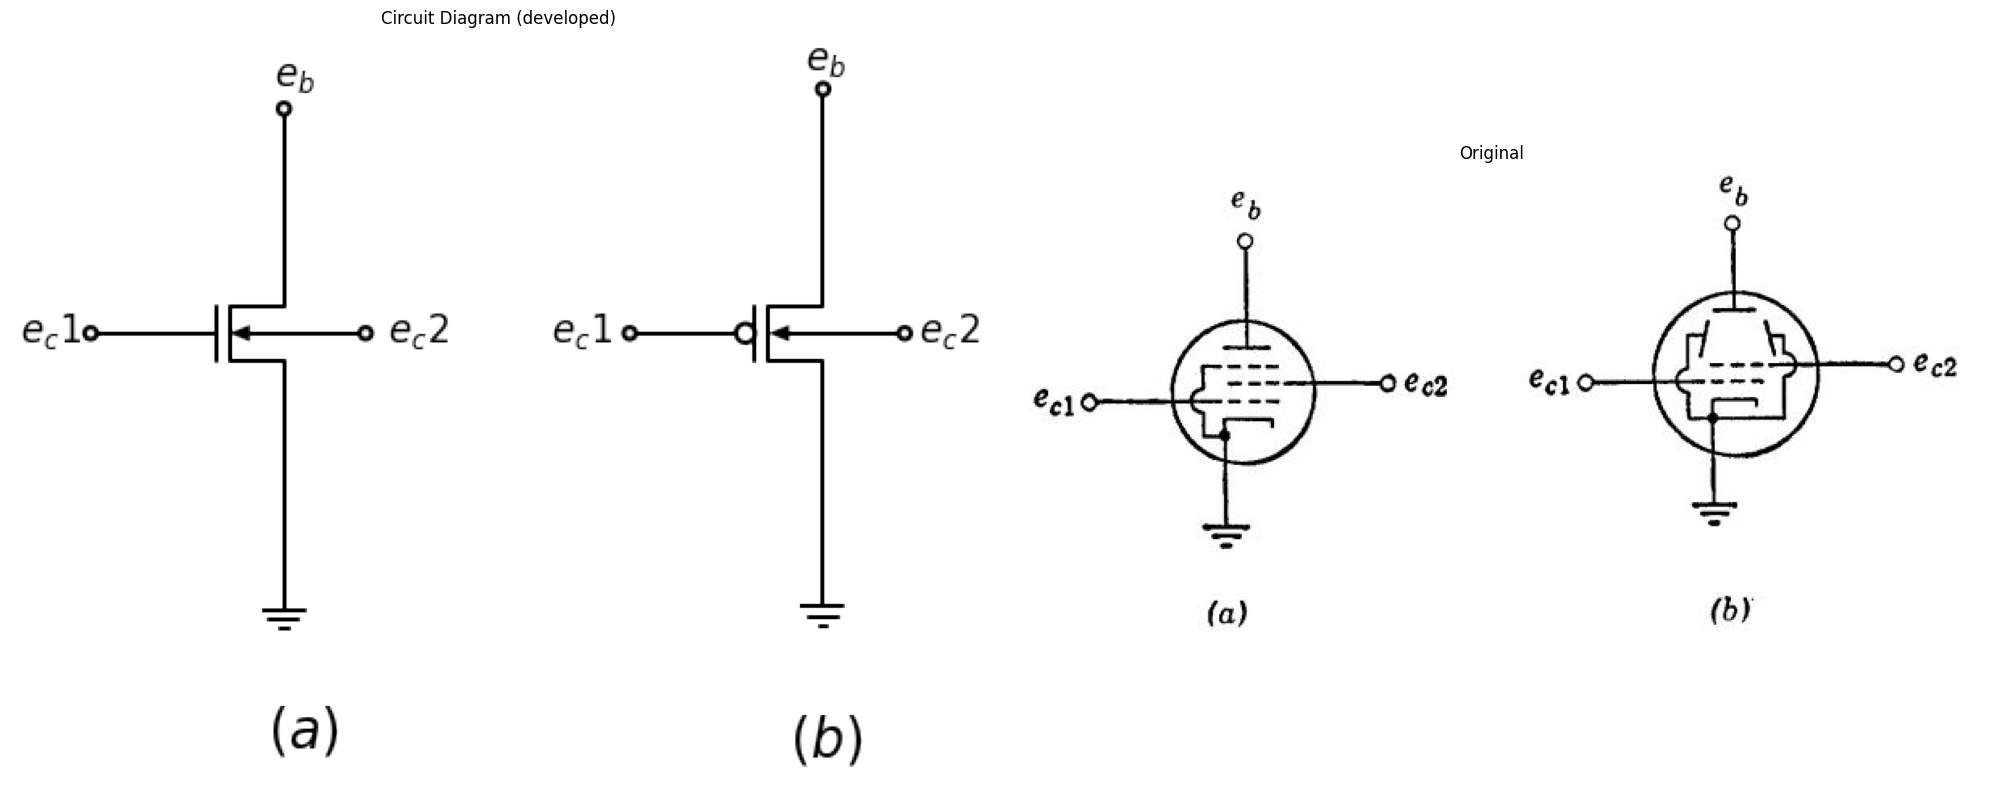

In [270]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(20, 15))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
l6 = d.add(elm.Line().right().length(1))
d += (M2 := elm.NFet(bulk = True).anchor('gate').reverse())
l7 = d.add(elm.Line().down().length(2.24).at(M2.source))
d += elm.Ground()
l8 = d.add(elm.Line().up().length(2).at(M2.drain).dot(open=True))
l9 = d.add(elm.Line().right().length(1).at(M2.bulk).dot(open=True))
d += elm.Gap().up().at((2.5,1.9)).label('$ e_b $'  , fontsize = 18)
d += elm.Gap().up().at((-0.5,-1.2)).label('$ e_c1 $'  , fontsize = 18)
d += elm.Gap().up().at((4,-1.2)).label('$ e_c2 $'  , fontsize = 18)
d += elm.Gap().up().at((2.6,-6)).label('$ (a) $'  , fontsize = 25)
d.push()
d.move(4, 3)
d += elm.Dot(open=True)
l11 = d.add(elm.Line().right().length(1))
d += (M3 := elm.PFet(bulk = True).anchor('gate').reverse())
l12 = d.add(elm.Line().up().length(2.24).at(M3.source).dot(open=True))
l13 = d.add(elm.Line().right().length(1).at(M3.bulk).dot(open=True))
l14 = d.add(elm.Line().down().length(2.2).at(M3.drain))
d += elm.Ground()
d += elm.Gap().up().at((9,2.1)).label('$ e_b $'  , fontsize = 18)
d += elm.Gap().up().at((6.0,-1.2)).label('$ e_c1 $'  , fontsize = 18)
d += elm.Gap().up().at((10.5,-1.2)).label('$ e_c2 $'  , fontsize = 18)
d += elm.Gap().up().at((9.0,-6.1)).label('$ (b) $'  , fontsize = 25)

d.save('./Drawings/fig15.png')
d.save('./Drawings/fig15.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig15.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/15.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7.6.Pentode symbols.  (a) Pentode, with suppressor grid internally connected to the cathode; (b) Beam tetrode, with beam-forming electrodes internally connected to the cathode.


When an electron enters the plate, it can "splash" several other electrons out of the plate. Such liberation of electrons by bombardment is called secondary emission. The secondary electrons are emitted with less kinetic energy than that of the impinging electron but this energy frees the secondaries from the attraction of the plate. When the plate voltage is higher than the screen-grid voltage, as in the solid curve of Fig. 7.5(a), the secondary electrons find themselves in an electric field which quickly returns them to the plate.  However, if the plate voltage is reduced from **eb** to a lower value **eb'**, the secondary electrons ride upward along the potential curve and are eventually collected by the screen grid. The result is a dip in the plate-current curve as shown in Fig. 7.5(b). At still lower plate voltages the electrons are greatly decelerated in the drift space and arrive at the plate with insufficient energy to produce appreciable secondary emission. Finally, as the plate voltage is reduced to zero, the plate current is cut off and all "bullets" fall back into the "muzzle" of the "gun." As the electrons are decelerated and turned back from the plate, they return to the screen grid at high velocity and may oscillate through the screen many times before being collected. The electron cloud produces a relatively heavy negative space charge that depresses the potential curve and reduces the cathode current as indicated in  Fig. 7.5(b).

The effects of secondary emission can be suppressed by the introduction of a third grid, called the suppressor grid, between the screen grid and the plate as shown in Fig. 7.6 (a).


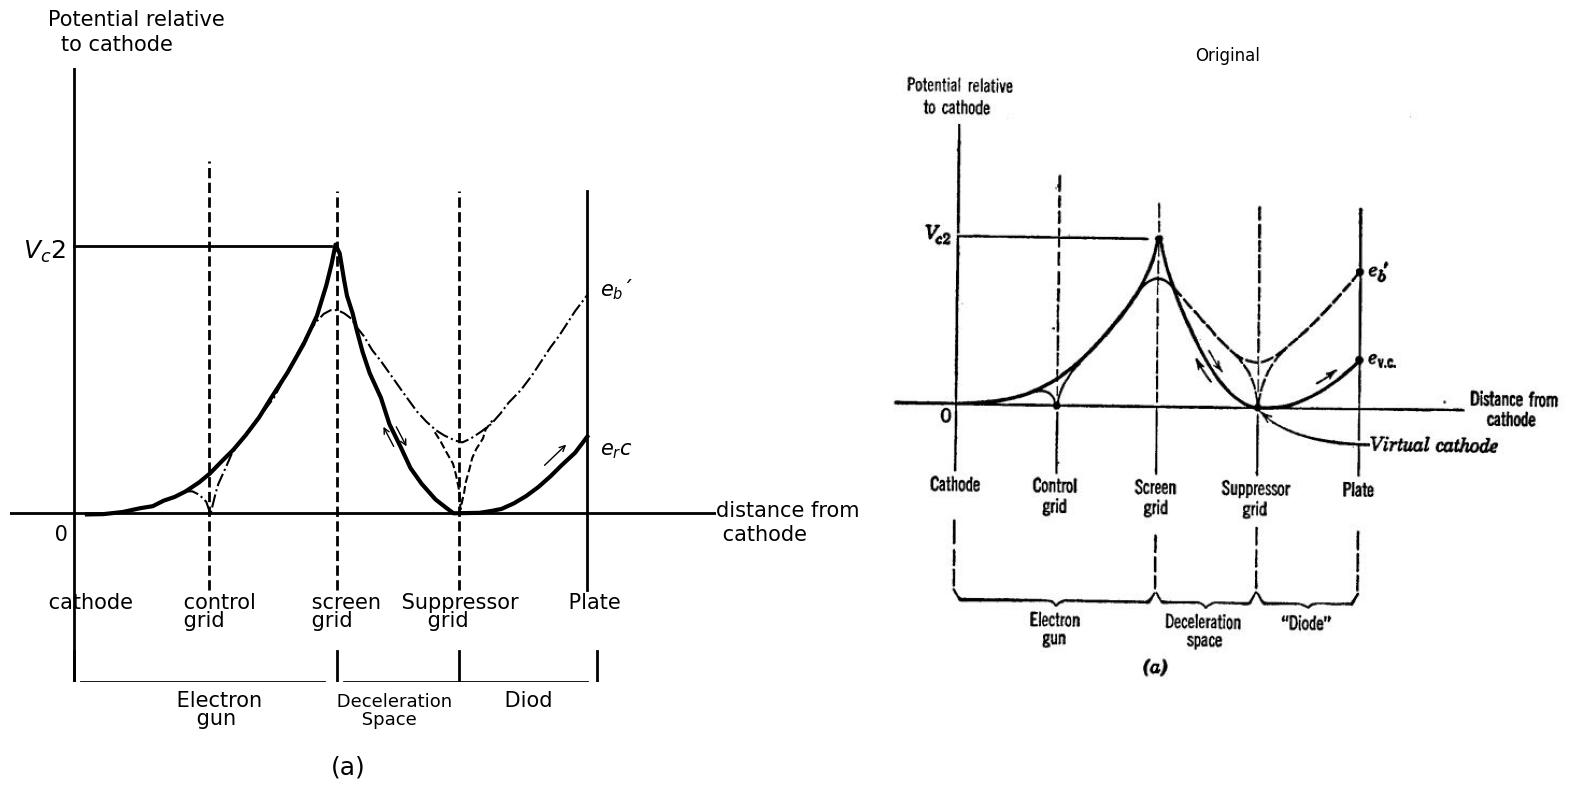

In [367]:

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(16, 8))
x_values = [0, 4.0]  
y_values = [5.1, 5.1]  

x1_values = [2.1, 2.1]  
y1_values = [-0.5, 6.5]

x2_values = [4.1, 4.1]  
y2_values = [-0.5, 6]

x3_values = [8.0, 8.0]  
y3_values = [-0.5, 6]

x4_values = [0, 0]  
y4_values = [-2, -1.5]

x5_values = [4.1, 4.1]  
y5_values = [-2, -1.5]

x6_values = [8.15, 8.15]  
y6_values = [-2, -1.5]

x7_values = [0.1, 3.9]  
y7_values = [-2, -2]

x8_values = [4.2, 8.0]  
y8_values = [-2, -2]

x9_values = [6.0, 6.0]  
y9_values = [-0.5, 6]

x10_values = [6.0, 6.0]  
y10_values = [-2, -1.5]

#Data
P1 = [0.198508691,0.455273199,0.75455747,1.032170378,1.224469438,1.394822814,1.56545051,1.735803885,1.948402703,2.118207437,2.30886057,2.478390982
      ,2.668769795,2.879997007,3.069552857,3.32247687,3.574852241,3.784433527,3.929549365,4.011845682,4.073019277,4.13858201,4.161350657,4.206887952
      ,4.252150926,4.340482306,4.407416644,4.496296666,4.60657373,4.781590563,4.914087633,5.088830145,5.241901294,5.415546522,5.631985835,5.804533779
      ,5.912341954,6.040724208,6.169106462,6.318885758,6.511184818,6.660689793,6.85244021,7.043916307,7.235118083,7.426045537,7.59557595,7.807626125
      ,7.997730617]
F1 = [0.73125265,0.735965984,0.770305993,0.833094342,0.865470461,0.955136038,1.015960498,1.105626075,1.253759445,1.40110726,1.606530088,1.78271902
      ,2.016982967,2.309321928,2.63010923,3.038598219,3.504769446,3.970155116,4.463203571,4.810868101,5.129298736,4.986271478,4.842458665,4.554833038
      ,4.29604853,4.009208459,3.72197561,3.377453303,3.033323774,2.632690341,2.202430235,1.830637921,1.487293947,1.230866106,0.975223821,0.834160453
      ,0.749600988,0.751957655,0.754314322,0.757063767,0.789439886,0.82103045,0.911088805,1.029988279,1.177728871,1.354310581,1.530499514,1.73631512
      ,1.999420185]

P2 = [1.735803885,1.842789097,1.950322951,2.058405447,2.124516821,2.165664979,2.206813137,2.248235617,2.311055139,2.37387466,2.457542582,2.75326068
      ,3.112346941,3.658520163,3.78525649,3.891144418,3.997580987,4.104566199,4.212100052,4.319908227,4.406868002,4.515224819,4.645801641,4.775829821
      ,4.949475049,5.123120277,5.340108232,5.491533455,5.642684356,5.771889573,5.943888875,6.051148408,6.17898202,6.349061074,6.497743086,6.645876456
      ,6.772612783,6.963265917,7.132247687,7.279832415,7.427417143,7.55415347,7.680615477,7.807077483,7.997181975]

F2 = [1.105626075,1.107589965,1.051871618,0.938471034,0.73776154,0.911593805,1.08542607,1.230417217,1.375801142,1.521185067,1.724644006,2.133918552
      ,2.630894785,3.708228385,3.883631761,4.000960124,4.06060625,4.062570139,4.006851792,3.922292326,3.779657847,3.637416145,3.409043866,3.238353824
      ,2.981925983,2.725498142,2.41217362,2.241876356,2.10042021,2.016253523,1.932872391,1.905995162,1.966034066,2.084540762,2.20265468,2.378450834
       ,2.553854211,2.759277039,2.993148208,3.226626599,3.46010499,3.635508367,3.839752862,4.043997357,4.307102422]

P3 = [5.621561635,5.70852141,5.795755505,5.904660964,5.949100975,5.994089628,6.017132597,6.018778523,6.08022644,6.100251877,6.162248435,6.203396593
      ,6.266216115,6.3715554,6.41297788,6.518591486]
F3 = [2.071186314,1.928551834,1.757076236,1.557152298,1.384891144,1.154947754,0.982293823,0.809247113,1.098836629,1.243434998,1.475342278,1.649174543
      ,1.794558468,1.969569067,2.114560213,2.260729694 ]

axs[0].plot(P1, F1, 'black',linestyle='-', linewidth=3)
axs[0].plot(P2, F2, 'black',linestyle='-.')
axs[0].plot(P3, F3, 'black',linestyle='--')
axs[0].plot(x_values, y_values, ls='-', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
axs[0].plot(x2_values, y2_values, ls='--', color='black', linewidth=2)
axs[0].plot(x3_values, y3_values, ls='-', color='black', linewidth=2)
axs[0].plot(x4_values, y4_values, ls='-', color='black', linewidth=2)
axs[0].plot(x5_values, y5_values, ls='-', color='black', linewidth=2)
axs[0].plot(x6_values, y6_values, ls='-', color='black', linewidth=2)
axs[0].plot(x7_values, y7_values, ls='-', color='black', linewidth=2)
axs[0].plot(x8_values, y8_values, ls='-', color='black', linewidth=2)
axs[0].plot(x9_values, y9_values, ls='--', color='black', linewidth=2)
axs[0].plot(x10_values, y10_values, ls='-', color='black', linewidth=2)
axs[0].axhline(0.75, color='black',linewidth=2, ls='-')
axs[0].axvline(0, color='black',linewidth=2, ls='-')
axs[0].text(-0.4,8.7, 'Potential relative', fontsize=15)
axs[0].text(-0.2,8.3, 'to cathode', fontsize=15)
axs[0].text(-0.8,4.9, '$ V_c2 $', fontsize=18)
axs[0].text(4,-3.5, '(a)', fontsize=18)
axs[0].text(10,0.7, 'distance from', fontsize=15)
axs[0].text(10,0.3, ' cathode', fontsize=15)
axs[0].text(8.2,4.3, '$ e_b´ $', fontsize=15)
axs[0].text(8.2,1.7, '$ e_rc$', fontsize=15)
axs[0].text(-0.5,-0.8, ' cathode', fontsize=15)
axs[0].text(1.6,-0.8, ' control', fontsize=15)
axs[0].text(1.6,-1.1, ' grid', fontsize=15)
axs[0].text(3.6,-0.8, ' screen', fontsize=15)
axs[0].text(3.6,-1.1, ' grid', fontsize=15)
axs[0].text(7.6,-0.8, ' Plate', fontsize=15)
axs[0].text(5,-0.8, ' Suppressor', fontsize=15)
axs[0].text(5.4,-1.1, ' grid ', fontsize=15)
axs[0].text(4.0,-2.4, ' Deceleration', fontsize=13)
axs[0].text(-0.4,0.3, ' 0', fontsize=15)
axs[0].text(1.5,-2.4, ' Electron', fontsize=15)
axs[0].text(1.8,-2.7, ' gun', fontsize=15)
axs[0].text(6.6,-2.4, ' Diod', fontsize=15)
axs[0].text(4.4,-2.7, ' Space', fontsize=13)
axs[0].annotate('', xy=(5.2, 1.8), xytext=(5.0, 2.2), arrowprops=dict(arrowstyle='->'))
axs[0].annotate('', xy=(5, 1.8), xytext=(4.8, 2.2), arrowprops=dict(arrowstyle='<-'))
axs[0].annotate('', xy=(7.3, 1.5), xytext=(7.7, 1.9), arrowprops=dict(arrowstyle='<-'))
axs[0].set_xlim(-1, 10)
axs[0].set_ylim(-2.0,8)
axs[0].axis('off')

img_sample = mpimg.imread('images/16.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()



**Fig. 7.7.**  Pentode curves.  (a) Formation of a virtual cathode near the suppressor grid at low plat.o voltage

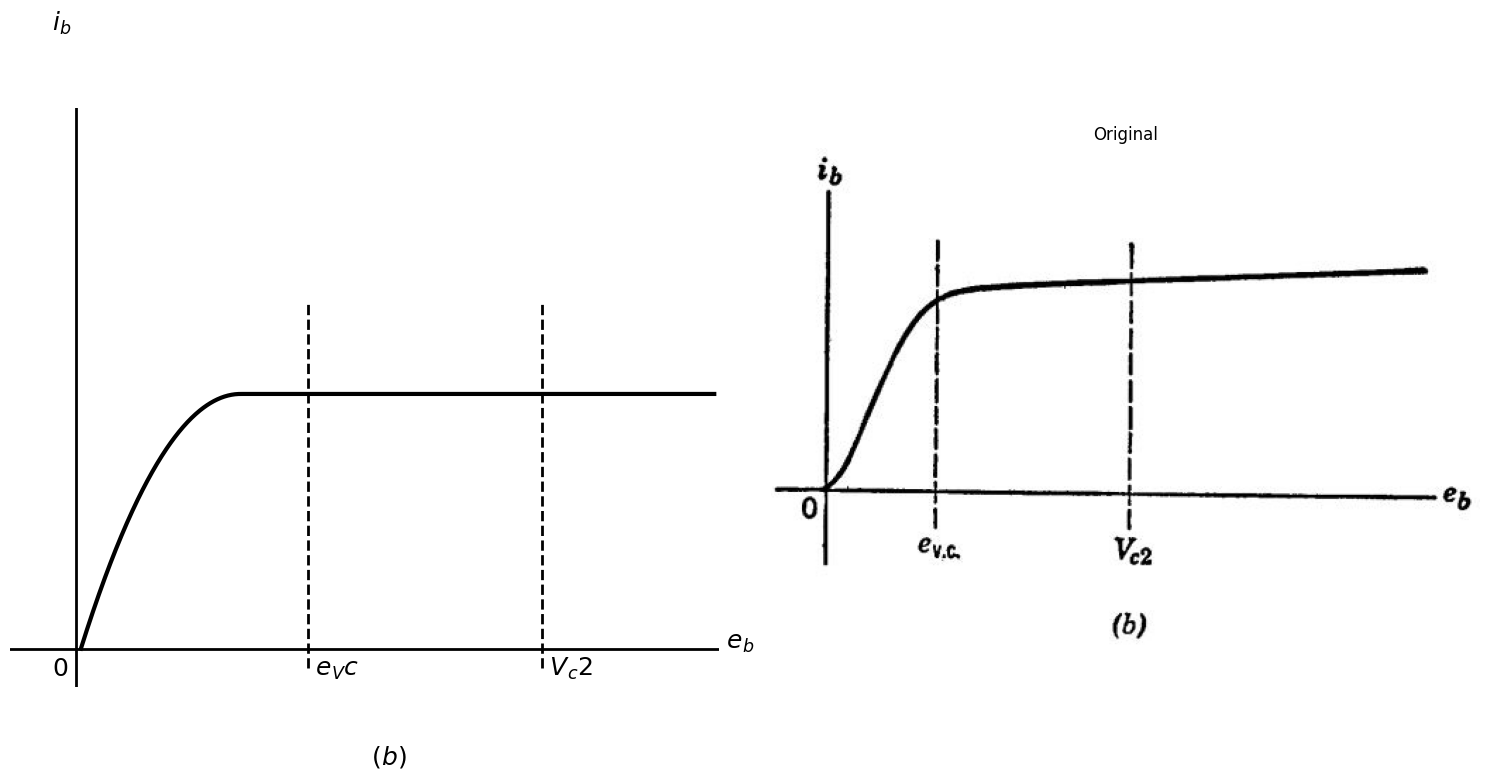

In [562]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Doc.ExampleTools import find_libraries
from PySpice.Probe.Plot import plot
from PySpice.Spice.Library import SpiceLibrary
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

fig, axs = plt.subplots(1, 2, figsize=(15, 8))

x_values = [32, 32]  
y_values = [-5000, 90000]  

x1_values = [65, 65]  
y1_values = [-5000, 90000]

circuit = Circuit('NMOS')
circuit.model('2N7000', 'NMOS', L=100E-6, W=200E-6, Kp=0.13, Vto=2.475)
Vgate = circuit.V('gate','gate',circuit.gnd,   0@u_V)
circuit.R(2, 'drain', '2', 0.01@u_Ohm)
Vi = circuit.V('i', '2', circuit.gnd, 1@u_V)
circuit.MOSFET(1, 'drain', 'gate', circuit.gnd,circuit.gnd, model='2N7000')
for gate_voltage in np.arange(25,30, 5):
    gate_voltage = gate_voltage@u_V
    Vgate.dc_value = gate_voltage
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(0, 90, 0.1))
    axs[0].plot(analysis['drain'], u_mA(-analysis.Vi),linewidth=3, color='black')
    
axs[0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
axs[0].axhline(10, color='black',linewidth=2, ls='-')
axs[0].axvline(-0.63, color='black',linewidth=2, ls='-')
axs[0].axis('off')
axs[0].text(-5,160000, ' $i_b$ ', fontsize=18)
axs[0].text(-5,-7000, ' $0$ ', fontsize=18)
axs[0].text(32,-7000, ' $e_Vc$ ', fontsize=18)
axs[0].text(65,-7000, ' $V_c2$ ', fontsize=18)
axs[0].text(90,0, ' $e_b$ ', fontsize=18)
axs[0].text(40,-30000, ' $(b)$ ', fontsize=18)
axs[0].set_xlim(-10, 90)
axs[0].set_ylim(-10000,140000)

img_sample = mpimg.imread('images/17.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()



## Fig. 7.7.Pentode curves.   (b) Pentode plate curve for **ec1 = 0** and **ec2 = Vc2**

In most pentodes the suppressor is internally connected to the cathode.	The induced negative charge on the suppressor grid wires depresses the potential curve as indicated by the broken line in Fig. 7.7(a) and thereby prevents secondary electrons from travelling to the screen grid . At the same time the suppressor grid does not interfere with the passage of high-energy electrons from the gun. Unless one of these electrons happens to be aimed directly at the center of a suppressor-grid wire, it will reach the suppressor-grid plane with sufficient velocity to carry it between the wires and onward to the plate.

The beam tetrode shown in Fig. 7.6(b) accomplishes the same result in a different way. Beam-forming electrodes are located in such a position that their induced negative charge focusses the electron stream into a relatively compact beam. This increases the space-charge density within the electron stream and therefore depresses the potential curve. Also, by aligning screen and control-grid wires, electrons are directed between screen wires, thereby reducing screen current.

Figure 7.7(b) shows the pentode plate curve for zero control-grid voltage. Just a.s in the tetrode the plate current decreases slightly with decreasing plate voltage, but the secondary-emission dip is no longer present. When the plate voltage drops to some critical value **evc**. the plate current begins to drop much more sharply. The onset of this break point can be explained as follows. As **eb** decreases, electrons are decelerated more drastically in the  drift  space  between  the  screen grid and the plate. Deceleration means that the electrons bunch more closely together, with an attendant increase in their space-charge density.

This increase in space-charge density further depresses the  potential curve which, in turn, enhances the deceleration. The eff ectsare cumulative, and, as eb decreases, a point is reached at which the potential curve drops to zero in the neighborhood of the suppressor grid. Under these conditions the electrons arrive at the suppressor grid with zero velocity, forming a local reservoir of stationary electrons. Some of them fall backward to the screen and some fall toward  the plate. 

The situation is really the same as that which exists ju st outside a hot cathode under conditions of space-charge-limited current flow. Some of  the electrons are returned to the cathode and some proceed onward past the potential minimum.

A reservoir of stationary electrons at some surface in space is equivalent to an ideal cathode located on that surface. When the potential within the pentode drops to zero, we say that a virtual cathode has been formed at the suppressor grid. The region between the suppressor and the plate then behaves much like a high-vacuum diode. For plate voltages below the critical value **ev.c**. the diode is unsaturated ; that is, the diode demands less current than that supplied by the electron gun. 

For values of plate voltage above the critical value,  the diode is saturated.  All of the "emission current" available at the virtual cathode is exhausted and the "diode curve" levels off, as shown in Fig. 7.7(b).


# 7.6	Pentode Curves and Pentode Circuit Models

Since the electron-gun portion of the pen tode behaves like a triode, we might expect the plate current to be proportional to the three-halves power of the quantity **(ec2 + µ' ec1)**, where **µ**	is the amplification factor of the electron gun. 

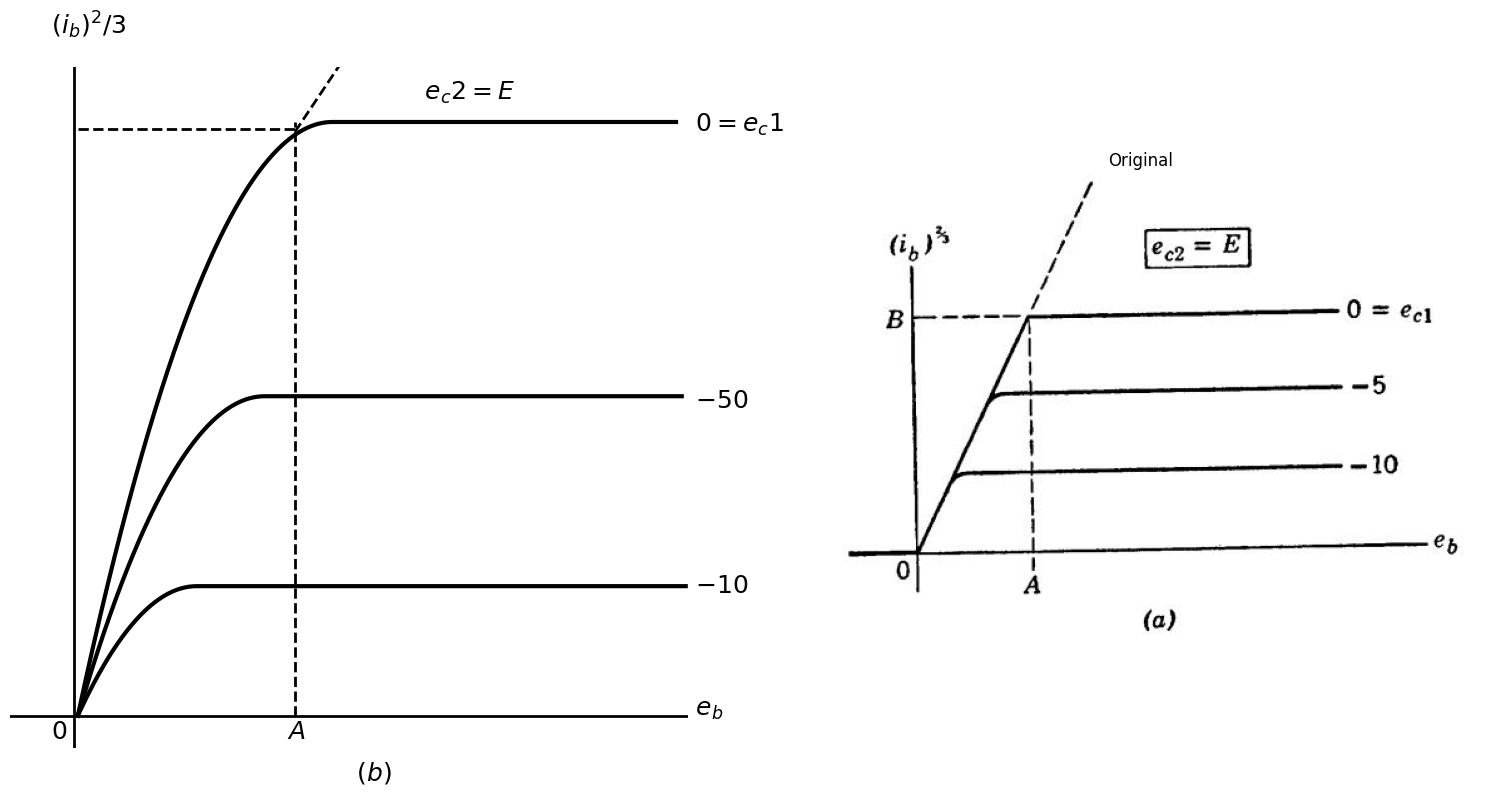

In [607]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Doc.ExampleTools import find_libraries
from PySpice.Probe.Plot import plot
from PySpice.Spice.Library import SpiceLibrary
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

fig, axs = plt.subplots(1, 2, figsize=(15, 8))

x_values = [32, 32]  
y_values = [0, 183000]  

x1_values = [0, 32]  
y1_values = [181000, 181000]

x2_values = [32, 56]  
y2_values = [180000, 255000]

circuit = Circuit('NMOS')
circuit.model('2N7000', 'NMOS', L=100E-6, W=200E-6, Kp=0.13, Vto=2.475)
Vgate = circuit.V('gate','gate',circuit.gnd,   0@u_V)
circuit.R(2, 'drain', '2', 0.01@u_Ohm)
Vi = circuit.V('i', '2', circuit.gnd, 1@u_V)
circuit.MOSFET(1, 'drain', 'gate', circuit.gnd,circuit.gnd, model='2N7000')
for gate_voltage in np.arange(20,50, 10):
    gate_voltage = gate_voltage@u_V
    Vgate.dc_value = gate_voltage
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(0, 90, 0.1))
    axs[0].plot(analysis['drain'], u_mA(-analysis.Vi),linewidth=3, color='black')
    
axs[0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
axs[0].plot(x2_values, y2_values, ls='--', color='black', linewidth=2)
axs[0].axhline(10, color='black',linewidth=2, ls='-')
axs[0].axvline(-0.63, color='black',linewidth=2, ls='-')
axs[0].axis('off')
axs[0].text(-5,210000, ' $(i_b)^2/3$ ', fontsize=18)
axs[0].text(-5,-7000, ' $0$ ', fontsize=18)
axs[0].text(30,-7000, ' $A$ ', fontsize=18)
axs[0].text(50,190000, ' $e_c2=E$ ', fontsize=18)
axs[0].text(90,0, ' $e_b$ ', fontsize=18)
axs[0].text(90,38000, ' $-10$ ', fontsize=18)
axs[0].text(90,95000, ' $-50$ ', fontsize=18)
axs[0].text(90,180000, ' $0=e_c1$ ', fontsize=18)
axs[0].text(40,-20000, ' $(b)$ ', fontsize=18)
axs[0].set_xlim(-10, 90)
axs[0].set_ylim(-10000,200000)

img_sample = mpimg.imread('images/18.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# MOSFET parameters
Vth = 2  # Threshold voltage (V)
k = 50e-3  # Transconductance parameter (A/V^2)

Vds = np.linspace(0, 5, 500)  # Drain-source voltage range

def mosfet_id(Vgs, Vds=Vds, Vth=Vth, k=k):
    Id = np.zeros_like(Vds)
    for i, V in enumerate(Vds):
        if Vgs <= Vth:
            Id[i] = 0  # Cutoff
        elif V < (Vgs - Vth):
            Id[i] = k * ((Vgs - Vth) * V - 0.5 * V**2)  # Triode region
        else:
            Id[i] = 0.5 * k * (Vgs - Vth)**2  # Saturation
    return Id

def plot_id_vds(Vgs):
    Id = mosfet_id(Vgs)
    plt.figure(figsize=(8,6))
    plt.plot(Vds, Id*1e3)  # Convert to mA
    plt.title(f'MOSFET Id-Vds Characteristics (Vgs={Vgs:.2f} V)')
    plt.xlabel('Drain-Source Voltage Vds (V)')
    plt.ylabel('Drain Current Id (mA)')
    plt.ylim(-3, 18)
    plt.grid(True)
    plt.show()

interact(plot_id_vds, Vgs=FloatSlider(min=2, max=3.0, step=0.05, value=3.0))


interactive(children=(FloatSlider(value=3.0, description='Vgs', max=3.0, min=2.0, step=0.05), Output()), _dom_…

<function __main__.plot_id_vds(Vgs)>

## Fig. 7.8. Idealized pent.ode curves, showing the effect of a change in screen-grid potential.	Note that **ib½** is the scale, not io.

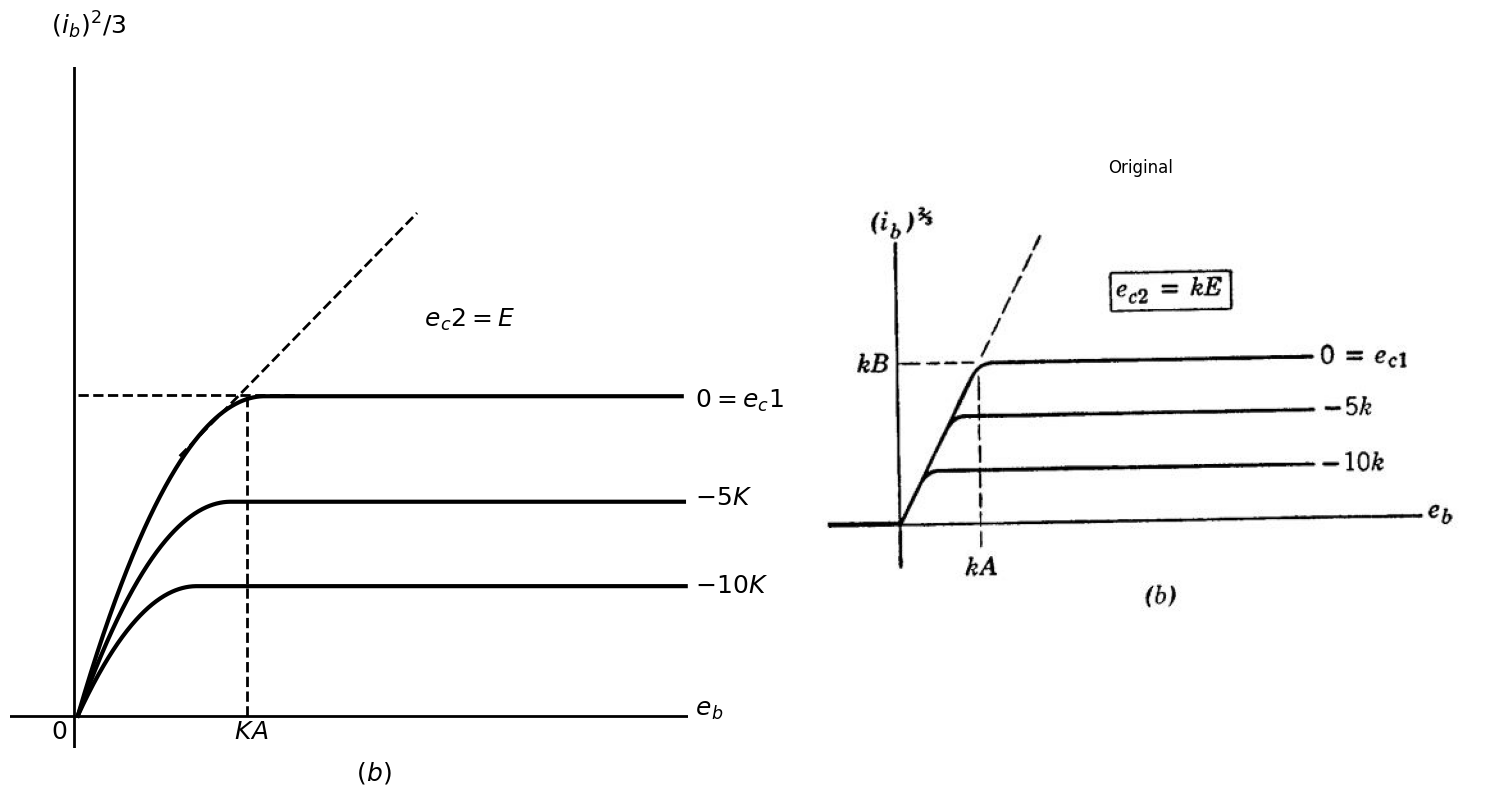

In [629]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Doc.ExampleTools import find_libraries
from PySpice.Probe.Plot import plot
from PySpice.Spice.Library import SpiceLibrary
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

fig, axs = plt.subplots(1, 2, figsize=(15, 8))

x_values = [25, 25]  
y_values = [0, 99000]  

x1_values = [0, 32]  
y1_values = [99000, 99000]

x2_values = [15, 50]  
y2_values = [80000, 155000]

circuit = Circuit('NMOS')
circuit.model('2N7000', 'NMOS', L=100E-6, W=200E-6, Kp=0.13, Vto=2.475)
Vgate = circuit.V('gate','gate',circuit.gnd,   0@u_V)
circuit.R(2, 'drain', '2', 0.01@u_Ohm)
Vi = circuit.V('i', '2', circuit.gnd, 1@u_V)
circuit.MOSFET(1, 'drain', 'gate', circuit.gnd,circuit.gnd, model='2N7000')
for gate_voltage in np.arange(20,35, 5):
    gate_voltage = gate_voltage@u_V
    Vgate.dc_value = gate_voltage
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(0, 90, 0.1))
    axs[0].plot(analysis['drain'], u_mA(-analysis.Vi),linewidth=3, color='black')
    
axs[0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
axs[0].plot(x2_values, y2_values, ls='--', color='black', linewidth=2)
axs[0].axhline(10, color='black',linewidth=2, ls='-')
axs[0].axvline(-0.63, color='black',linewidth=2, ls='-')
axs[0].axis('off')
axs[0].text(-5,210000, ' $(i_b)^2/3$ ', fontsize=18)
axs[0].text(-5,-7000, ' $0$ ', fontsize=18)
axs[0].text(22,-7000, ' $KA$ ', fontsize=18)
axs[0].text(50,120000, ' $e_c2=E$ ', fontsize=18)
axs[0].text(90,0, ' $e_b$ ', fontsize=18)
axs[0].text(90,38000, ' $-10K$ ', fontsize=18)
axs[0].text(90,65000, ' $-5K$ ', fontsize=18)
axs[0].text(90,95000, ' $0=e_c1$ ', fontsize=18)
axs[0].text(40,-20000, ' $(b)$ ', fontsize=18)
axs[0].set_xlim(-10, 90)
axs[0].set_ylim(-10000,200000)

img_sample = mpimg.imread('images/19.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7.8.Idealized pent.ode curves, showing the effect of a change in screen-grid potential.	Note that **ib½** is the scale, not io.

This is a fair approximation, and it leads to the idealized pentode curves plotted in Fig. 7.8 with the two-thirds power of **ib**, rather than **ib** itself, as the vertical co-ordinate. The idealized curves are horizontal and equally spaced. In the virtual-cathode region the curves all join on a line of slope **B/ A**, representing the three-halves power law for unsaturated operation of the diode portion of the pentode. Comparison of Fig. 7.8(a) and (b) shows the effect of a change in the screen-grid supply voltage.  To convert a set of pentode curves from one fixed value of screen-grid voltage to another, simply multiply each of the voltage scales by the scale factor **k** and multiply the current scale by the three-halves power of the scale factor **k**.

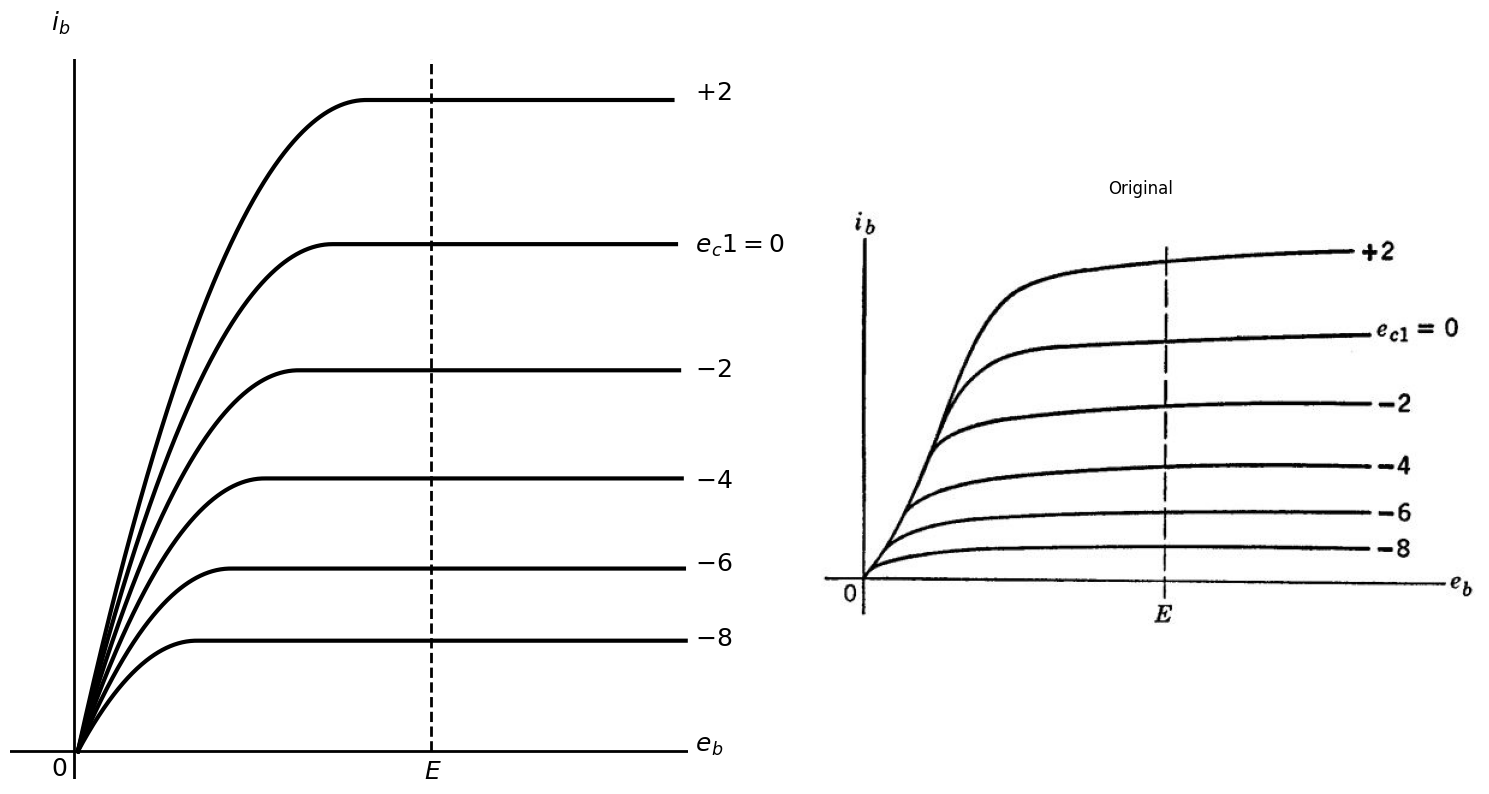

In [650]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Doc.ExampleTools import find_libraries
from PySpice.Probe.Plot import plot
from PySpice.Spice.Library import SpiceLibrary
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

fig, axs = plt.subplots(1, 2, figsize=(15, 8))

x_values = [52, 52]  
y_values = [0, 250000]  

circuit = Circuit('NMOS')
circuit.model('2N7000', 'NMOS', L=100E-6, W=200E-6, Kp=0.13, Vto=2.475)
Vgate = circuit.V('gate','gate',circuit.gnd,   0@u_V)
circuit.R(2, 'drain', '2', 0.01@u_Ohm)
Vi = circuit.V('i', '2', circuit.gnd, 1@u_V)
circuit.MOSFET(1, 'drain', 'gate', circuit.gnd,circuit.gnd, model='2N7000')
for gate_voltage in np.arange(20,50, 5):
    gate_voltage = gate_voltage@u_V
    Vgate.dc_value = gate_voltage
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(0, 90, 0.1))
    axs[0].plot(analysis['drain'], u_mA(-analysis.Vi),linewidth=3, color='black')
    
axs[0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[0].axhline(10, color='black',linewidth=2, ls='-')
axs[0].axvline(-0.63, color='black',linewidth=2, ls='-')
axs[0].axis('off')
axs[0].text(-5,260000, ' $i_b$ ', fontsize=18)
axs[0].text(-5,-9000, ' $0$ ', fontsize=18)
axs[0].text(50,-10000, ' $E$ ', fontsize=18)
axs[0].text(90,135000, ' $-2$ ', fontsize=18)
axs[0].text(90,0, ' $e_b$ ', fontsize=18)
axs[0].text(90,38000, ' $-8$ ', fontsize=18)
axs[0].text(90,65000, ' $-6$ ', fontsize=18)
axs[0].text(90,95000, ' $-4$ ', fontsize=18)
axs[0].text(90,180000, ' $e_c1=0$ ', fontsize=18)
axs[0].text(90,235000, ' $+2$ ', fontsize=18)
axs[0].set_xlim(-10, 90)
axs[0].set_ylim(-10000,250000)

img_sample = mpimg.imread('images/20.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# MOSFET parameters
Vth = 2  # Threshold voltage (V)
k = 50e-3  # Transconductance parameter (A/V^2)

Vds = np.linspace(0, 5, 500)  # Drain-source voltage range

def mosfet_id(Vgs, Vds=Vds, Vth=Vth, k=k):
    Id = np.zeros_like(Vds)
    for i, V in enumerate(Vds):
        if Vgs <= Vth:
            Id[i] = 0  # Cutoff
        elif V < (Vgs - Vth):
            Id[i] = k * ((Vgs - Vth) * V - 0.5 * V**2)  # Triode region
        else:
            Id[i] = 0.5 * k * (Vgs - Vth)**2  # Saturation
    return Id

def plot_id_vds(Vgs):
    Id = mosfet_id(Vgs)
    plt.figure(figsize=(8,6))
    plt.plot(Vds, Id*1e3)  # Convert to mA
    plt.title(f'MOSFET Id-Vds Characteristics (Vgs={Vgs:.2f} V)')
    plt.xlabel('Drain-Source Voltage Vds (V)')
    plt.ylabel('Drain Current Id (mA)')
    plt.ylim(-3, 18)
    plt.grid(True)
    plt.show()

interact(plot_id_vds, Vgs=FloatSlider(min=2, max=3.0, step=0.05, value=3.0))


interactive(children=(FloatSlider(value=3.0, description='Vgs', max=3.0, min=2.0, step=0.05), Output()), _dom_…

<function __main__.plot_id_vds(Vgs)>

## Fig, 7.9.A typical family of pentode plate curve **(ec2 = E = constant)**.

Figure 7.9 shows a family of pentode plate curves forsome fixed screen grid voltage. Here the first power of the current is plotted and the curves therefore exhibit a crowding at low values of current. In the central region of the curves the control-grid-to-plate transconductance **g1p**, is approximately proportional to the cube root of the plate current, for if **ib2/3 = = (ec2 + µ21ec1)**, then **g1p = ƌib/ƌec1  == (ib)1/3**.

Figure 7.10 shows a typical pentode amplifier circuit.  The by-pass capacitors **Ck**, and **Cc2** are assumed to have negligible reactance at all signal frequencies of interest. Hence the cathode and screen-grid potentials are essentially constant. In such a circuit the pentode operates as a good high-frequency voltage amplifier. The pentode has one disadvantage not present in the triode. The cathode current divides into two portions; a small fraction to the screen grid and the remainder to the plate. The slight inherent random fluctuation in this division ratio produces an additional fluctuation in plate current which is not present in the cathode current. This extra component of plate current is called "partition noise" or "division noise" and, other things being equal, it makes the pentode slightly noisier than the triode. Nevertheless the pentode has found wide use in high-frequency applications where extreme sensitivity is not required.

In some special purpose pentodes, called "gate" tubes, the suppressor-grid terminal is externally available as shown in Fig. 7.ll(a).	If the
suppressor-grid voltage is made several volts negative with respect to the cathode, the interelectrode potential between screen-grid and plate grid terminal is externally available as shown in Fig. 7.ll(a).	If the suppressor-grid voltage is made several volts negative with respect to the cathode, the interelectrode potential between screen-grid and plate comes down like a curtain and begins to cut off the flow of plate current. Hence a region exists within which the suppressor grid acts like a control grid, as illustrated in Fig. 7.11(b).  



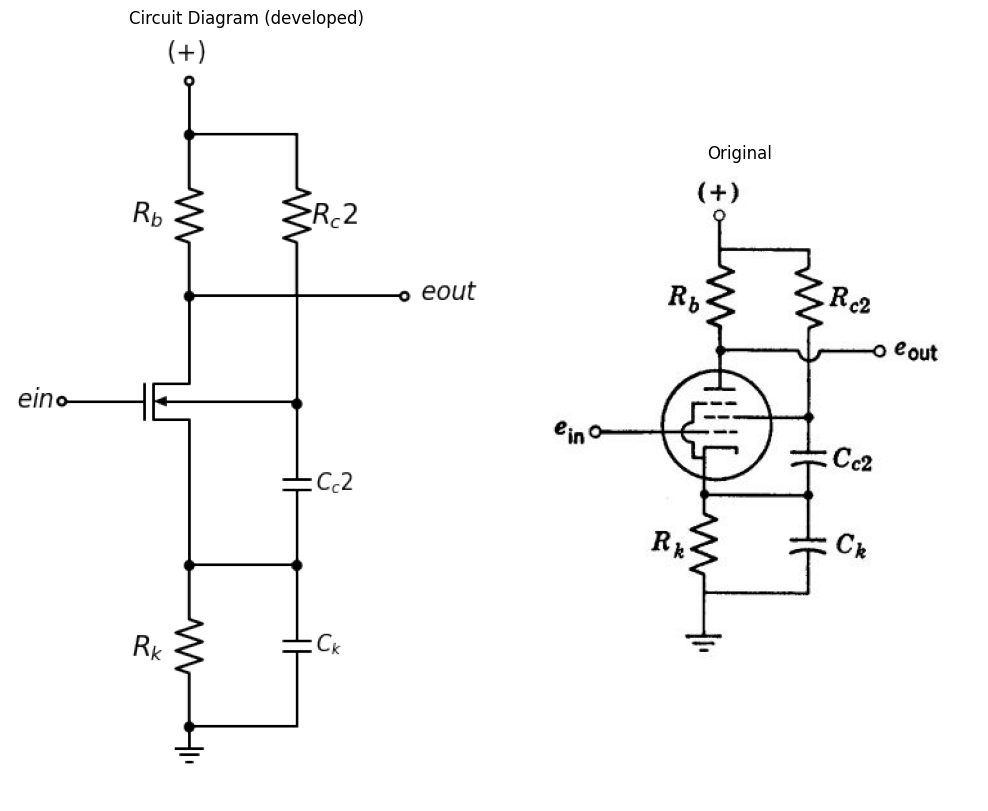

In [719]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
l1 = d.add(elm.Line().right().length(1))
d += (M1 := elm.NFet(bulk = True).anchor('gate').reverse())
l2 = d.add(elm.Line().down().length(2.3).at(M1.source).dot())
d += ( R1 := elm.Resistor().down().label(['$R_k$'] , ofst=0.2 , fontsize = 20).dot())
d += elm.Ground()
l3 = d.add(elm.Line().right().length(2).at(R1.end))
C1 = d.add(elm.Capacitor().up().label(['$C_k$'] , ofst=-1.1 , fontsize = 16).dot())
C2 = d.add(elm.Capacitor().up().label(['$C_c2$'] , ofst=-1.3 , fontsize = 16).dot())
l4 = d.add(elm.Line().up().length(2))
d += ( R2 := elm.Resistor().up().label(['$R_c2$'] , ofst=-1.4 , fontsize = 20))
l5 = d.add(elm.Line().up().length(1.2).at(M1.drain).dot())
d += ( R3 := elm.Resistor().up().label(['$R_b$'] , ofst=0.2 , fontsize = 20).dot())
l6 = d.add(elm.Line().up().length(1).dot(open=True))
l7 = d.add(elm.Line().right().length(2).at(M1.bulk))
l8 = d.add(elm.Line().right().length(2).at(R3.end))
l9 = d.add(elm.Line().right().length(4).at(R3.start).dot(open=True))
l10 = d.add(elm.Line().right().length(2).at(R1.start))
d += elm.Gap().up().at((7.2,0.8)).label('$ eout $'  , fontsize = 18)
d += elm.Gap().up().at((-0.5,-1.2)).label('$ e in $'  , fontsize = 18)
d += elm.Gap().up().at((2.3,5.3)).label('$ (+) $'  , fontsize = 18)
d.save('./Drawings/fig21.png')
d.save('./Drawings/fig21.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig21.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/21.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7.10.A pentode amplifier operating from a single supply voltage.

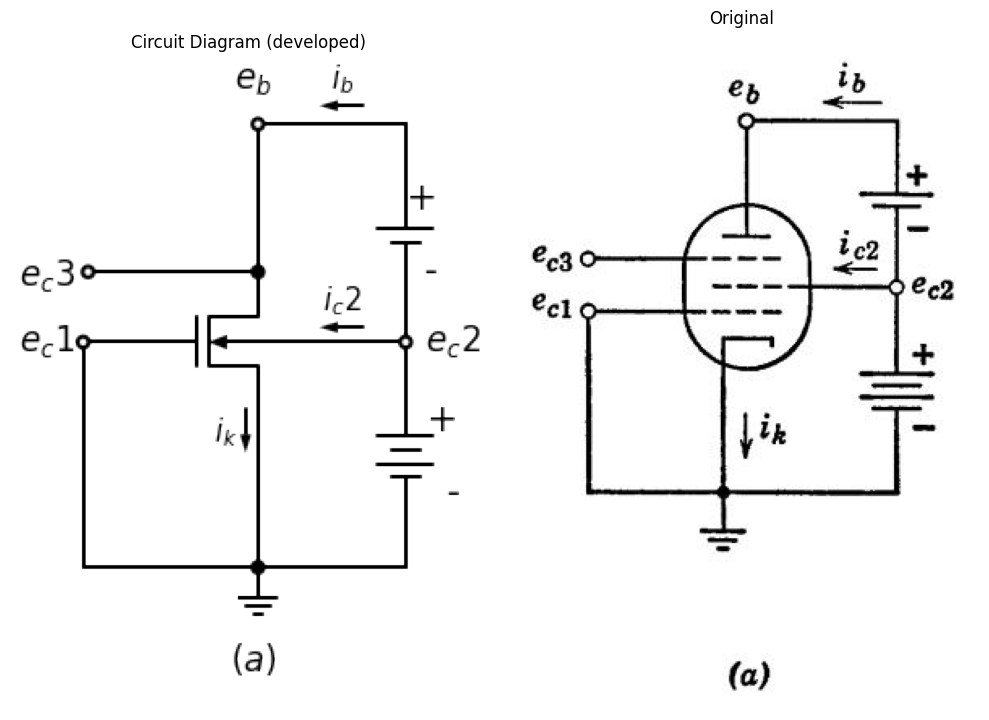

In [782]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
l1 = d.add(elm.Line().right().length(1))
d += (M1 := elm.NFet(bulk = True).anchor('gate').reverse())
l2 = d.add(elm.Line().down().length(2.3).at(M1.source).dot())
d += elm.Ground()
l3 = d.add(elm.Line().right().length(2).at(l2.end))
d += ( E1 := elm.Battery().up().reverse().label(['-','+'] , ofst=-1.1,fontsize = 20))
d += ( E2 := elm.BatteryCell().up().reverse().label(['-','+'] , ofst=-0.8,fontsize = 20))
l4 = d.add(elm.Line().left().length(2).dot(open=True))
d += elm.Arrow().length(0.6).at((3.8,3.2)).left().label('$i_b$', fontsize = 16)
l5 = d.add(elm.Line().up().length(0.2).at(M1.drain).dot())
l6 = d.add(elm.Line().up().length(2))
l7 = d.add(elm.Line().right().length(2).at(M1.bulk).dot(open=True))
l8 = d.add(elm.Line().left().length(2.3).at(l5.end).dot(open=True))
l9 = d.add(elm.Line().left().length(2.35).at(l2.end))
l10 = d.add(elm.Line().up())
d += elm.Gap().up().at((-0.5,-0.3)).label('$ e_c3 $'  , fontsize = 18)
d += elm.Gap().up().at((5.0,-1.2)).label('$ e_c2 $'  , fontsize = 18)
d += elm.Gap().up().at((-0.5,-1.2)).label('$ e _c1 $'  , fontsize = 18)
d += elm.Gap().up().at((2.3,2.3)).label('$ e_b $'  , fontsize = 18)
d += elm.Arrow().length(0.6).at((3.8,0.2)).left().label('$i_c2$', fontsize = 16)
d += elm.Arrow().length(0.6).at((2.2,-0.9)).down().label('$i_k$', fontsize = 16)
d += elm.Gap().up().at((2.3,-5.5)).label('$ (a) $'  , fontsize = 18)
d.save('./Drawings/fig22.png')
d.save('./Drawings/fig22.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig22.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/22.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7.11.Gate circuit.	(a) A "gate" tube, having an externally available suppressor-grid	terminal.


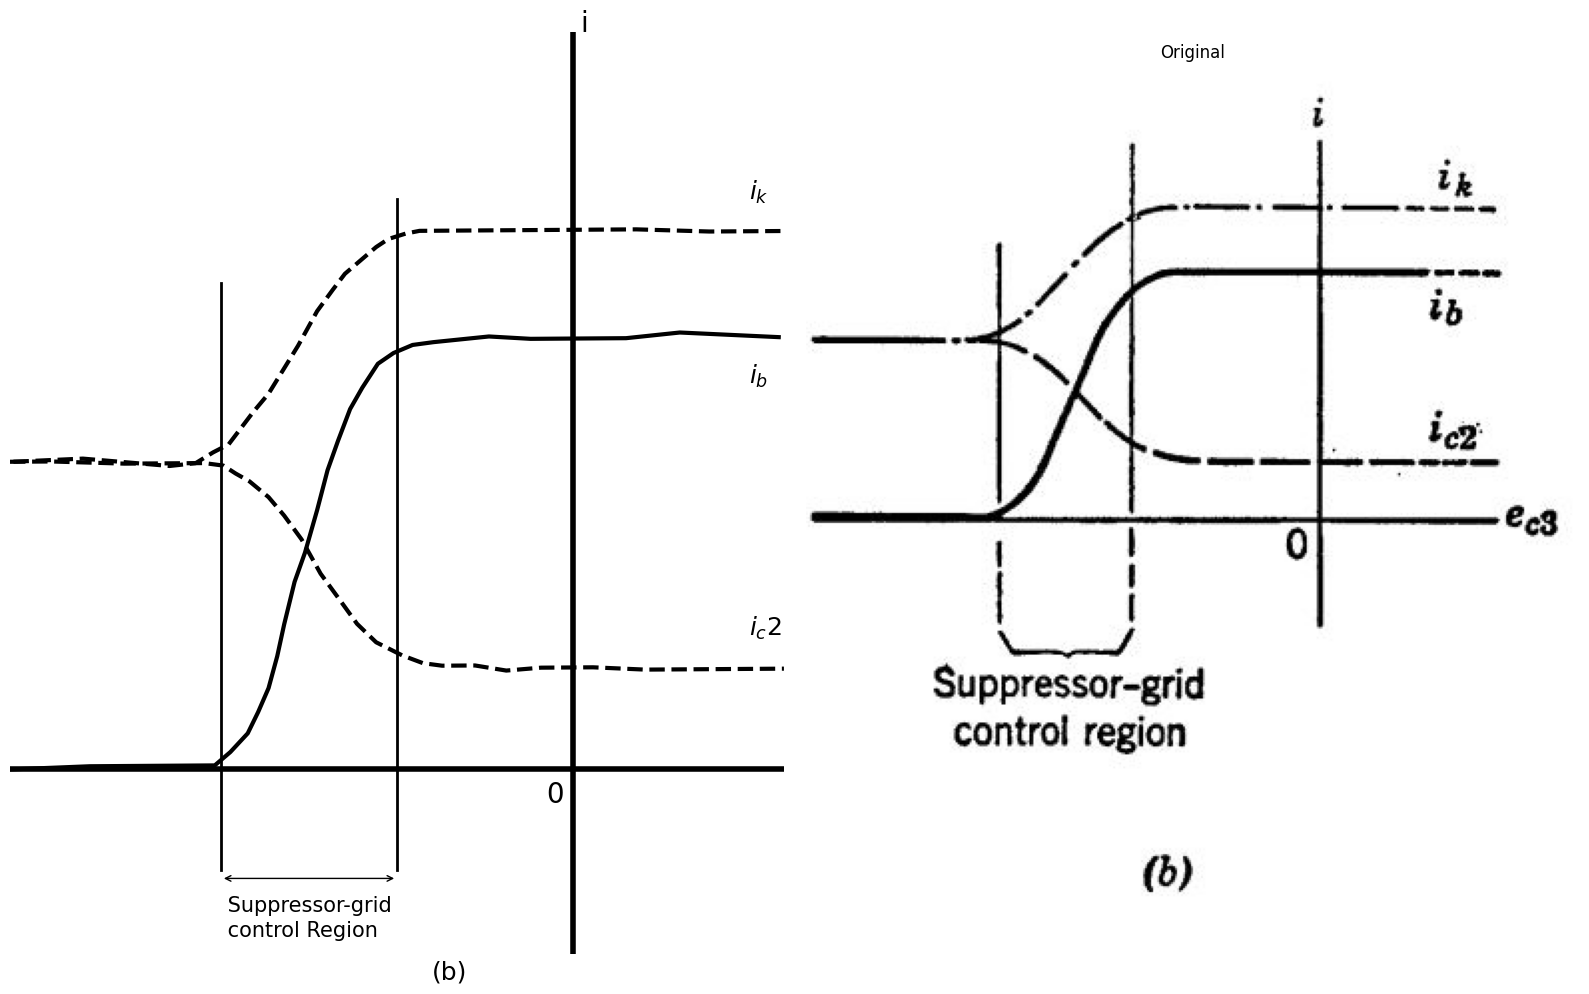

In [850]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(16, 10))
x_values = [-2.5, -2.5]  
y_values = [-1, 7]  

x1_values = [-5, -5]  
y1_values = [-1, 6]


#Data
P1 = [-8,-6.865470852,-5.730941704,-5.089686099,-4.867713004,-4.621076233,-4.47309417,-4.325112108,-4.201793722,-4.103139013,-3.955156951,-3.807174888,
      -3.634529148,-3.486547085,-3.338565022,-3.165919283,-2.993273543,-2.771300448,-2.549327354,-2.278026906,-1.98206278,-1.192825112,-0.600896861
      ,0.089686099,0.755605381,1.520179372,2.926008969]
F1 = [0.200005676,0.238179032,0.244706817,0.248396435,0.407901459,0.63083953,0.884855537,1.170517114,1.550973492,1.93128796,2.438468525,2.787421241
      ,3.294743713,3.770278708,4.119231424,4.499971618,4.754129534,5.040216836,5.16807629,5.264573991,5.297922461,5.365754669,5.3375149,5.341488335
      ,5.345319861,5.413010161,5.357807799]

P2 = [-8,-7.408071749,-6.372197309,-5.459641256,-5.237668161,-4.966367713,-4.793721973,-4.596412556,-4.325112108,-4.103139013,-3.856502242,-3.585201794
      ,-3.338565022,-3.067264574,-2.795964126,-2.426008969,-2.130044843,-1.858744395,-1.390134529,-0.946188341,-0.452914798,0.286995516,1.02690583
      ,1.939461883,3]
F2 = [3.870891752,3.874297553,3.848612136,3.853862746,3.855139922,3.825055344,3.731111994,3.637310552,3.448998127,3.228756315,2.945365272,2.535533859
      ,2.252142817,1.937248113,1.717290118,1.561190895,1.467957087,1.43787251,1.440568769,1.37983198,1.414315718,1.418572969,1.391184651,1.396435261
      ,1.402537322]

P3 = [-7.950672646,-6.964125561,-5.730941704,-5.360986547,-5.114349776,-4.892376682,-4.719730942,-4.547085202,-4.325112108,-3.905829596,-3.634529148
      ,-3.412556054,-3.239910314,-3.01793722,-2.795964126,-2.623318386,-2.376681614,-2.179372197,-1.957399103,-1.316143498,-0.502242152,0.903587444
      ,1.939461883,2.950672646]
F3 = [3.871175569,3.908497474,3.820656184,3.85443038,3.982431742,4.078645626,4.269512403,4.460379179,4.683175342,5.255208038,5.668161435,5.922603167
      ,6.113469944,6.272974967,6.432479991,6.528410058,6.593120282,6.625901118,6.627178294,6.630867912,6.635550888,6.643639666,6.617954249,6.623772492]

axs[0].plot(P1, F1, 'black',linestyle='-', linewidth=3)
axs[0].plot(P2, F2, 'black',linestyle='--', linewidth=3)
axs[0].plot(P3, F3, 'black',linestyle='--', linewidth=3)
axs[0].plot(x_values, y_values, ls='-', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='-', color='black', linewidth=2)
axs[0].axhline(0.2, color='black',linewidth=4, ls='-')
axs[0].axvline(0, color='black',linewidth=4, ls='-')
axs[0].text(0.1,9, 'i', fontsize=20)
axs[0].text(2.5,7, '$ i_k $', fontsize=18)
axs[0].text(-2,-2.3, '(b)', fontsize=18)
axs[0].text(2.5,4.8, '$ i_b $', fontsize=18)
axs[0].text(2.5,1.8, '$ i_c2 $', fontsize=18)
axs[0].text(-0.5,-0.2, ' 0', fontsize=20)
axs[0].annotate('', xy=(-2.5, -1.1), xytext=(-5.0, -1.1), arrowprops=dict(arrowstyle='<->'))
axs[0].text(-5,-1.8, ' control Region', fontsize=15)
axs[0].text(-5,-1.5, ' Suppressor-grid', fontsize=15)
axs[0].set_xlim(-8, 3)
axs[0].set_ylim(-2,9)
axs[0].axis('off')

img_sample = mpimg.imread('images/23.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig. 7.11. Gate circuit.	(b) Control action at	negative values of	suppressor-grid voltage.


A sufficiently large negative signal at the suppressor grid can therefore be utilized to "close the gate" and interrupt the flow of signals from the control grid to the plate in a pentode amplifier.

Figure 7.12(a) shows a piecewise-linear model which approximates the behavior of the pentode plate circuit. We assume here that the suppressor grid is connected to the cathode. The associated plate curves are shown in Fig. 7.12(c). If parameter g is allowed to approach infinity, the curves occupy the entire first quadrant of the ib vs. eb plane, and the circuit model becomes equivalent to the one shown in Fig. 7.3(c). 

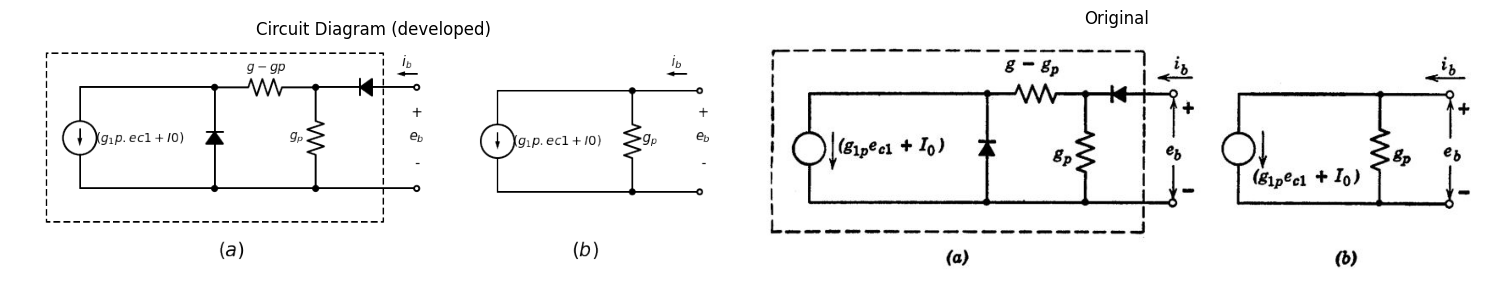

In [930]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
    
d = schemdraw.Drawing()
d.push( )
I1 = d.add(elm.SourceI().down().label(['$ (g_1p.ec1+I0) $'], ofst=-3.6, fontsize=15))
l1 = d.add(elm.Line().right().length(4).dot())
l2 = d.add(elm.Line().right().dot())
l3 = d.add(elm.Line().right().dot(open=True))
D1 = d.add(elm.Diode(fill=True).up().at(l1.end).dot())
R1 = d.add(elm.Resistor().right().label('$ g-gp $', fontsize=15).dot())
D2 = d.add(elm.Diode(fill=True).right().reverse().dot(open=True))
R2 = d.add(elm.Resistor().down().at(D2.start).label('$ g_p $', fontsize=15))
l4 = d.add(elm.Line().left().at(R1.start).length(4))
d += elm.Gap().up().at((9,-3)).label(['-' , '$e_b$' , '+'], ofst=-1 , fontsize = 16)
d += ( T := dsp.Box(w=10, h=5).anchor('W').linestyle('--').at((-1,-1.5)))
d += elm.Gap().up().at((4.5,-6)).label('$(a)$'  , fontsize = 22)
d += elm.Arrow().length(0.6).at((10,0.4)).left().label('$i_b$', fontsize = 16)
d.push()
d.move(3, -0.5)
I2 = d.add(elm.SourceI().down().label(['$ (g_1p.ec1+I0) $'], ofst=-3.6, fontsize=15))
l5 = d.add(elm.Line().right().length(4).dot())
l6 = d.add(elm.Line().right().length(2).dot(open=True))
R3 = d.add(elm.Resistor().up().at(l6.start).label('$ g_p $', ofst=-1, fontsize=16).dot())
l7 = d.add(elm.Line().left().at(R3.end).length(4))
l8 = d.add(elm.Line().right().at(R3.end).length(2).dot(open=True))
d += elm.Gap().up().at((15,-6)).label('$(b)$'  , fontsize = 22)
d += elm.Arrow().length(0.6).at((18,0.4)).left().label('$i_b$', fontsize = 16)
d += elm.Gap().up().at((17.5,-3)).label(['-' , '$e_b$' , '+'], ofst=-1 , fontsize = 16)
d.save('./Drawings/fig24.png')
d.save('./Drawings/fig24.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig24.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/24.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7.12. Pentode model and curves. (a) A piecewise-linear model for the pent.ode plate circuit **(ec3 = 0, ec2 = constant)**; (b) The linear model, applicable in the central region of the plate curves, to which (a) reduces with the shunt diode open and the series diode closed.

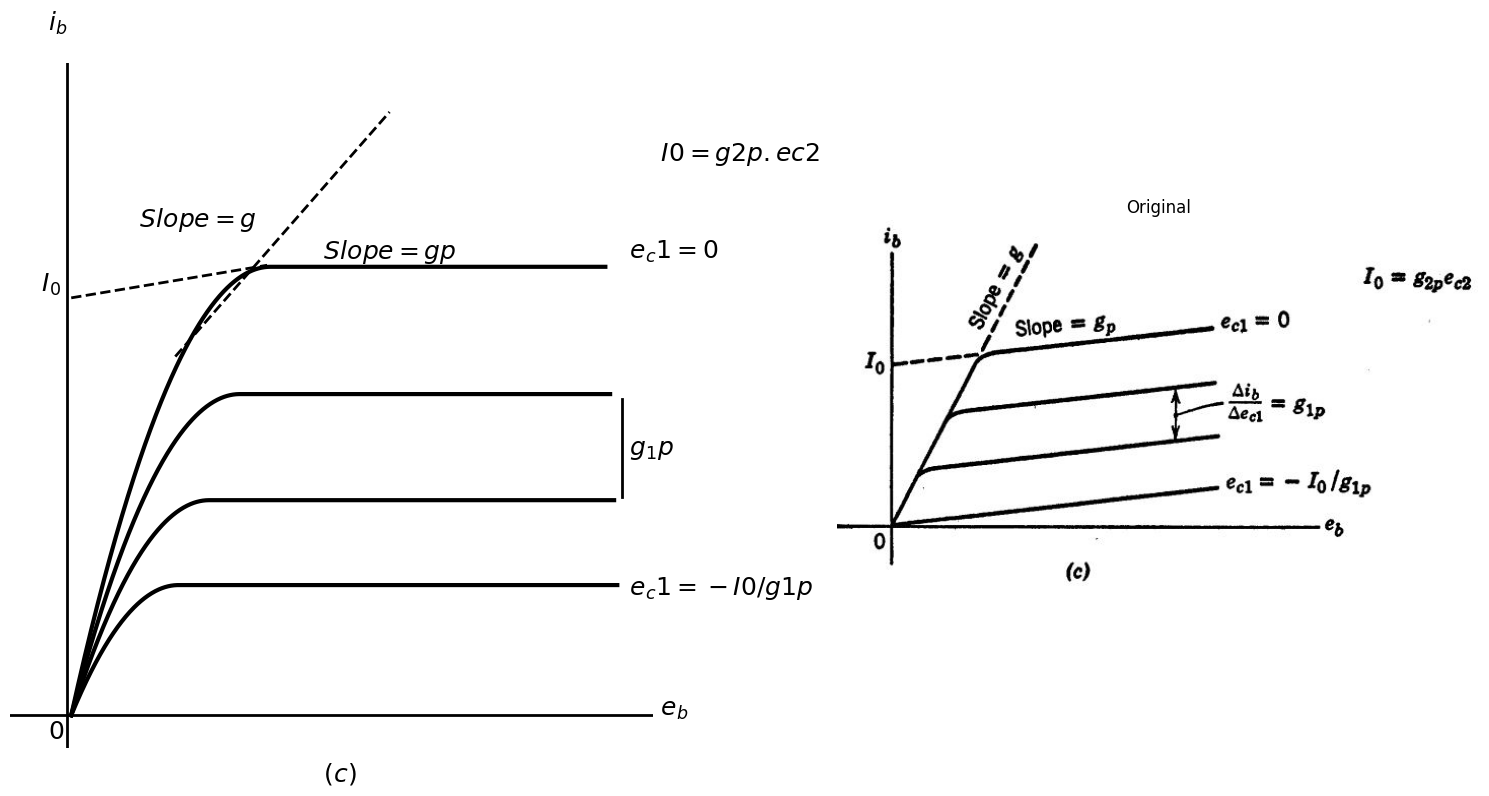

In [1005]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Doc.ExampleTools import find_libraries
from PySpice.Probe.Plot import plot
from PySpice.Spice.Library import SpiceLibrary
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

fig, axs = plt.subplots(1, 2, figsize=(15, 8))

x_values = [90, 90]  
y_values = [67000, 97000]  

x1_values = [0, 32]  
y1_values = [128000, 138000]

x2_values = [17, 52]  
y2_values = [110000, 185000]

circuit = Circuit('NMOS')
circuit.model('2N7000', 'NMOS', L=100E-6, W=200E-6, Kp=0.13, Vto=2.475)
Vgate = circuit.V('gate','gate',circuit.gnd,   0@u_V)
circuit.R(2, 'drain', '2', 0.02@u_Ohm)
Vi = circuit.V('i', '2', circuit.gnd, 1@u_V)
circuit.MOSFET(1, 'drain', 'gate', circuit.gnd,circuit.gnd, model='2N7000')
for gate_voltage in np.arange(20,40, 5):
    gate_voltage = gate_voltage@u_V
    Vgate.dc_value = gate_voltage
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(0, 90, 0.1))
    axs[0].plot(analysis['drain'], u_mA(-analysis.Vi),linewidth=3, color='black')
    
axs[0].plot(x_values, y_values, ls='-', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
axs[0].plot(x2_values, y2_values, ls='--', color='black', linewidth=2)
axs[0].axhline(10, color='black',linewidth=2, ls='-')
axs[0].axvline(-0.63, color='black',linewidth=2, ls='-')
axs[0].axis('off')
axs[0].text(-5,210000, ' $ i_b $ ', fontsize=18)
axs[0].text(-5,-7000, ' $ 0 $ ', fontsize=18)
axs[0].text(95,170000, ' $ I0=g2p.ec2 $ ', fontsize=18)
axs[0].text(90,140000, ' $ e_c1=0 $ ', fontsize=18)
axs[0].text(95,0, ' $ e_b $ ', fontsize=18)
axs[0].text(90,37000, ' $ e_c1=-I0/g1p $ ', fontsize=18)
axs[0].text(90,80000, ' $ g_1p $ ', fontsize=18)
axs[0].text(40,140000, ' $ Slope=gp $ ', fontsize=18)
axs[0].text(40,-20000, ' $ (c) $ ', fontsize=18)
axs[0].text(-6,130000, ' $ I_0 $ ', fontsize=18)
axs[0].text(10,150000, ' $ Slope=g $ ', fontsize=18)
axs[0].set_xlim(-10, 95)
axs[0].set_ylim(-10000,200000)

img_sample = mpimg.imread('images/25.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7.12. Pentode model and curves.,(c) The associated piecewise-linear plate-current curves.

 For operation in the central region of the plate curves, a suitable linear model can be obtained from Fig. 7.12(a) by short-circuiting the series diode and open-circuiting the shunt diode.  Also, the conductance **(g -  gp)** may be ignored in this case, since it is in series with a current source. In short, the linear model for the plate circuit of a pentode amplifier consists of a transconductance current **g1p.ec1 + Io** in parallel with a conductance **gp**.  This is the same as the current-source form of the triode model, except for the fact that **gp** is considerably smaller in the pentode than in the triode, and except for the additional term **Io**.
 
 Current **Io** is determined largely by the screen-grid voltage **ec2**.  For a gross approximation to this effect we can write **Io = g2p.ec2**, where **g2p** is the screen-grid-to-plate  transconductance of the model,	a	constant	chosen	to approximate the actual tube data over a range of **ec2**.



# 7.7	The Cryotron

The cryotron, shown in Fig. 7.13, is an ideal control valve which depends for its operation upon the phenomenon of superconductivity. As the temperature of a material is decreased, its resistance in general also decreases. 

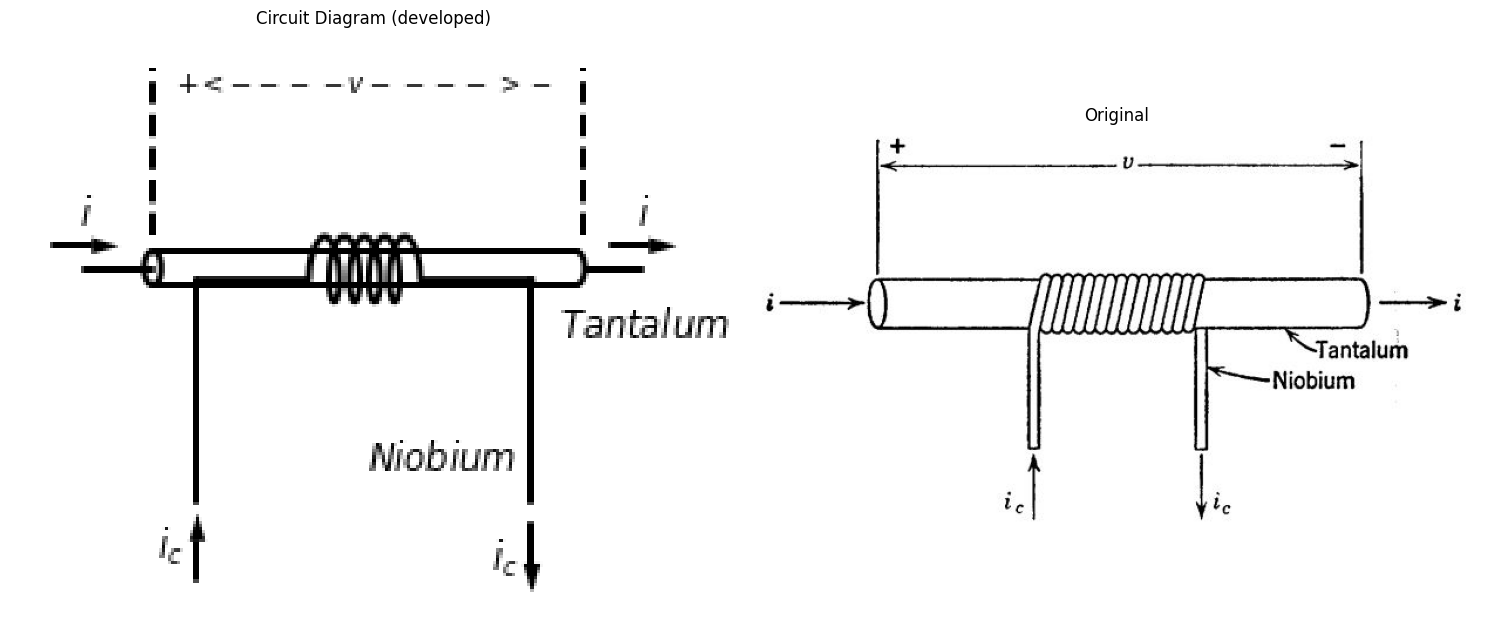

In [1081]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 10))
    
d = schemdraw.Drawing()
d.push( )
Co = d.add(elm.Coax(length=5,radius=0.15).right())
L1 = d.add(elm.Inductor2().at((1,-0.1)))
l1 = d.add(elm.Line().down().at(L1.end).length(2))
l2 = d.add(elm.Line().down().at(L1.start).length(2))
d += elm.Arrow().length(0.6).at((-0.3,0.2)).right().label('$ i $', fontsize = 13)
d += elm.Arrow().length(0.6).at((4.7,0.2)).right().label('$ i $', fontsize = 13)
d += elm.Arrow().length(0.6).at((1,-2.8)).up().label('$ i_c $', fontsize = 13)
d += elm.Arrow().length(0.6).at((4,-2.3)).down().label('$ i_c $', fontsize = 13)
d += elm.Gap().up().at((5,-1.8)).label('$ Tantalum $'  , fontsize = 13)
d += elm.Gap().up().at((3.2,-3)).label('$ Niobium $'  , fontsize = 13)
d += elm.Gap().up().at((2.5,0.3)).label('$ + <---- v ---->- $'  , fontsize = 10)
d += elm.Line().up().length(1.5).at((0.6,0.3)).color('black').linestyle('--')
d += elm.Line().up().length(1.5).at((4.45,0.3)).color('black').linestyle('--')

d.save('./Drawings/fig26.png')
d.save('./Drawings/fig26.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig26.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

img_sample = mpimg.imread('images/26.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()


## Fig. 7.13. The cryotron.

For a certain class of materials called superconductors, the curve of resistivity versus absolute temperature levels off at a few degrees above absolute zero and then drops sharply and completely to zero, as indicated in Fig. 7.14. In the superconducting region lying below the critical temperature **Kc** the resistivity is not merely small but actually zero insofar as the most advanced and refined measurements can show. Moreover, the application of a magnetic field **H** to the material alters the critical temperature, and it is upon this effect that the operation of the cryotron is based.

A cryotron can be constructed by simply winding a "control" coil of insulated niobium wire upon a short length of tantalum wire. Let us now enclose the cryotron in a container surrounded by liquid helium which reduces its temperature below the critical value for both tantalum and niobium.  If we pass a current through the tantalum "valve" wire (by means of leads brought out through the mouth of the container), the voltage drop across the valve will remain at the value zero until the current is raised to some critical value. At this point the self-induced magnetic field within the wire reaches the superconductivity limit for that temperature and the superconductivity is suddenly destroyed. 

What happens is that one small portion of the wire near the surface first becomes resistive. This distorts the lines of current flow and increases the magnetic field nearby. The result is a self-propagating wave of increased resistivity which quickly destroys superconductivity throughout the short piece of valve wire. Let us assume that the short length of tantalum valve wire is electrically connected to the remainder of the system through leads of niobium book-up wire. 


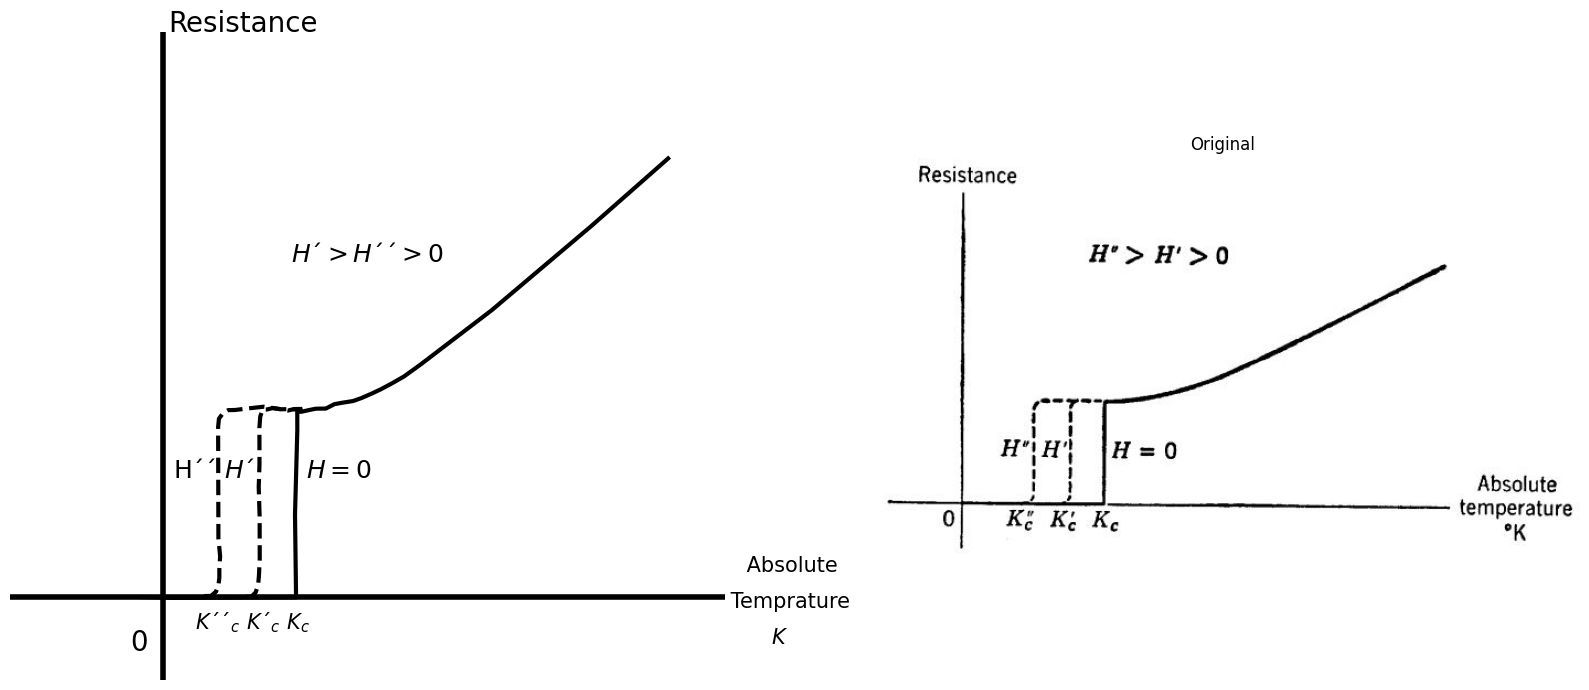

In [1125]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(16, 7))

#Data
P1 = [-0.448482968,0.228314153,2.60517781,2.584447474,2.629667533,2.628736637,2.711264139,2.843236534,2.99171443,3.189780434,3.354620615,3.519604011
      ,3.717598408,3.882510197,4.080361379,4.26170706,4.475992135,4.723216603,5.036248251,6.4364947,8.396424405,9.895059389]
F1 = [0.151795704,0.139980487,0.147526114,1.299133849,2.471015422,2.724800917,2.725740763,2.746766479,2.767980165,2.770235797,2.830681374,2.852083029,2.873860622,2.914784238,2.975605754
      ,3.0362393,3.116770746,3.217200092,3.376947199,4.134759116,5.308923174,6.243560557]

P2 = [0.805935058,0.937979061,1.036797241,1.085955705,1.102103168,1.101673524,1.117534558,1.083592661,1.082375336,1.081229618,1.078938182,1.07843693
      ,1.077935679,1.094011535,1.176252607,1.275142394,1.407186397,1.671202795,1.968230194,2.314988916,2.52956042,2.727698032]
F2 = [0.166081376,0.167585131,0.22727883,0.325452544,0.423250319,0.540382085,0.716267704,0.96967726,1.301550598,1.613901975,2.23860473,2.375258458
      ,2.511912185,2.629231921,2.708259613,2.748431351,2.749935106,2.772464577,2.795369986,2.760273421,2.762717023,2.745450694]

P3 = [1.614776182,1.730314685,1.812627364,1.861785828,1.877790077,1.893436289,1.892648608,1.891288068,1.873278812,1.888638595,1.887492877,1.886776803
      ,1.902709444,1.951867908,2.03439541,2.149862305,2.298483415,2.447104526,2.562571421,2.727626424]
F3 = [0.155769914,0.157085699,0.216591429,0.314765143,0.45160684,0.686058342,0.900799914,1.271717175,1.681490388,1.994029735,2.306381112,2.501600723
      ,2.657964381,2.756138095,2.757077942,2.777915688,2.760085451,2.742255215,2.763092961,2.764972655]

axs[0].plot(P1, F1, 'black',linestyle='-', linewidth=3)
axs[0].plot(P2, F2, 'black',linestyle='--', linewidth=3)
axs[0].plot(P3, F3, 'black',linestyle='--', linewidth=3)
axs[0].axhline(0.15, color='black',linewidth=4, ls='-')
axs[0].axvline(0, color='black',linewidth=4, ls='-')
axs[0].text(0.1,8, 'Resistance', fontsize=20)
axs[0].text(1.2,1.8, '$ H´ $', fontsize=18)
axs[0].text(0.2,1.8, 'H´´', fontsize=18)
axs[0].text(2.5,4.8, '$ H´> H´´ >0 $', fontsize=18)
axs[0].text(2.8,1.8, '$ H=0 $', fontsize=18)
axs[0].text(-0.8,-0.6, ' 0', fontsize=20)
axs[0].text(11,0, ' Temprature', fontsize=15)
axs[0].text(11.3,0.5, ' Absolute', fontsize=15)
axs[0].text(11.8,-0.5, ' $ K $', fontsize=15)
axs[0].text(1.5,-0.3, ' $ K´_c $', fontsize=15)
axs[0].text(2.3,-0.3, ' $ K_c $', fontsize=15)
axs[0].text(0.5,-0.3, ' $ K´´_c $', fontsize=15)
axs[0].set_xlim(-3, 11)
axs[0].set_ylim(-1,8)
axs[0].axis('off')

img_sample = mpimg.imread('images/27.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig.7.14. Resistance of a piece of wire versus absolute temperature **°K**, showing superconductivity below some critical temperature, **Kc**,	A magnetic field **H** within the wire reduces the critical temperature.


The hook-up wire and the control winding will remain superconducting since niobium has a critical temperature roughly twice that of tantalum.  This gives us the zero-control-current curve shown in Fig. 7.15. Let us now return the valve current to zero and repeat the experiment with a nonzero value of the control current **ic**, For a nonzero value of control current, the control winding produces an initial magnetic field within the valve wire. As the valve current **i** is again increased from zero, the critical magnetic field will be reached at a smaller value of valve current. The two components of magnetic field caused by the two currents **i** and **ic** are at right angles to each other and the critical magnetic field of which we speak is the vector sum of these two components. Hence we may expect to find a quadratic relationship between the critical valve current **I** and the control current **ic**,  This relationship is given in Fig. 7.15.  A straight-forward calculation of the magnetic field due to the two currents yields the values of the constants **I0** and **i0**. The values are **𝚷dH0** and **H0/n**, respectively, where **H0** is the critical value of **H** for tantalum at the experimental temperature, **d** is the diameter of the valve wire, and **n** is the number of turns per unit length in the control winding.  The constant
**io** is that value of control current required to destroy superconductivity with no valve current flowing, and the constant **IO** is the critical value of valve current when no control current is flowing.

Because superconducting niobium can tolerate a much higher magnetic field	than  superconducting  tantalum,	the	control	winding	remains uperconducting throughout the ranges of operation indicated in Fig.7.15.



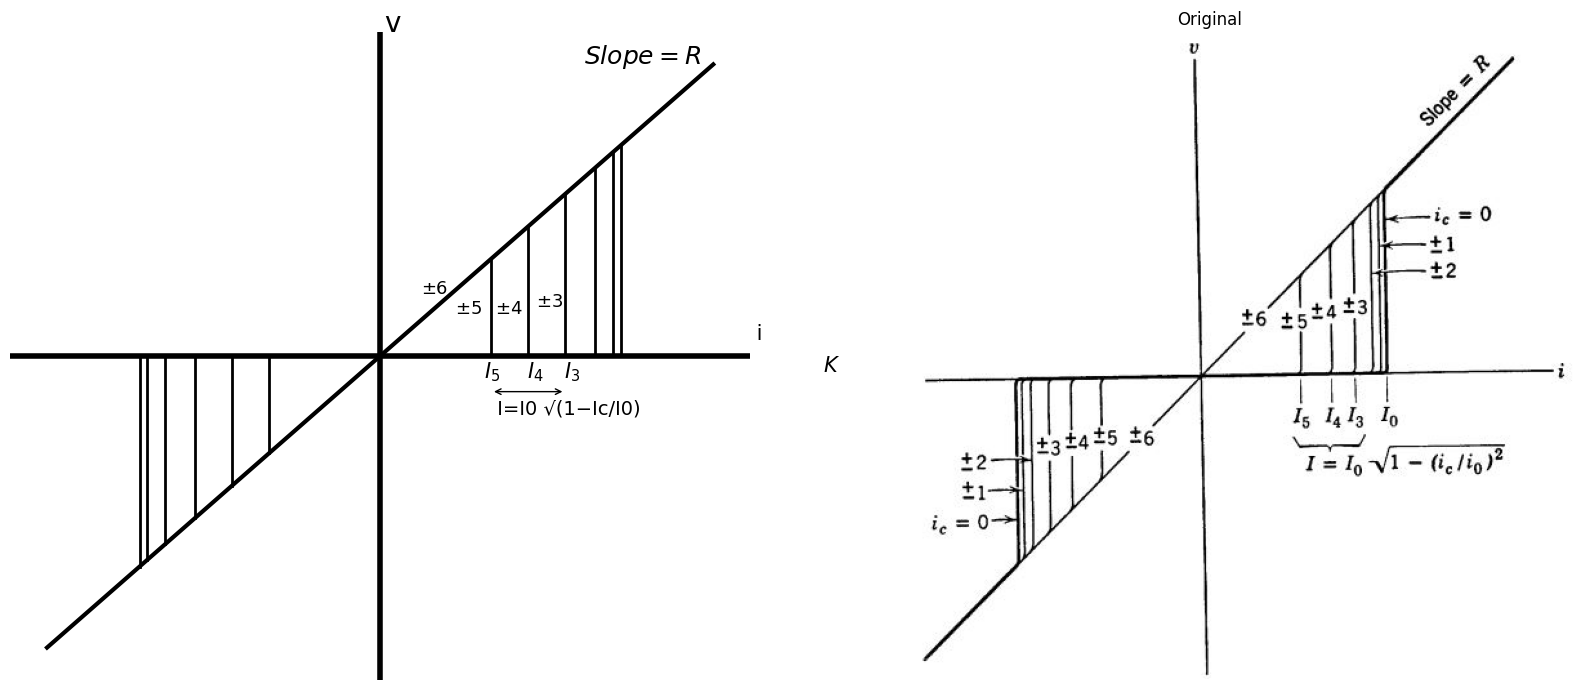

In [1157]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(16, 7))
x_values = [3, 3]  
y_values = [0, 3]  

x1_values = [4, 4]  
y1_values = [0, 4]

x2_values = [5, 5]  
y2_values = [0, 5]

x3_values = [5.8, 5.8]  
y3_values = [0, 5.8]  

x4_values = [6.3, 6.3]  
y4_values = [0, 6.3]

x5_values = [6.5, 6.5]  
y5_values = [0, 6.5]

x6_values = [-3, -3]  
y6_values = [0, -3]  

x7_values = [-4, -4]  
y7_values = [0, -4]

x8_values = [-5, -5]  
y8_values = [0, -5]

x9_values = [-5.8, -5.8]  
y9_values = [0, -5.8]  

x10_values = [-6.3, -6.3]  
y10_values = [0, -6.3]

x11_values = [-6.5, -6.5]  
y11_values = [0, -6.5]
x = np.linspace(-9, 9, 100)  
y = x

axs[0].plot(x_values, y_values, ls='-', color='black', linewidth=2)
axs[0].plot(x1_values, y1_values, ls='-', color='black', linewidth=2)
axs[0].plot(x2_values, y2_values, ls='-', color='black', linewidth=2)
axs[0].plot(x3_values, y3_values, ls='-', color='black', linewidth=2)
axs[0].plot(x4_values, y4_values, ls='-', color='black', linewidth=2)
axs[0].plot(x5_values, y5_values, ls='-', color='black', linewidth=2)
axs[0].plot(x6_values, y6_values, ls='-', color='black', linewidth=2)
axs[0].plot(x7_values, y7_values, ls='-', color='black', linewidth=2)
axs[0].plot(x8_values, y8_values, ls='-', color='black', linewidth=2)
axs[0].plot(x9_values, y9_values, ls='-', color='black', linewidth=2)
axs[0].plot(x10_values, y10_values, ls='-', color='black', linewidth=2)
axs[0].plot(x11_values, y11_values, ls='-', color='black', linewidth=2)

axs[0].plot(x, y, 'black',linestyle='-', linewidth=3) # Plot the line
axs[0].axhline(0, color='black',linewidth=4, ls='-')
axs[0].axvline(0, color='black',linewidth=4, ls='-')
axs[0].text(0.1,10, 'v', fontsize=20)
axs[0].text(4.2,1.5, '$±3 $', fontsize=13)
axs[0].text(1.1,1.9, '±6', fontsize=13)
axs[0].text(5.5,9, '$ Slope=R $', fontsize=18)
axs[0].text(3.1,1.3, '$ ±4 $', fontsize=13)
axs[0].text(2.8,-0.7, '$ I_5 $', fontsize=15)
axs[0].annotate('', xy=(3, -1.1), xytext=(5.0, -1.1), arrowprops=dict(arrowstyle='<->'))
axs[0].text(3,-1.8, ' I=I0 √(1−Ic/I0)', fontsize=14)
axs[0].text(10,0.5, ' i', fontsize=15)
axs[0].text(11.8,-0.5, ' $ K $', fontsize=15)
axs[0].text(1.9,1.3, ' $ ±5 $', fontsize=13)
axs[0].text(4.8,-0.7, ' $ I_3 $', fontsize=15)
axs[0].text(3.8,-0.7, ' $ I_4 $', fontsize=15)
axs[0].set_xlim(-10, 10)
axs[0].set_ylim(-10,10)
axs[0].axis('off')

img_sample = mpimg.imread('images/28.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()


## Fig. 7.15.Cryotron valve curves.

The cryotron therefore is truly an ideal unilateral control valve. Economical modern methods of	producing liquid helium in large quantities make practical cryotron systems a reality.	Cryotrons are very small and hundreds of them can be connected together to form a complicated valve system such as a computer network.The entire network can then be enclosed in a relatively small container, with the cost of maintaining the helium no worse than the cost of air-conditioning a similar computer made up of semiconductor or vacuum tube components.	At present, the main drawbacks of cryotron systems are that the cryotron cannot be switched or pulsed as rapidly as some other electronic devices and that a cryotron system requiring many different access leads to the outside world presents some problems of heat insulation.

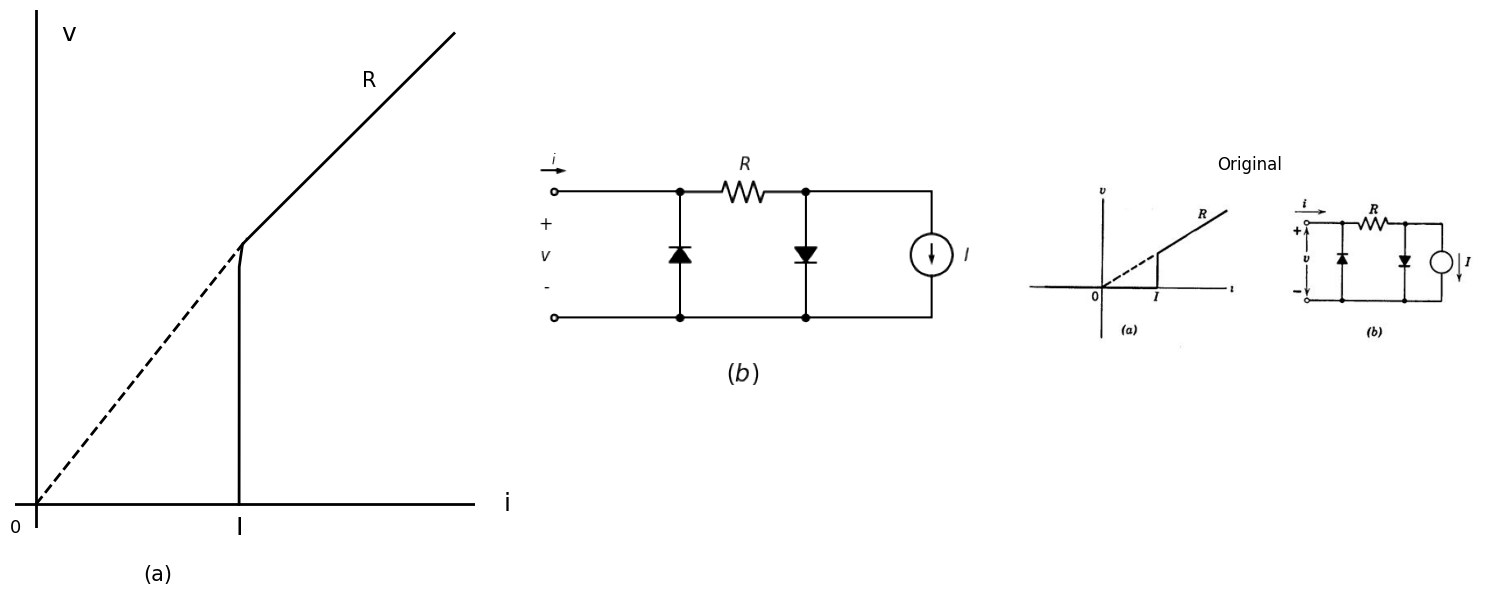

In [174]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
l0 = d.add(elm.Line().right().dot())
D1 = d.add(elm.Diode(fill=True).down().reverse().dot())
d += ( R1 := elm.Resistor().right().at(D1.start).label(['$R$'] , ofst=0.2 , fontsize = 16).dot())
D2 = d.add(elm.Diode(fill=True).down().dot())
l1 = d.add(elm.Line().left())
l2 = d.add(elm.Line().left().dot(open=True))
l3 = d.add(elm.Line().right().at(R1.end))
d += ( I := elm.SourceI().down().label(['$I$'] , ofst=-1.4 , fontsize = 16))
l4 = d.add(elm.Line().left())
d += elm.Gap().up().at((-1.2,-3)).label(['-' , '$v$' , '+'], ofst=-1 , fontsize = 16)
d += elm.Gap().up().at((4.5,-5.5)).label('$(b)$'  , fontsize = 22)
d += elm.Arrow().length(0.6).at((-0.3,0.5)).right().label('$ i $', fontsize = 13)
d.save('./Drawings/fig29.png')
d.save('./Drawings/fig29.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig29.png')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display

#rcParams['font.weight'] = 'bold'
x_values = [-4, 1.2]  
y_values = [0, 113]
circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 1@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,circuit.gnd ,'1', model = 'BAV21')
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.I('fixed', '2', circuit.gnd, 1@u_A)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0,200, 0.1))
axs[0].plot(u_A(-analysis.Vth),analysis['1'],'black',linestyle='-',linewidth=2)

axs[0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[0].text(4.2, 180, 'R', ha='center', va='center', fontsize = 15)
axs[0].text(-4.5, -10, '0', ha='center', va='center', fontsize = 13)
axs[0].text(-3.2, 200, 'v', ha='center', va='center', fontsize = 18)
axs[0].text(7.6, 0.02, 'i', ha='center', va='center', fontsize = 18)
axs[0].text(1.0, -10, 'I', ha='center', va='center', fontsize = 18)
axs[0].text(-1, -30, '(a)', ha='center', va='center', fontsize=15)
axs[0].axhline(0, color='black',linewidth=2, ls='-')
axs[0].axvline(-4, color='black',linewidth=2, ls='-')
#axs[0].set_xlim(-5, 15)
#axs[0].set_ylim(-2, 5)
axs[0].axis('off')  # Hide axes for image display

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/29.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig. 7.16.Construction of a piecewise-linear model for the cryotron.

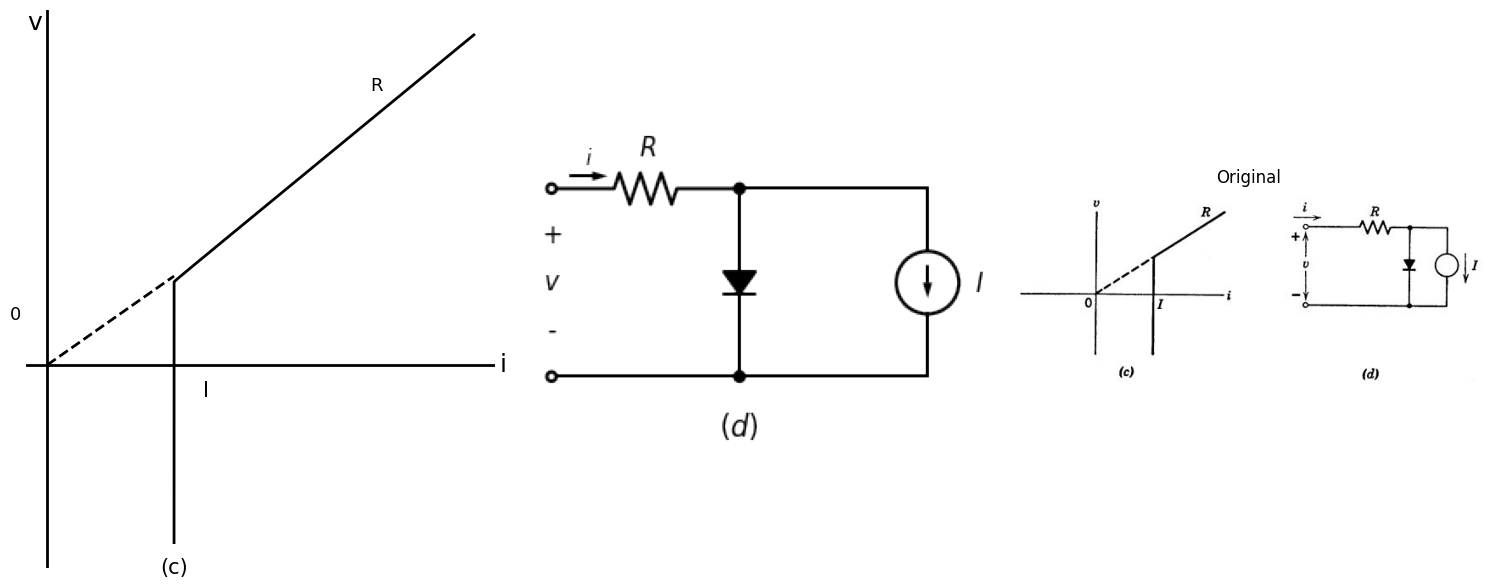

In [188]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
d += ( R1 := elm.Resistor().right().label(['$R$'] , ofst=0.2 , fontsize = 16).dot())
D1 = d.add(elm.Diode(fill=True).down().dot())
l1 = d.add(elm.Line().left().dot(open=True))
l2 = d.add(elm.Line().right().at(R1.end))
d += ( I := elm.SourceI().down().label(['$I$'] , ofst=-1.4 , fontsize = 16))
l3 = d.add(elm.Line().left())
d += elm.Gap().up().at((-1.0,-3)).label(['-' , '$v$' , '+'], ofst=-1 , fontsize = 16)
d += elm.Gap().up().at((3.0,-5)).label('$(d)$'  , fontsize = 18)
d += elm.Arrow().length(0.6).at((0.3,0.2)).right().label('$ i $', fontsize = 13)
d.save('./Drawings/fig30.png')
d.save('./Drawings/fig30.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig30.png')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display

#rcParams['font.weight'] = 'bold'
x_values = [3, 5]  
y_values = [-30, 5]
circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0.5@u_Ohm)
circuit.I('fixed', '2', circuit.gnd, 5@u_A)
circuit.D(1,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0].plot(u_A(-analysis.Vth),analysis['1'],'black',linestyle='-',linewidth=2)
axs[0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[0].text(8.2, 80, 'R', ha='center', va='center', fontsize = 13)
axs[0].text(2.5, -10, '0', ha='center', va='center', fontsize = 13)
axs[0].text(2.8, 105, 'v', ha='center', va='center', fontsize = 18)
axs[0].text(10.2, -30, 'i', ha='center', va='center', fontsize = 18)
axs[0].text(5, -110, '(c)', ha='center', va='center', fontsize=15)
axs[0].text(5.5, -40, 'I', ha='center', va='center', fontsize=15)
axs[0].axhline(-30, color='black',linewidth=2, ls='-')
axs[0].axvline(3, color='black',linewidth=2, ls='-')
#axs[0].set_xlim(-15, 15)
#axs[0].set_ylim(-15,15)
axs[0].axis('off')  # Hide axes for image display

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/30.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()


## Fig. 7.16.Construction of a piecewise-linear model for the cryotron.

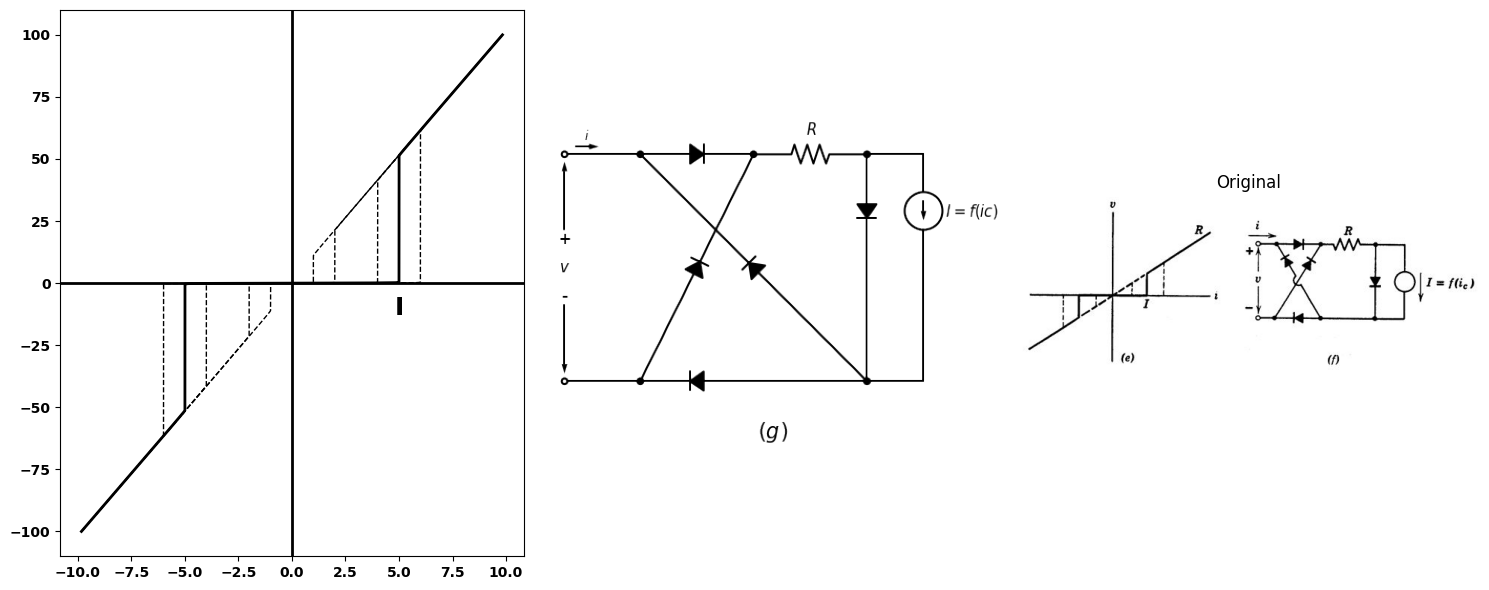

In [9]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
l1 = d.add(elm.Line().right().length(2).dot())
d += elm.Gap().up().at((-1,-4.5)).label(['-' , '$v$' , '+'], ofst=-1 , fontsize = 16)
D1 = d.add(elm.Diode(fill=True).right().at(l1.end).dot())
d += ( R1 := elm.Resistor().right().label(['$R$'] , ofst=0.2 , fontsize = 16).dot())
l2 = d.add(elm.Line().right().length(1.5))
d += ( I := elm.SourceI().down().label(['$I=f(ic)$'] , ofst=-2.5, fontsize = 16))
l7 = d.add(elm.Line().down())
l8 = d.add(elm.Line().left().length(1.5))
d += elm.Dot(open=True).at((0,-6))
l5 = d.add(elm.Line().right().length(2).dot())
D2 = d.add(elm.Diode(fill=True).right().reverse())
l6 = d.add(elm.Line().right().length(3).dot())
D3 = d.add(elm.Diode(fill=True).endpoints(l5.end,D1.end))
D4 = d.add(elm.Diode(fill=True).endpoints(l6.end,D1.start))
D5 = d.add(elm.Diode(fill=True).down().at(R1.end))
l9 = d.add(elm.Line().down())
d += elm.Arrow().right().length(1.8).at((0,-2)).color('black').up()
d += elm.Arrow().left().length(1.8).at((0,-4)).color('black').down()
d += elm.Arrow().length(0.6).at((0.3,0.2)).right().label('$ i $', fontsize = 13)
d += elm.Gap().up().at((5.5,-8.5)).label('$(g)$'  , fontsize = 22)
d.save('./Drawings/fig31.png')
d.save('./Drawings/fig31.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig31.png')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display

#rcParams['font.weight'] = 'bold'
circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 0@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 10@u_Ohm)
circuit.I('fixed', '3', '4', 5@u_A)
circuit.D(2,'3' ,'4', model = 'BAV21')
circuit.D(3,'4' , circuit.gnd, model = 'BAV21')
circuit.D(4, circuit.gnd ,'2', model = 'BAV21')
circuit.D(5,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0].plot(u_A(-analysis.Vth), analysis['1'], 'black', linewidth=2 )

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 0@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 10@u_Ohm)
circuit.I('fixed', '3', '4', 6@u_A)
circuit.D(2,'3' ,'4', model = 'BAV21')
circuit.D(3,'4' , circuit.gnd, model = 'BAV21')
circuit.D(4, circuit.gnd ,'2', model = 'BAV21')
circuit.D(5,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0].plot(u_A(-analysis.Vth), analysis['1'], 'black', linewidth=1,linestyle='--' )

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 0@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 10@u_Ohm)
circuit.I('fixed', '3', '4', 4@u_A)
circuit.D(2,'3' ,'4', model = 'BAV21')
circuit.D(3,'4' , circuit.gnd, model = 'BAV21')
circuit.D(4, circuit.gnd ,'2', model = 'BAV21')
circuit.D(5,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0].plot(u_A(-analysis.Vth), analysis['1'], 'black', linewidth=1,linestyle='--' )

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 0@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 10@u_Ohm)
circuit.I('fixed', '3', '4', 2@u_A)
circuit.D(2,'3' ,'4', model = 'BAV21')
circuit.D(3,'4' , circuit.gnd, model = 'BAV21')
circuit.D(4, circuit.gnd ,'2', model = 'BAV21')
circuit.D(5,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0].plot(u_A(-analysis.Vth), analysis['1'], 'black', linewidth=1,linestyle='--' )

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 0@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 10@u_Ohm)
circuit.I('fixed', '3', '4', 1@u_A)
circuit.D(2,'3' ,'4', model = 'BAV21')
circuit.D(3,'4' , circuit.gnd, model = 'BAV21')
circuit.D(4, circuit.gnd ,'2', model = 'BAV21')
circuit.D(5,'4' ,'1', model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[0].plot(u_A(-analysis.Vth), analysis['1'], 'black', linewidth=1,linestyle='--' )
axs[0].text(5, -10, 'I', ha='center', va='center', fontsize = 18)
axs[0].axhline(0, color='black',linewidth=2, ls='-')
axs[0].axvline(0, color='black',linewidth=2, ls='-')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/31.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

In [4]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
from matplotlib import rcParams
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()

from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

rcParams['font.weight'] = 'bold'
figure = plt.figure(figsize=(15, 10))


#@interact(Mode1=(True) , Mode2=(True),  Mode3=(True))
@interact(E=widgets.IntSlider(min=0, max=7, step=1, value=1))
def response(E=1):
    circuit = Circuit('Control Vaves') 
    circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 0@u_Ohm ,TT = 3.48E-9)
    Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
    circuit.D(1,'1' ,'2', model = 'BAV21')
    circuit.R(1, '2', '3', 10@u_Ohm)
    circuit.I('fixed', '3', '4', E@u_A)
    circuit.D(2,'3' ,'4', model = 'BAV21')
    circuit.D(3,'4' , circuit.gnd, model = 'BAV21')
    circuit.D(4, circuit.gnd ,'2', model = 'BAV21')
    circuit.D(5,'4' ,'1', model = 'BAV21')
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
    plt.plot(u_A(-analysis.Vth), analysis['1'], 'black', linewidth=2 )
    plt.text(5, -10, 'I', ha='center', va='center', fontsize = 18)

    plt.axhline(0, color='black',linewidth=2, ls='-')
    plt.axvline(0, color='black',linewidth=2, ls='-')

<Figure size 1500x1000 with 0 Axes>

interactive(children=(IntSlider(value=1, description='E', max=7), Output()), _dom_classes=('widget-interact',)…

## Fig. 7.16.Construction of a piecewise-linear model for the cryotron.

For a circuit model of the cryotron let us begin with the curve shown in Fig. 7.16(a), which can be synthesized as the circuit indicated in (b). Connection of two such circuits in series opposition yields a single symmetric cryotron curve.  It is interesting to observe that the circuit in Fig.7.16(b) is a very close cousin of that in Fig. 7.3(e).  

If the current source **I** were connected across the resistance **R** instead of across the diode, the two circuits would be equivalent. We really should not expect them to be twins because the cryotron curves do not sweep out the Pntire passive first and third quadrants of the valve plane.
An alternative synthesis of the circuit model,  which utilizes more diodes but only one controlled current source **I** , begins with the curve of Fig.7.16(c) and the associated elementary circuit indicated in (d). Connection of this circuit to the bridge-type energy valve yields a satisfactory cryotron model (f) which has the representative  curve shown in (e).


# 7.8	The Thyratron

The thyratron is a hot-cathode gas triode which is used as a switch or relay. In preparation for the discussion of the thyratron, Fig. 7.17 reiterates the characteristics of a simple gas diode circuit. The black dot in the circuit symbol for the diode represents a gas molecule and indicates that the gas pressure, though much smaller than atmospheric pressure, is nevertheless much greater than that in a good vacuum diode.  The applied voltage **eb** must be connected to the diode through some load resistance **Rb** in order to limit the value of plate current when the tube conducts.  The presence of resistance **Rb** in Fig. 7.17(a) also permits us to describe the operation of the circuit in terms of the applied voltage variable **eb** alone, as illustrated in Fig. 7.17(b).  If the tube is not already conducting, then it fires upon crossing from region **B** into region **C**, and if it is not already nonconducting, then it extinguishes upon crossing from region **B** into region **A**. In the memory region **B** the tube retains either state **A** or state **C**, whichever of the two was experienced most recently.

The explanation is as follows.  With no gas in the tube the diode curve has a shape indicated by the dashed curve in Fig. 7.17(c). When gas is introduced, any plate current larger than some critical value ibo produces significant ionization of the gas molecules. These positive ions are heavy and remain in the interelectrode space for a relatively long time, thereby producing a heavy positive space charge which helps the plate voltage draw electrons out of the cathode. The hysteresis or "memory" exhibited by the circuit becomes apparent when we plot the applied voltage **eb**, rather than the plate voltage **eb**, as  shown in Fig.7.17(d).  Increasing the applied voltage from zero, we reach point **a**, at which the tube fires and the operating point jumps to **b**. A decrease in the applied voltage then brings us to point **c**, whence a slight further decrease causes the tube to extinguish and the operating point returns to the low-current portion of the curve at point **d**.
The basic thyratron circuit is depicted in Fig. 7.18(a).  With no gas in the tube we should have the ordinary vacuum-triode curves shown in (d).  For values of plate current less than the critical ionization current **ib0** the vacuum-triode curves (d) and the thyratron curves are very much the same.




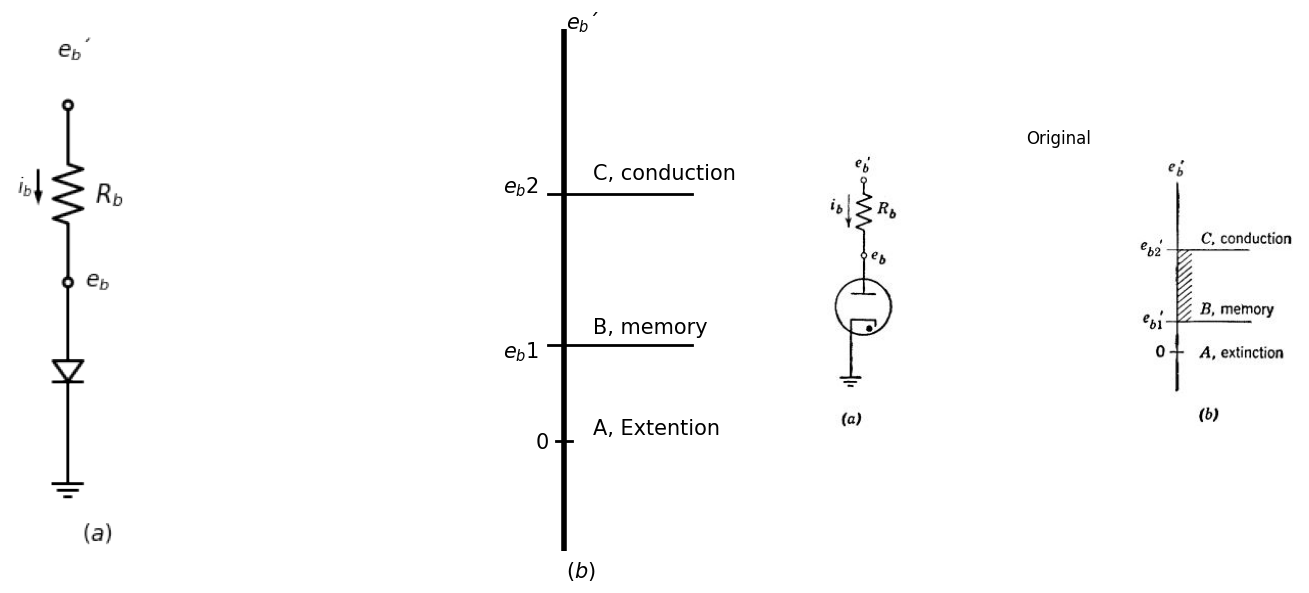

In [17]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
d += ( R1 := elm.Resistor().down().label(['$R_b$'] , ofst=-1.2 , fontsize = 16).dot(open=True))
D1 = d.add(elm.Diode().down())
d += elm.Ground()
d += elm.Arrow().length(0.6).at((-0.5,-1.1)).down().label('$ i_b $', fontsize = 13)
d += elm.Gap().up().at((0.5,-8.5)).label('$ (a) $'  , fontsize = 15)
d += elm.Gap().up().at((0.5,-4.3)).label('$ e_b $'  , fontsize = 15)
d += elm.Gap().up().at((0.1,-0.3)).label('$ e_b´ $'  , fontsize = 15)
d.save('./Drawings/fig32.png')
d.save('./Drawings/fig32.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig32.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display

x_values = [-1, 8]  
y_values = [3.5, 3.5]  

x1_values = [-1, 8]  
y1_values = [9, 9]

x2_values = [-0.5,0.5]  
y2_values = [0, 0]

axs[1].plot(x_values, y_values, ls='-', color='black', linewidth=2)
axs[1].plot(x1_values, y1_values, ls='-', color='black', linewidth=2)
axs[1].plot(x2_values, y2_values, ls='-', color='black', linewidth=2)
#axs[1].axhline(0, color='black',linewidth=4, ls='-')
axs[1].axvline(0, color='black',linewidth=4, ls='-')
axs[1].text(-1.8,-0.3, '0', fontsize=15)
axs[1].text(-3.8,3, '$ e_b1 $', fontsize=15)
axs[1].text(-3.8,9, '$ e_b2 $', fontsize=15)
axs[1].text(1.8,9.5, 'C, conduction', fontsize=15)
axs[1].text(1.8,3.9, 'B, memory', fontsize=15)
axs[1].text(1.8,0.2, 'A, Extention', fontsize=15)
axs[1].text(0.1,15, '$ e_b´ $', fontsize=15)
axs[1].text(0.1,-5, '$ (b) $', fontsize=15)
axs[1].set_xlim(-15, 15)
axs[1].set_ylim(-4, 15)
axs[1].axis('off')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/32.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()


## Fig.  7.17. Gas diode properties.	(a)  Gas diode;	(b) State-transition  voltages


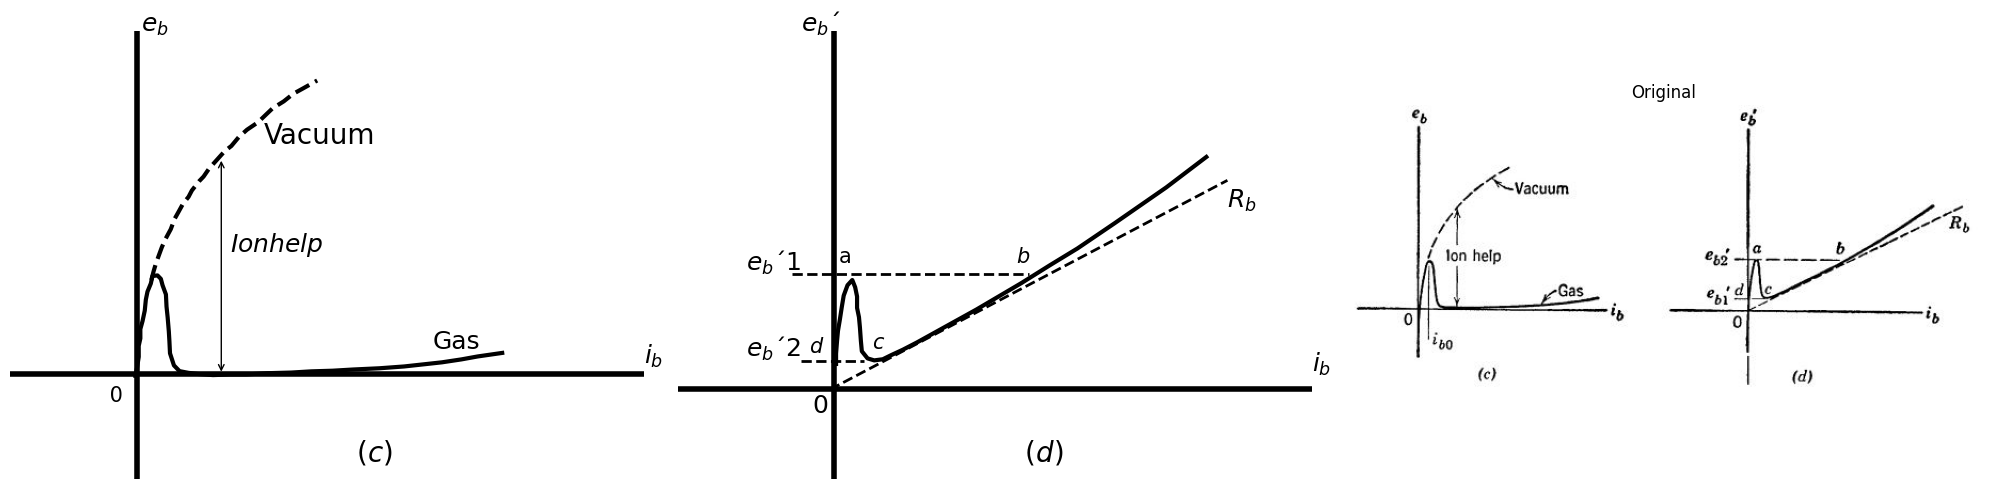

In [100]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
 
#Data1
P1 = [-0.031292295,0.007758279,0.046691583,0.04594888,0.085077633,0.084452198,0.136754168,0.188899779,0.214581688,0.253671351,0.332397933,0.371526686,
      0.490398353,0.569906728,0.609973633,0.689872905,0.703906094,0.73107341,0.758436175,0.772313005,0.786346194,0.879653221,1.01216718,1.223681349,
      1.448368734,1.805179182,2.214721585,2.597878466,3.086655617,3.654745695,4.13031054,4.632339087,5.121116239,5.742016452,6.323240657,6.838364242,
      7.221403854,7.683639123,8.066600556,8.647707492]
F1 = [-0.238083664,-0.006106057,0.272241664,0.565919048,0.766983246,1.014290517,1.230853767,1.509243835,1.803005913,2.019526816,2.236174761,
      2.437238959,2.453076788,2.360590644,2.190693937,1.943640749,1.619092304,1.325499615,0.954623403,0.691901775,0.36735333,0.043058968,
      -0.111084605,-0.156777164,-0.186970672,-0.216740708,-0.199971242,-0.198743175,-0.166262923,-0.148985291,-0.116547386,-0.09948149,-0.067001237,
      -0.034097513,0.014135874,0.07761423,0.12521241,0.203978082,0.282489671,0.377093171]

P2 = [0.345375702,0.397638582,0.449979641,0.528628044,0.594181409,0.686081208,0.804366529,0.896149059,0.988166127,1.093317321,1.224971308,1.303815159,
      1.474949705,1.580335438,1.711911245,1.896297187,2.080683129,2.238878997,2.410052633,2.607729061,2.87146702,3.055931142,3.21404883,3.477825879,
      3.701926919,3.926184318,4.269157025]
F2 = [2.328957334,2.560977289,2.762083835,3.009645188,3.210794081,3.442941077,3.690629472,3.969146581,4.154923464,4.371656102,4.557560027,4.727837858,
      4.975695641,5.099688053,5.316505386,5.548948812,5.781392238,5.921010744,6.153411823,6.354984187,6.556768287,6.758298304,6.928830218,7.115157614,
      7.316814672,7.456644913,7.6741398]

axs[0].plot(P1, F1, 'black',linestyle='-', linewidth=3)
axs[0].plot(P2, F2, 'black',linestyle='--', linewidth=3)
axs[0].axhline(-0.2, color='black',linewidth=4, ls='-')
axs[0].axvline(0, color='black',linewidth=4, ls='-')
axs[0].text(12,0.1, '$ i_b $', fontsize=18)
axs[0].text(7,0.5, 'Gas', fontsize=18)
axs[0].text(0.1,9, '$ e_b $', fontsize=18)
axs[0].text(2.2,3.1, '$ Ion help $', fontsize=18)
axs[0].text(3,6, 'Vacuum', fontsize=20)
axs[0].annotate('', xy=(2, -0.2), xytext=(2, 5.6), arrowprops=dict(arrowstyle='<->'))
axs[0].text(-0.8,-0.9, ' 0', fontsize=15)
axs[0].text(5,-2.5, ' $ (c) $', fontsize=20)
axs[0].set_xlim(-3, 12)
axs[0].set_ylim(-3,9)
axs[0].axis('off')

#Data2
P3 = [0.738934056,0.738934056,0.761517615,0.784101174,0.829268293,0.874435411,0.919602529,1.009936766,1.122854562,1.190605239,1.235772358,1.235772358,
      1.280939476,1.303523035,1.326106594,1.348690154,1.484191509,1.642276423,1.845528455,2.048780488,2.319783198,2.658536585,4.058717254,5.120144535,
      5.79765131,6.452574526,7.333333333,8.552845528,9.501355014]
F3 = [0.082049442,0.358975141,0.691586169,0.968812059,1.274030708,1.606941927,1.912160577,2.190287037,2.330250839,2.137303421,1.888670674,1.584052405,
      1.335419657,1.058794149,0.699090931,0.422465423,0.230418576,0.17713477,0.207529054,0.321001047,0.463066182,0.661417028,1.538498503,2.244921701,
      2.724701103,3.176487744,3.852816849,4.810574509,5.626267035]

x_values = [0.6, 10]  
y_values = [-0.6, 5]  

x1_values = [-0.3, 5.3]  
y1_values = [2.5, 2.5]

x2_values = [-0.1, 1.4]  
y2_values = [0.15, 0.15]

axs[1].plot(P3, F3, 'black',linestyle='-', linewidth=3)
axs[1].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[1].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
axs[1].plot(x2_values, y2_values, ls='--', color='black', linewidth=2)
axs[1].axhline(-0.6, color='black',linewidth=4, ls='-')
axs[1].axvline(0.7, color='black',linewidth=4, ls='-')
axs[1].text(12,-0.1, '$ i_b $', fontsize=18)
axs[1].text(0.8,2.8, 'a', fontsize=15)
axs[1].text(-0.1,9, '$ e_b´ $', fontsize=18)
axs[1].text(5,2.8, '$ b $', fontsize=15)
axs[1].text(1.6,0.5, '$ c $', fontsize=15)
axs[1].text(0.1,0.4, '$ d $', fontsize=15)
axs[1].text(0,-1.2, ' 0', fontsize=18)
axs[1].text(5,-2.5, ' $ (d) $', fontsize=20)
axs[1].text(-1.4,2.6, '$ e_b´1 $', fontsize=18)
axs[1].text(-1.4,0.3, '$ e_b´2 $', fontsize=18)
axs[1].text(10,4.3, '$ R_b $', fontsize=18)
axs[1].set_xlim(-3, 12)
axs[1].set_ylim(-3,9)
axs[1].axis('off')

img_sample = mpimg.imread('images/33.JPG')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

## Fig.  7.17. Gas diode properties. (c) The diode curve; (d) The curve of applied voltage, showing transition threshold

However, once there is appreciable ionization the thyratron curves drop rapidly to a very low value of plate volta Once the thyratron fires or conducts, a sheet of positive ionsforms aroud the grid wires and the grid therefore losses control-a control which cannot be regained until the thyratron is once more extinguished lowering	the  applied  plate voltage  **eb'** to a sufficiently  small value Figure  7.18(b)	shows  the three regions of	operation  in  the  plane of applied plate voltage **eb'** versus applied control voltage **ec'** .	For negative values of **ec'**, a larger **eb1** is required in order to fire the tube.	Just  as before, the tube remains nonconducting until the operating point crosses the boundary  from region **B** into region **C** and then remains conducting until the operating point next crosses from region **B** into region **A**. 



C:\Users\ghasr\AppData\Local\Temp\ipykernel_8304\890168304.py:38: RuntimeWarning: divide by zero encountered in divide
  y = 1 /(0.5* x)


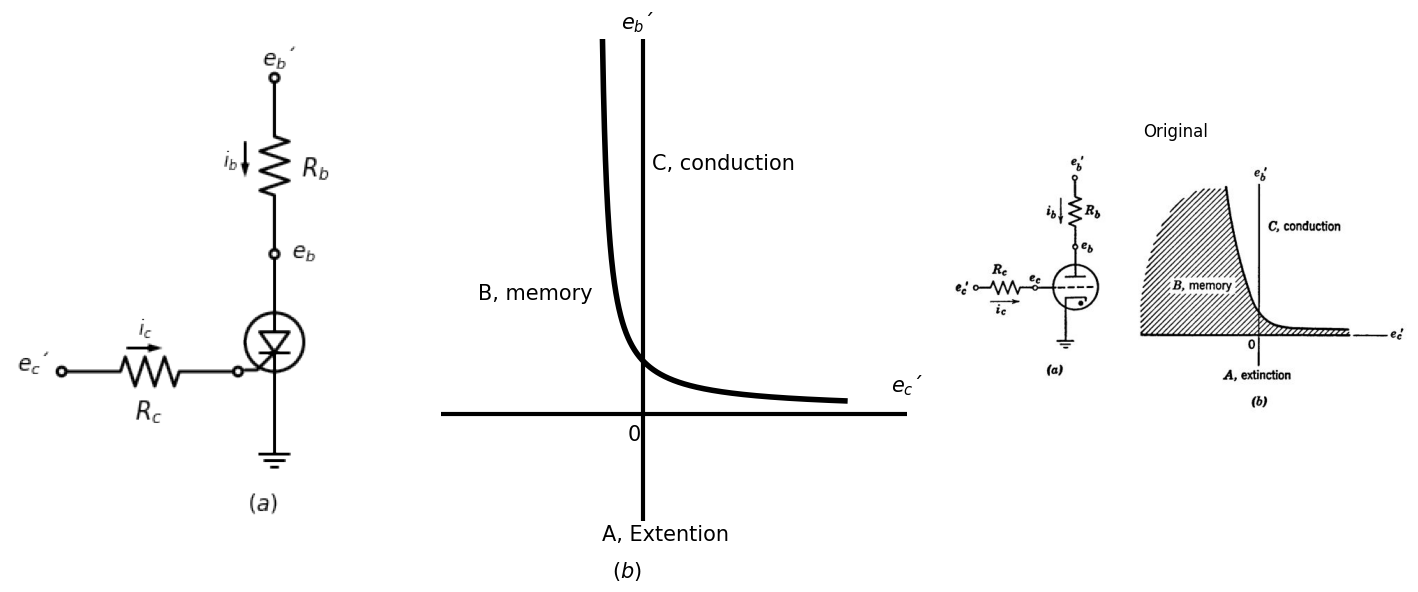

In [44]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 3, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

d += elm.Dot(open=True)
d += ( R1 := elm.Resistor().down().label(['$R_b$'] , ofst=-1.2 , fontsize = 16).dot(open=True))
D1 = d.add(elm.SCR().down())
E1 = d.add(elm.Source().up())
d += elm.Ground().at(E1.start)
d += elm.Dot(open=True).at((-0.62,-5))
d += ( R2 := elm.Resistor().left().label(['$R_c$'] , ofst=-1.2 , fontsize = 16).dot(open=True))
d += elm.Arrow().length(0.6).at((-0.5,-1.1)).down().label('$ i_b $', fontsize = 13)
d += elm.Arrow().length(0.6).at((-2.5,-4.6)).right().label('$ i_c $', fontsize = 13)
d += elm.Gap().up().at((-0.2,-8.5)).label('$ (a) $'  , fontsize = 15)
d += elm.Gap().up().at((0.5,-4.3)).label('$ e_b $'  , fontsize = 15)
d += elm.Gap().up().at((0.1,-0.9)).label('$ e_b´ $'  , fontsize = 15)
d += elm.Gap().up().at((-4.1,-6.1)).label('$ e_c´ $'  , fontsize = 15)
d.save('./Drawings/fig32.png')
d.save('./Drawings/fig32.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig32.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display

x = np.linspace(0, 8, 1000)
y = 1 /(0.5* x)
y[np.isinf(y)] = np.nan  # Handle the asymptote by setting infinity to NaN

axs[1].plot(x, y,linewidth=4, ls='-' , color='black')
axs[1].axhline(-0.1, color='black',linewidth=3, ls='-')
axs[1].axvline(1.5, color='black',linewidth=3, ls='-')
axs[1].text(1,-0.8, '0', fontsize=15)
axs[1].text(9.5,0.5, '$ e_c´ $', fontsize=15)
axs[1].text(1.8,6.5, 'C, conduction', fontsize=15)
axs[1].text(-3.8,3.0, 'B, memory', fontsize=15)
axs[1].text(0.2,-3.5, 'A, Extention', fontsize=15)
axs[1].text(0.8,10.3, '$ e_b´ $', fontsize=15)
axs[1].text(0.5,-4.5, '$ (b) $', fontsize=15)
axs[1].set_xlim(-5, 10)
axs[1].set_ylim(-3,10)
axs[1].axis('off')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/34.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7. 18.Thyratron  properties.	(a)  The thyratron;  (b)  State-transition curves in the plane  of  applied  voltages.

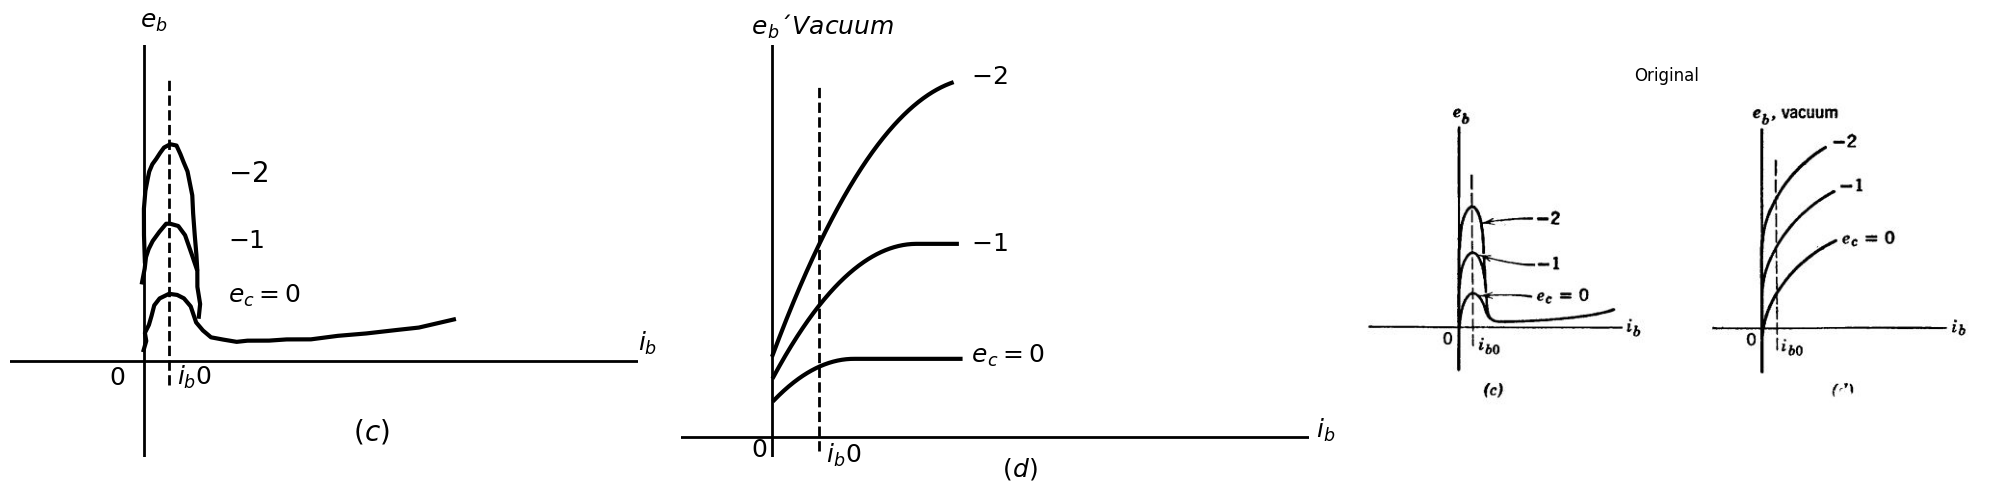

In [94]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Doc.ExampleTools import find_libraries
from PySpice.Probe.Plot import plot
from PySpice.Spice.Library import SpiceLibrary
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
 
#Data1
P1 = [0.193528677,0.25732539,0.224438634,0.320582976,0.384379689,0.448086548,0.576578519,0.802023524,0.995660026,1.157218463,1.319136318,1.384280849,
      1.44942538,1.611343235,1.80542901,2.095928691,2.418686147,2.67665849,2.902462913,3.192782885,3.612044101,4.192684045,4.837569974,5.514803533,
      6.256462787,6.772407472,7.610480632]
F1 = [0.10583066,0.373453379,0.607326738,0.841631399,1.109254118,1.41030272,1.611289323,1.745747635,1.712968704,1.61323018,1.379788123,1.146022589,
      0.912257056,0.678814999,0.47890665,0.413025312,0.347251799,0.381540286,0.382295064,0.383265493,0.418093107,0.420033965,0.522468124,0.591584225,
      0.694341861,0.762918834,0.99970348]

P2 = [0.155969485,0.21940678,0.25076601,0.314652577,0.41079692,0.571366957,0.732026849,0.828800173,1.02252653,1.184534239,1.347350639,1.477639701,
      1.478897665,1.544761032,1.513491657]
F2 = [2.077849961,2.479176214,2.813542874,3.047739709,3.28204437,3.549990565,3.784510877,3.784834353,3.718629539,3.451761598,2.884060706,2.416529639,
      1.94856727,1.447394668,1.079602124]

P3 = [0.22346313,0.202767469,0.200687504,0.236618914,0.29168601,0.328449407,0.402548191,0.495470666,0.588341142,0.681263618,0.830345171,0.979790719,
      1.073805176,1.149099941,1.243166397,1.300105463,1.357044528,1.377116199,1.416167558,1.455010921,1.474770596]
F3 = [2.692436445,3.446777667,4.22052497,4.742929198,5.091302681,5.304207987,5.517238092,5.672299547,5.846704685,6.001766141,6.098983745,6.060795572,
      5.809639693,5.577765098,5.307265537,4.959266448,4.611267358,4.089050328,3.4508336,2.889991604,2.483836668]

x_values = [0.8, 0.8]  
y_values = [-0.9, 8] 
axs[0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[0].plot(P1, F1, 'black',linestyle='-', linewidth=3)
axs[0].plot(P2, F2, 'black',linestyle='-', linewidth=3)
axs[0].plot(P3, F3, 'black',linestyle='-', linewidth=3)
axs[0].axhline(-0.2, color='black',linewidth=2, ls='-')
axs[0].axvline(0.2, color='black',linewidth=2, ls='-')
axs[0].text(12,0.1, '$ i_b $', fontsize=18)
axs[0].text(2.2,1.5, '$ e_c=0 $', fontsize=18)
axs[0].text(0.1,9.5, '$ e_b $', fontsize=18)
axs[0].text(2.2,3.1, '$ -1 $', fontsize=18)
axs[0].text(2.2,5, '$ -2 $', fontsize=20)
axs[0].text(-0.8,-0.9, ' 0', fontsize=18)
axs[0].text(1,-0.9, '$ i_b0 $', fontsize=18)
axs[0].text(5,-2.5, ' $ (c) $', fontsize=20)
axs[0].set_xlim(-3, 12)
axs[0].set_ylim(-3,9)
axs[0].axis('off')

x_values = [12, 12]  
y_values = [-7000, 180000]  

circuit = Circuit('NMOS')
circuit.model('2N7000', 'NMOS', L=100E-6, W=200E-6, Kp=0.13, Vto=2.475)
Vgate = circuit.V('gate','gate',circuit.gnd,   0@u_V)
circuit.R(2, 'drain', '2', 0.01@u_Ohm)
Vi = circuit.V('i', '2', circuit.gnd, 1@u_V)
circuit.MOSFET(1, 'drain', 'gate', circuit.gnd,circuit.gnd, model='2N7000')
for gate_voltage in np.arange(20,50, 10):
    gate_voltage = gate_voltage@u_V
    Vgate.dc_value = gate_voltage
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(5, 35, 0.1))
    axs[1].plot(analysis['drain'], u_mA(-analysis.Vi),linewidth=3, color='black')
    
axs[1].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[1].axhline(10, color='black',linewidth=2, ls='-')
axs[1].axvline(4.5, color='black',linewidth=2, ls='-')
axs[1].axis('off')
axs[1].text(0,205000, ' $ e_b´ Vacuum $ ', fontsize=18)
axs[1].text(0,-10000, ' $ 0 $ ', fontsize=18)
axs[1].text(12,-13000, ' $ i_b0 $ ', fontsize=18)
axs[1].text(90,0, ' $ i_b $ ', fontsize=18)
axs[1].text(35,38000, ' $ e_c=0 $ ', fontsize=18)
axs[1].text(35,95000, ' $ -1 $ ', fontsize=18)
axs[1].text(35,180000, ' $ -2 $ ', fontsize=18)
axs[1].text(40,-20000, ' $(d)$ ', fontsize=18)
axs[1].set_xlim(-10, 90)
axs[1].set_ylim(-10000,200000)

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/35.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig. 7. 18.	Thyratron  properties.(c)  Thyratron  curves;   (d)  Vacuum-triode  curves, for comparison.

Thus the thyratron is a self-holding relay, its advantage over similar electromechanical relays being its speed of operation.
Parts  (a)  and	(b)	of  Fig. 7.19 show  two possible combinations  of applied voltage with which thyratrons are sometimes operated. In each case the locus of operation is indicated by a dashed line. In Fig. 7.19(a) the tube fires at point p and extinguishes at point **q**, hence the conduction angle **ɵ** can be changed by varying the d-c component **E** of the control signal **ec'**. 


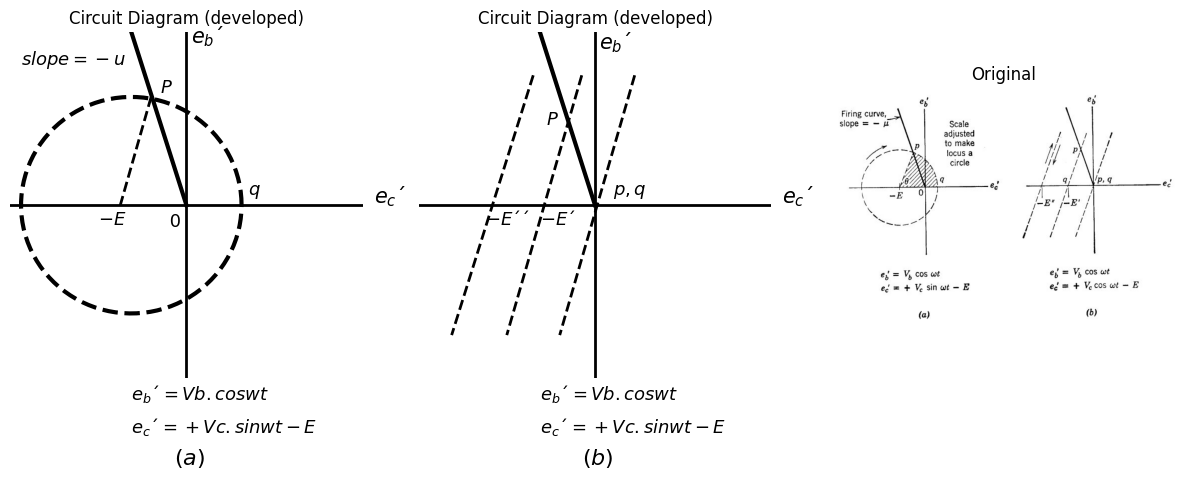

In [352]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 3, figsize=(12, 5))

# Parameters for the circle
r = 5  # Radius
h = -2.5  # X coordinate of center
k = 0  # Y coordinate of center

# Parameter t for the angle
theta = np.linspace(0, 2 * np.pi, 100)

# Parametric equations for the circle
x = h + r * np.cos(theta)
y = k + r * np.sin(theta)
x_values = [0, -2.5]  
y_values = [0, 8] 
x1_values = [-1.6, -3] 
y1_values = [5, 0]
x2_values = [-0.6, -4]  
y2_values = [6, -6]
x3_values = [1.8, -1.6]  
y3_values = [6, -6]
x4_values = [-2.8, -6.5]  
y4_values = [6, -6]


# Plot the circle
axs[0].plot(x, y,  color='black',linewidth=3, ls='--')
axs[0].plot(x_values, y_values, ls='-', color='black', linewidth=3)
axs[0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
axs[0].axhline(0, color='black',linewidth=2, ls='-')
axs[0].axvline(0, color='black',linewidth=2, ls='-')
axs[0].text(8.5,0.1, '$ e_c´ $', fontsize=15)
axs[0].text(2.8,0.5, '$ q $', fontsize=13)
axs[0].text(0.2,7.5, '$ e_b´ $', fontsize=15)
axs[0].text(-4,-0.9, '$ -E $', fontsize=13)
axs[0].text(-1.2,5.2, '$ P $', fontsize=13)
axs[0].text(-1,-1, ' 0', fontsize=13)
axs[0].text(-0.9,-12, ' $ (a) $', fontsize=16)
axs[0].text(-2.5,-9, '$ e_b´=Vb.coswt $', fontsize=13)
axs[0].text(-2.5,-10.5, '$ e_c´=+Vc.sinwt-E $', fontsize=13)
axs[0].text(-7.5,6.5, '$ slope=-u $', fontsize=13)
axs[0].set_xlim(-8, 8)
axs[0].set_ylim(-8,8)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

axs[1].plot(x_values, y_values, ls='-', color='black', linewidth=3)
axs[1].plot(x2_values, y2_values, ls='--', color='black', linewidth=2)
axs[1].plot(x3_values, y3_values, ls='--', color='black', linewidth=2)
axs[1].plot(x4_values, y4_values, ls='--', color='black', linewidth=2)
axs[1].axhline(0, color='black',linewidth=2, ls='-')
axs[1].axvline(0, color='black',linewidth=2, ls='-')
axs[1].text(8.5,0.1, '$ e_c´ $', fontsize=15)
axs[1].text(0.8,0.5, '$ p, q $', fontsize=13)
axs[1].text(0.2,7.2, '$ e_b´ $', fontsize=15)
axs[1].text(-5,-0.9, '$ -E´´ $', fontsize=13)
axs[1].text(-2.2,3.7, '$ P $', fontsize=13)
axs[1].text(-0.9,-12, ' $ (b) $', fontsize=16)
axs[1].text(-2.5,-9, '$ e_b´=Vb.coswt $', fontsize=13)
axs[1].text(-2.5,-10.5, '$ e_c´=+Vc.sinwt-E $', fontsize=13)
axs[1].text(-2.5,-0.9, '$  -E´ $', fontsize=13)
axs[1].set_xlim(-8, 8)
axs[1].set_ylim(-8,8)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Circuit Diagram (developed)')


# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/36.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()



## Fig.  7.19.	(a), (b) Loci of operation in the applied-voltage plane.

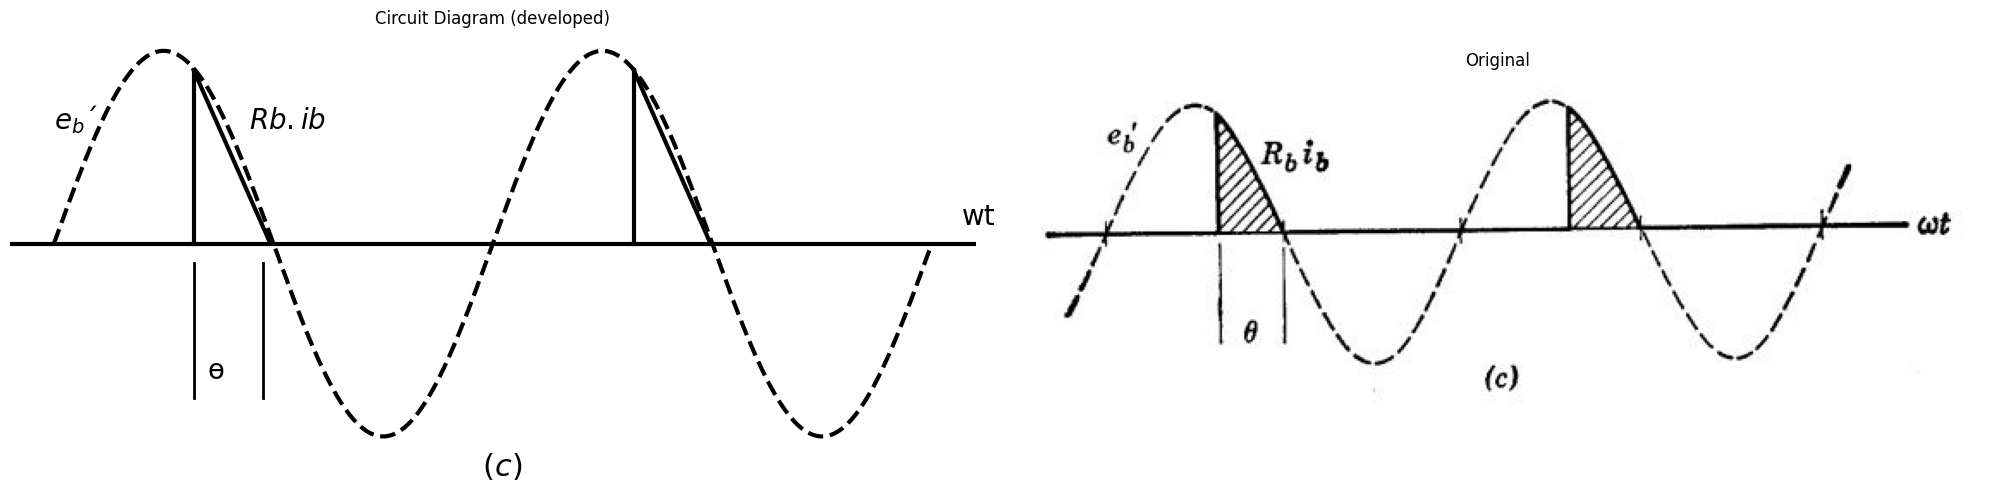

In [343]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(20, 5))

# Define the range and the sine function
x = np.linspace(0, 4 * np.pi, 1000)  # From 0 to 2π
y = np.sin(x)
x_values = [2, 2] 
y_values = [0, 0.9] 
x1_values = [2, 2] 
y1_values = [-0.1, -0.8]
x2_values = [8.3,8.3]  
y2_values = [0, 0.9]
x3_values = [3.1, 2]  
y3_values = [0, 0.9]
x4_values = [3, 3]  
y4_values = [-0.1, -0.8]
x5_values = [8.3, 9.4]  
y5_values = [0.9, 0]

# Plot the sine curve
axs[0].plot(x, y, label='y = sin(x)', color='black',linewidth=3, ls='--')
axs[0].axhline(0, color='black',linewidth=3, ls='-')
axs[0].plot(x_values, y_values, ls='-', color='black', linewidth=3)
axs[0].plot(x1_values, y1_values, ls='-', color='black', linewidth=2)
axs[0].plot(x2_values, y2_values, ls='-', color='black', linewidth=3)
axs[0].plot(x3_values, y3_values, ls='-', color='black', linewidth=3)
axs[0].plot(x4_values, y4_values, ls='-', color='black', linewidth=2)
axs[0].plot(x5_values, y5_values, ls='-', color='black', linewidth=3)
axs[0].text(2.8,0.6, '$ Rb.ib $', fontsize=20)
axs[0].text(0,0.6, '$ e_b´ $', fontsize=20)
axs[0].text(2.2,-0.7, 'ɵ', fontsize=20)
axs[0].text(13,0.1, 'wt', fontsize=20)
axs[0].text(6,-1.2, ' $ (c) $', fontsize=22)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')


# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/37.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

## Fig.  7.19. (c) Waveform of plate-load voltage **Rb.ib**, showing the conduction angle **ɵ**.

In this manner  the average power delivered  to the load **Rb** is adjustable by varying the control signal **E**.


When the two applied a-c signals are in phase, the locus of operation is a straight line as indicated in Fig. 7.19 (b). However, the tube still fires at point **p** and then extinguishes upon next reaching point **q**, so that the conduction angle is still under the influence of the control signal **E**. For zro **E** in Fig. 7.19 (b), conduction takes place over the complete positive half cycle of **eb'** and maximum power is delivered to the load. As **E** becomes larger in Fig. 7.19 (b), the conduction angle decreases to one quarter cycle and then drops suddenly to zero when the locus of operation no longer touches the firing curve. The scheme in Fig. 7.19(a) has the advantage of continuous control of the conduction angle through all values from zero to 𝚷.

Figure 7.19(c) shows the waveform of plate current for a resistive load **Rb**. Thyratrons are often used for speed control of small d-c motors, in which case the load (the motor winding) is not representable as a pure resistance.   Nevertheless, the signal at the thyratron grid still effects wide control over the time-average current supplied to the motor.


# SUPPLEMENTARY	READING

L. B. Arguimbau, R. B. Adler, Vacuum Tube Circuits and Transistors, John Wiley and Sons, New York, 1956.


H. Bruining, Physi,cs and Applications of Secondary Electron Emission, McGraw-Hill, New York, 1954.


W. G. Dow,  Fundamentals of  Engineering  Electronics, John Wiley and Sons,  New York,  '1952.


D. V. Geppert, Basic Electron  Tubes, McGraw-Hill, New York, 1951.


T. S. Gray, Ap plied Electronics, 2nd edition, John '\Viley and Sons, New York, 1954. Willis W. Harman, Fundamentals of  Electronic M otion, McGraw-Hill, New York, 1953.


Samuel Seely, Electron-Tube Circuits, McGraw-Hill, New  York,  1950. Samuel Seely, Electronic Engineering, McGraw-Hill, New York, 1956.


Karl R. Spangenberg, Fundamentals of Electron Devices, McGraw-Hill, New York, 1957.


Robert L. Sproull, M odern Physi,cs: A Textbook for Engineers, John Wiley and Sons, New York, 1956.


G. E. Valley and H. Wallman, Vacuum Tube Amplifiers, McGraw-Hill, New York, 1948.


# PROBLEMS (See Appendix C for Pentode Curves)

**7.1.**  If we imagine that each electron in the interelectrode space of a pentode is replaced by two electrons, then  (by superposition)  the electric potential is everywhere doubled and, since the electro'ns are moving freely under the action of the electric field, their kinetic energy at a chosen point in the tube must also double. Hence electron velocity (at a given point on the electron path) is multiplied by the square root of two. Now, in the light of the above discussion, what can you say about the change in the electrode currents of a pentode if all electrode poten tials, relative to the cathode, are doubled?

**7.2.**	Pentodes A and B are identical but B is operated at twice the screengrid voltage of **A** . Sketch and compare their plate curves. (The suppressor grid is internally connected to the cathode.)

**7.3.**	(a) Sketch a pentode curve of **ib** vs. **ec1** for fixed **eb** and **ec2**. (**ec3** is zero.) Use a value of **eb** only slightly to the right of the knee of the zero control-grid-voltage plate curve. Carry your sketch far enough positive and negative in **ec1** to show three distinctly different portions of the curve.

(b) The central portion may be closely approximated by a three-halves power law **ib = K 1(ee1 + k 2)H**.  why?

(c)  How do you account for the two outer portions of the curve?

(d)	How does the incremental transconductance **gm** (the slope of the curve) vary with **ib** in the central portion?

(e)	If **ib** reaches cutoff when **ee1** is about **10** volts negative and if **ib** equals **30** ma when **ee1** is zero, what is the incremental transconductance at **20** ma? At **2.5** ma?

**7.4.**	Suppose that the control grid, suppressor grid, and cathode of a pentode are grounded, the screen grid is held at a fixed positive potential, and the plate voltage is slowly increased, starting with a value several volts negative. Sketch the curve of **ib** vs. **eb** and explain its shape. For each of the three principal regions of this curve, describe the motion of an electron after it leaves the cathode.

**7.5.**	The plate current of a pentode with the suppressor connected to the cathode is a function of three voltages ib = f (ee 1, ec2, eb). The general threehalves power law states that if we change these voltages in proportion, the current will vary as the three-halves power of any of the voltages. In short, if **ib' = f ( ec1',ec2',eb')**, and if any three of  the four ratios

are equal, then the fourth equals the other three.

(a) Using Type II pentode plate curves measured	at  **ec2= 250** volts, determine **ib**, **rp**, and **gm**,. at the operating point **ec1 = -6**, **ec2 = 150**, **eb = 180** volts.

(b) Give directions for relabeling the **ib**, **eb**, and **ec1** scales of a set of pentode plate curves in order to make the same set of curves applicable at a new fixed **ec2**.


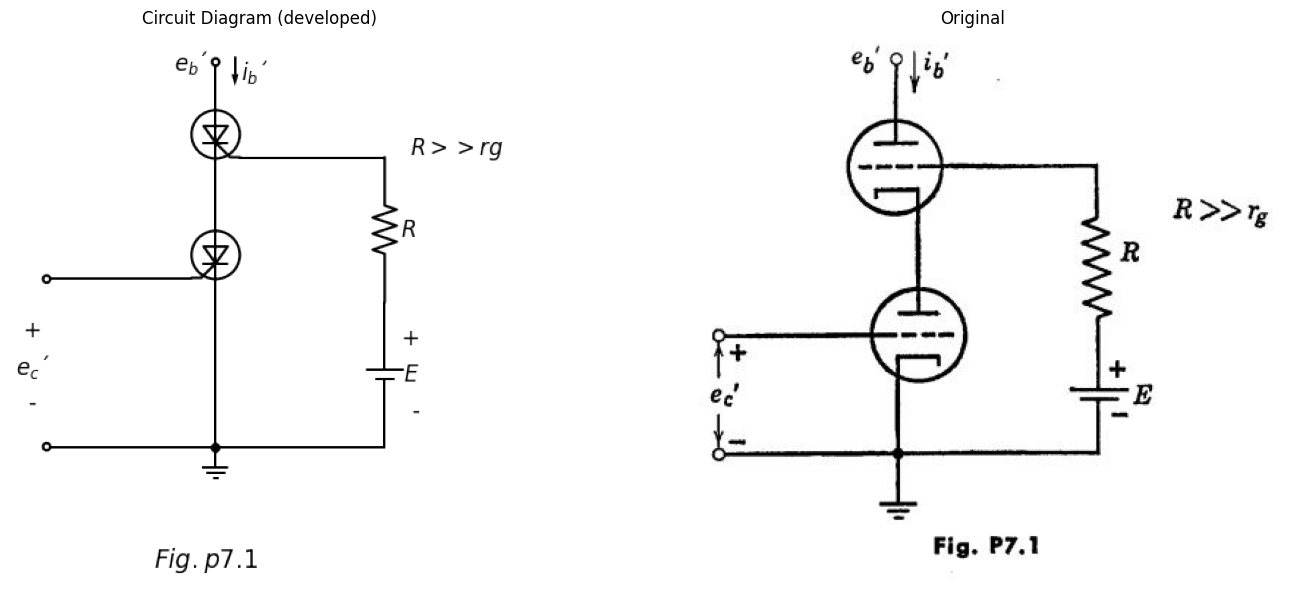

In [342]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()
D1 = d.add(elm.SCR().up().reverse().dot(open=True))
E1 = d.add(elm.Source().down())
l1 = d.add(elm.Line().down().length(2.5).at(D1.end))
D2 = d.add(elm.SCR().down())
E2 = d.add(elm.Source().up())
l2 = d.add(elm.Line().down().at(D1.start).length(5.0).dot())
d += elm.Ground()
l3 = d.add(elm.Line().right().at((0.5,1.0245)))
d += ( R1 := elm.Resistor().down().label(['$ R $'] , ofst=-0.9 , fontsize = 18))
d += ( E1 := elm.BatteryCell().down().label(['+','$ E $','-'] , ofst=-1.1,fontsize = 18))
l4 = d.add(elm.Line().left().length(7).dot(open=True))
l3 = d.add(elm.Line().left().at((-0.5,-1.5)).dot(open=True))
d += elm.Arrow().length(0.6).at((0.4,3.1)).down().label('$ i_b´ $', ofst=-0.7, fontsize = 18)
d += elm.Gap().up().at((-0.2,-8.5)).label('$ Fig.p7.1 $'  , fontsize = 20)
d += elm.Gap().up().at((5,0)).label('$ R>>rg $'  , fontsize = 18)
d += elm.Gap().up().at((-0.5,1.8)).label('$ e_b´ $'  , fontsize = 18)
d += elm.Gap().up().at((-3.8,-4.8)).label(['-','$ e_c´ $','+']  , fontsize = 18)
d.save('./Drawings/fig38.png')
d.save('./Drawings/fig38.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig38.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')


# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/38.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

**7.6.** Two identical triodes  are to be used in the circuit shown in Fig. P7.l to replace a pentode. (This is of ten called a "cascode" circuit.)  For  purpose of  design it is desirable to know the approximate composite characteristics of this circuit.

(a) Sketch and dimension the composite curves **eb'** vs. **ib'**, with **ec'** as a parameter. using piecewise-linear models for the triodes. Use idealized curves for the individual triodes with **µ = 50**, **rp = 40** kilohms.

(b) For the amplifier circuit shown in Fig. P7.2, what is the incremental voltage gain **Δe2/ Δe1**? Be sure to justif y your assumptions as to the conditions of the diodes in the piecewise-linear models.  The by-pass capacitor **C** is a short circuit for frequencies of interest.



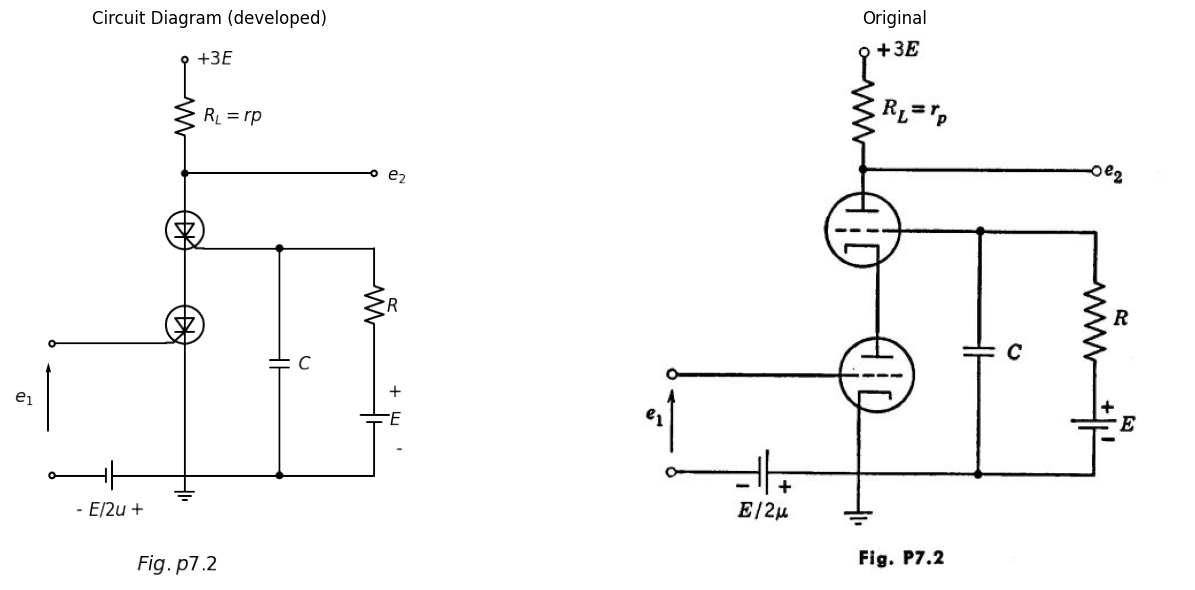

In [341]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()

D1 = d.add(elm.SCR().up().reverse().dot())
E1 = d.add(elm.Source().down())
d += ( R2 := elm.Resistor().up().label(['$ R_L=rp $'] , ofst=-2.3 , fontsize = 18).at(D1.end).dot(open=True))
l6 = d.add(elm.Line().right().length(5).at(D1.end).dot(open=True))
l1 = d.add(elm.Line().down().length(2.5).at(D1.end))
D2 = d.add(elm.SCR().down())
E2 = d.add(elm.Source().up())
l2 = d.add(elm.Line().down().at(D1.start).length(5.0))
d += elm.Ground()
l3 = d.add(elm.Line().right().at((0.5,1.0245)).length(2).dot())
l7 = d.add(elm.Line().right().length(2.5))
d += ( R1 := elm.Resistor().down().label(['$ R $'] , ofst=-0.9 , fontsize = 18))
d += ( E1 := elm.BatteryCell().down().label(['+','$ E $','-'] , ofst=-1.1,fontsize = 18))
l4 = d.add(elm.Line().left().length(5.5))
d += ( E2 := elm.BatteryCell().left().label(['+','$ E/2u $','-'] , ofst=-1.5,fontsize = 18).dot(open=True))
l5 = d.add(elm.Line().left().at((-0.5,-1.5)).dot(open=True))
l8 = d.add(elm.Line().down().length(1.55).at(l3.end))
d += ( C1 := elm.Capacitor().down().label(['$ C $'] , ofst=-1.1 , fontsize = 18))
l9 = d.add(elm.Line().down().length(1.45).dot())
d += elm.Arrow().length(1.8).at((-3.6,-3.8)).up().label('$ e_1 $', ofst=+0.4, fontsize = 18)
d += elm.Gap().up().at((-0.2,-8.5)).label('$ Fig.p7.2 $'  , fontsize = 20)
d += elm.Gap().up().at((0.8,4.8)).label('$ +3E $'  , fontsize = 18)
d += elm.Gap().up().at((5.6,1.7)).label('$ e_2 $'  , fontsize = 18)
d.save('./Drawings/fig39.png')
d.save('./Drawings/fig39.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig39.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/39.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()


**7.7.** (a) Using the plate characteristics for the Type I pentode, determine the values and proper algebraic signs of the constants **I0**, **gm**, and **rP** such that the linear equivalent circuit of Fig. P7.3 closely repre-sents the actual tube in the neighborhood of the following operating point:


**eb = 125** volts, **ec1 = -1** volt, **ec2 = 100** volts, **ec3 = 0**.


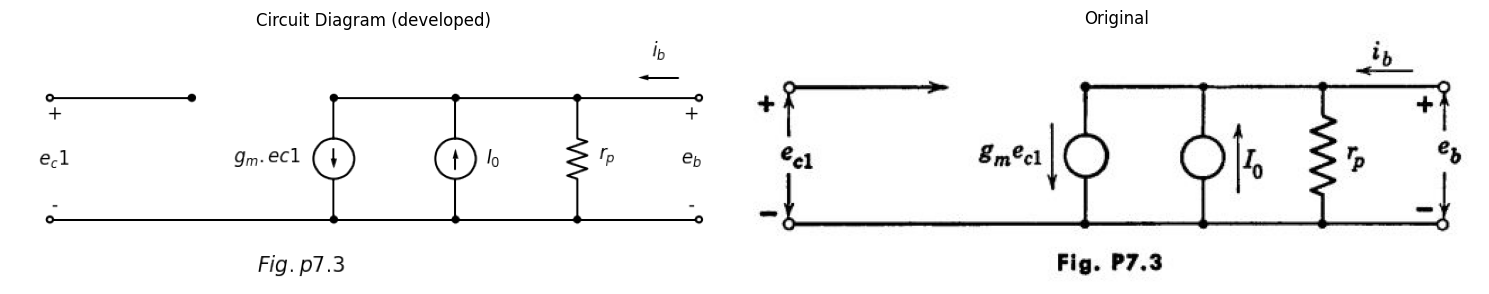

In [340]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()
l1 = d.add(elm.Line().right().length(7).idot(open=True).dot())
l2 = d.add(elm.Line().right().dot())
l3 = d.add(elm.Line().right().dot())
l4 = d.add(elm.Line().right().dot(open=True))
I1 = d.add(elm.SourceI().up().at(l1.end).reverse().label('$ g_m.ec1 $' , ofst=0.3,fontsize = 18).dot())
I2 = d.add(elm.SourceI().up().at(l2.end).label('$ I_0 $' , ofst=-1.6,fontsize = 18).dot())
d += ( R1 := elm.Resistor().up().at(l3.end).label(['$ r_p $'] , ofst=-1.2 , fontsize = 18).dot())
l5 = d.add(elm.Line().right().length(9.0).at(I1.end).dot(open=True))
l6 = d.add(elm.Line().right().length(3.5).at((0,3)).idot(open=True).dot())

d += elm.Arrow().length(1).at((15.5,3.5)).left().label('$ i_b $' , ofst=+0.4, fontsize = 18)
d += elm.Gap().up().at((6.2,-2.3)).label('$ Fig.p7.3 $'  , fontsize = 20)
d += elm.Gap().up().at((0.5,0.0)).label(['-','','','$ e_c1 $','','','+'] , ofst=+0.4, fontsize = 18)
d += elm.Gap().up().at((16.2,0.0)).label(['-','','','$ e_b $','','','+'] , ofst=+0.4, fontsize = 18)
d.save('./Drawings/fig40.png')
d.save('./Drawings/fig40.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig40.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/40.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

the last two being fixed voltages.  Be sure to specify proper units, as well as the numerical values and algebraic signs.

(b) Repeat part (a) at the operating point:

**eb = 187.5** volts, **ec1 = -1.5** volts, **ec2 = 150** volts, **ec3 = 0**

the last two being fixed voltages.	Use the generalized three-halves power law.

**7.8.** In the circuit of Fig. P7.4, quantity A is a positive constant determining the dependent current source **Aio** in terms of current **io**, and quantity **I2** is a fixed positive supply current.

(a)  Sketch and dimension the curve of **i2** vs. **i1** for the region in which **i0** is positive.


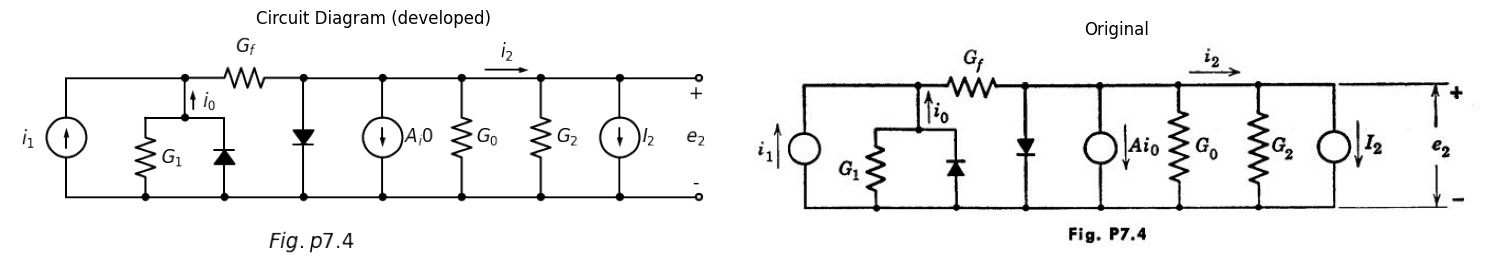

In [339]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

d = schemdraw.Drawing()
d.push()
I1 = d.add(elm.SourceI().up().label('$ i_1 $' , ofst=0.3,fontsize = 18))
l1 = d.add(elm.Line().right().dot())
d += ( R1 := elm.Resistor().right().label(['$ G_f $'] , ofst=0.3 , fontsize = 18).dot())
l2 = d.add(elm.Line().down().at(R1.start).length(1).dot())
l3 = d.add(elm.Line().right().at(R1.end).length(10).dot(open=True))
l4 = d.add(elm.Line().right().length(2).at(I1.start).dot())
d += ( R2 := elm.Resistor().up().length(2).label(['$ G_1 $'] , ofst=-1.2 , fontsize = 18))
l5 = d.add(elm.Line().right().length(2))
D1 = d.add(elm.Diode(fill=True).down().reverse().length(2).dot())
D2 = d.add(elm.Diode(fill=True).down().at(R1.end).dot())
l6 = d.add(elm.Line().right().length(2).dot())
I2 = d.add(elm.SourceI().up().reverse().label('$ A_i0 $' , ofst=-1.8,fontsize = 18).dot())
l7 = d.add(elm.Line().right().length(2).at(l6.end).dot())
d += ( R3 := elm.Resistor().up().label(['$ G_0 $'] , ofst=-1.2 , fontsize = 18).dot())
l8 = d.add(elm.Line().right().length(2).at(l7.end).dot())
d += ( R4 := elm.Resistor().up().label(['$ G_2 $'] , ofst=-1.2 , fontsize = 18).dot())
l9 = d.add(elm.Line().right().length(2).at(l8.end).dot())
I3 = d.add(elm.SourceI().up().reverse().label('$ I_2 $' , ofst=-1.4,fontsize = 18).dot())
l10 = d.add(elm.Line().right().length(2).at(l9.end).dot(open=True))
l11 = d.add(elm.Line().right().length(4).at(l4.end))
d += elm.Arrow().length(0.5).at((3.2,2.2)).up().label('$ i_0 $' , ofst=-0.6, fontsize = 18)
d += elm.Arrow().length(1.1).at((10.6,3.2)).right().label('$ i_2 $' , ofst=0.2, fontsize = 18)
d += elm.Gap().up().at((6.2,-2.3)).label('$ Fig.p7.4 $'  , fontsize = 20)
d += elm.Gap().up().at((16.3,0.0)).label(['-','','','$ e_2 $','','','+'] , ofst=+0.4, fontsize = 18)
d.save('./Drawings/fig41.png')
d.save('./Drawings/fig41.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig41.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/41.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

(b)  Simplify your result for the special case in which the conductance **Gf** is zero.


(c) Compare your results with the voltage transfer curves of certain vacuum-tube amplifiers.


**7.9.** In some pentodes (called gate tubes) the suppressor grid is brought to an external terminal instead of being internally connected to the cathode.


(a) Using physical reasoning, sketch a qualitative curve of plate current **ib** vs. suppressor-grid voltage **ec3** for **eb** and **ec2** fixed positive and **ec1** zero. Show only the negative **ec3** region.


(b) How would you connect the pentode and how would you bias  the control and suppressor grids that a positive signal pulse applied to one of them will produce a negative output pulse at the plate if and only if a positive "gating" pulse  is simultaneously  applied  to  the other grid?


(c)  Discuss the  "pedestal" effect,  where  part  of  the gating  waveform appears at the output along with the waveform to be gated.


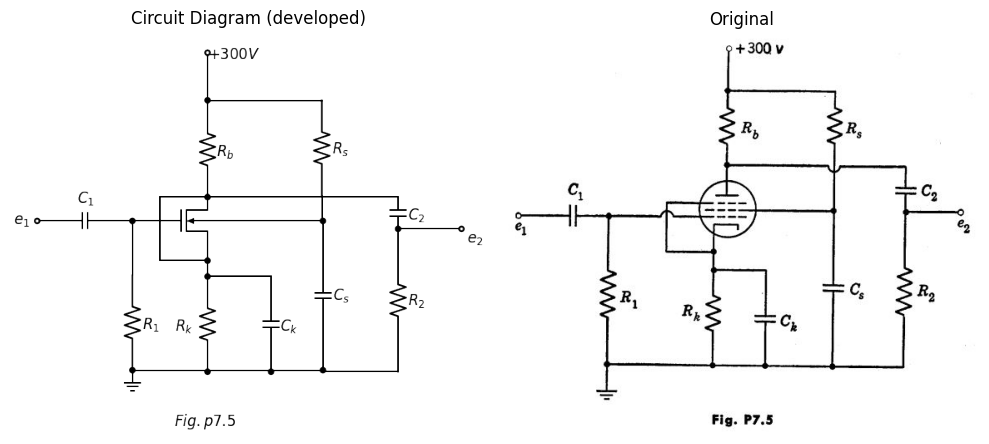

In [273]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
d += ( C1 := elm.Capacitor().right().label(['$ C_1 $'] , ofst=0.2 , fontsize = 18).dot())
l1 = d.add(elm.Line().right().length(1))
d += (M1 := elm.NFet(bulk = True).anchor('gate').reverse())
l2 = d.add(elm.Line().down().length(1).at(M1.source).dot())
d += ( R1 := elm.Resistor().down().label(['$ R_k $'] , ofst=0.2 , fontsize = 18).dot())
l3 = d.add(elm.Line().right().length(2).at(l2.end))
d += ( C2 := elm.Capacitor().down().label(['$ C_k $'] , ofst=-1.1 , fontsize = 18).dot())
l4 = d.add(elm.Line().down().length(1.7).at(C1.end))
d += ( R2 := elm.Resistor().down().label(['$ R_1 $'] , ofst=-1.1 , fontsize = 18).dot())
d += elm.Ground()
l5 = d.add(elm.Line().right().length(6).at(R2.end).dot())
d += ( C3 := elm.Capacitor().up().label(['$ C_s $'] , ofst=-1.1 , fontsize = 18).length(4.7).dot())
l6 = d.add(elm.Line().right().length(1).at(M1.bulk).length(3.6))
l7 = d.add(elm.Line().up().length(0.8))
d += ( R3 := elm.Resistor().up().label(['$ R_s $'] , ofst=-1.1 , fontsize = 18))
l8 = d.add(elm.Line().left().length(3.6).dot())
l9 = d.add(elm.Line().up().length(1.5).dot(open=True))
d += ( R4 := elm.Resistor().up().label(['$ R_b $'] , ofst=-1.1 , fontsize = 18).at(M1.drain).idot())
l10 = d.add(elm.Line().right().length(6).at(R4.start))
d += ( C4 := elm.Capacitor().down().label(['$ C_2 $'] , ofst=-1.1 , fontsize = 18).length(1).dot())
d += ( R5 := elm.Resistor().down().label(['$ R_2 $'] , ofst=-1.1 , fontsize = 18).length(4.5))
l11 = d.add(elm.Line().left().length(2.3))
l12 = d.add(elm.Line().right().length(2).at(C4.end).dot(open=True))
l13 = d.add(elm.Line().left().length(1.5).at(R4.start))
l14 = d.add(elm.Line().down().length(2))
l14 = d.add(elm.Line().right().length(1.5).dot())
d += elm.Gap().up().at((6.2,4.0)).label('$ +300V $'  , fontsize = 18)
d += elm.Gap().up().at((-0.5,-1.2)).label('$ e _1 $'  , fontsize = 18)
d += elm.Gap().up().at((13.8,-1.8)).label('$ e_2 $'  , fontsize = 18)
d += elm.Gap().up().at((5.3,-7.5)).label('$ Fig.p7.5 $'  , fontsize = 18)
d.save('./Drawings/fig42.png')
d.save('./Drawings/fig42.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig42.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/42.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

**7.10.** In the pentode circuit of Fig. P7.5, **ei** is a small a-c signal and the capacitors shown are large enough so that their a-c reactances are negligible at the frequency of **ei**.


(a) How would you choose **R1**, **Rk1**, **Rs**,**R2**, and **Rb** to obtain a desired d-c operating point?

(b) How would you choose suitable values of **C1**, **Ck**, **Cs** and **C2**?


(c) How would you determine the constants **rp** and **gm** of the linear incremental pentode model appropriate to this operating region?


(d) Calculate the incremental a-c voltage gain of the amplifier in terms of appropriate constants. Assume that interelectrode and stray wiring capacitance offers negligibly small susceptance at the frequency of interest.



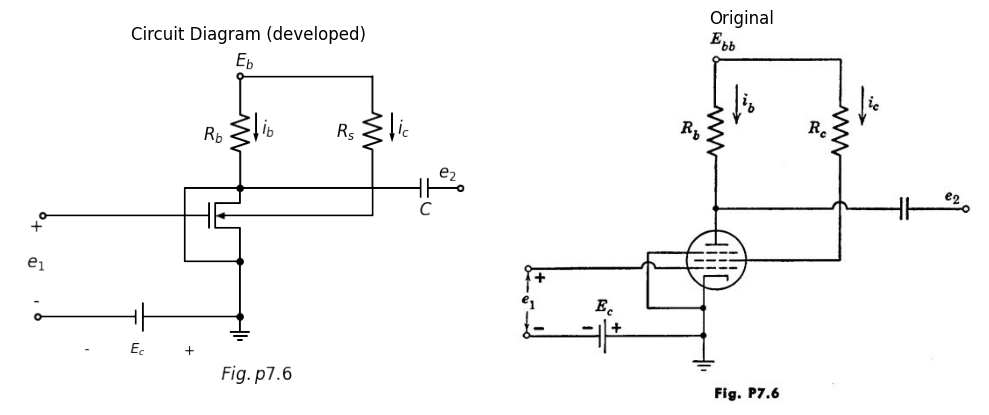

In [278]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
l1 = d.add(elm.Line().right().length(4))
d += (M1 := elm.NFet(bulk = True).anchor('gate').reverse())
l2 = d.add(elm.Line().down().length(2).at(M1.source).dot())
d += elm.Ground()
d += ( E1 := elm.BatteryCell().left().label(['+','$ E_c $','-'] , ofst=-1.5,fontsize = 15).at(l2.end).length(5.5).dot(open=True))
l6 = d.add(elm.Line().right().length(1).at(M1.bulk).length(3.6))
l7 = d.add(elm.Line().up().length(0.8))
d += ( R3 := elm.Resistor().up().label(['$ R_s $'] , ofst=0.2 , fontsize = 18))
l8 = d.add(elm.Line().left().length(3.6).dot(open=True))
d += ( R4 := elm.Resistor().up().label(['$ R_b $'] , ofst=0.2 , fontsize = 18).at(M1.drain).idot())
l10 = d.add(elm.Line().right().length(4).at(R4.start))
d += ( C4 := elm.Capacitor().right().label(['$ C $'] , ofst=-1.1 , fontsize = 18).length(2).dot(open=True))
l13 = d.add(elm.Line().left().length(1.5).at(R4.start))
l14 = d.add(elm.Line().down().length(2))
l14 = d.add(elm.Line().right().length(1.5).dot())
d += elm.Gap().up().at((5.5,3.0)).label('$ E_b $'  , fontsize = 18)
d += elm.Gap().up().at((-0.2,-2.8)).label(['-','','$ e _1 $','','+']  , fontsize = 18)
d += elm.Gap().up().at((11.0,-0.1)).label('$ e_2 $'  , fontsize = 18)
d += elm.Gap().up().at((5.8,-5.5)).label('$ Fig.p7.6 $'  , fontsize = 18)
d += elm.Arrow().length(0.8).at((5.8,2.8)).down().label('$ i_b $', ofst=-0.5, fontsize = 18)
d += elm.Arrow().length(0.8).at((9.5,2.8)).down().label('$ i_c $', ofst=-0.5, fontsize = 18)
d.save('./Drawings/fig43.png')
d.save('./Drawings/fig43.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig43.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/43.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

**7.11.**  A pentode is connected as shown in Fig. P7.6.	Find the gain **Δe2/ Δe1** in terms of **Rb1**, **Rc1**, and tube parameters.


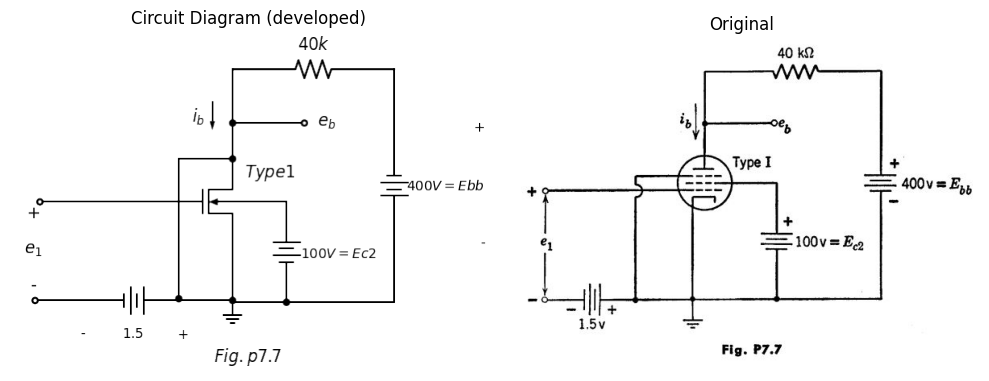

In [338]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
l1 = d.add(elm.Line().right().length(4))
d += (M1 := elm.NFet(bulk = True).anchor('gate').reverse())
l2 = d.add(elm.Line().down().length(2).at(M1.source).dot())
d += elm.Ground()
d += ( E1 := elm.Battery().left().label(['+','$ 1.5 $','-'] , ofst=-1.5,fontsize = 15).at(l2.end).length(5.5).dot(open=True))
l3 = d.add(elm.Line().right().length(1.5).at(M1.bulk))
d += ( E2 := elm.Battery().down().label('$ 100V=Ec2 $', ofst=-2.9,fontsize = 15).length(2.8).dot())
l4 = d.add(elm.Line().left().length(1.5))
l5 = d.add(elm.Line().right().at(E2.end))
d += ( E3 := elm.Battery().up().label(['-','$ 400V=Ebb $','+'] , ofst=-2.9,fontsize = 15).length(6.5))
d += ( R1 := elm.Resistor().left().label(['$ 40k $'] , ofst=0.2 , fontsize = 18).length(4.5))
l6 = d.add(elm.Line().down().length(1.5).dot())
l7 = d.add(elm.Line().right().length(2).dot(open=True))
l8 = d.add(elm.Line().down().length(1).at(l6.end).dot())
l9 = d.add(elm.Line().down().length(0.5))
l10 = d.add(elm.Line().left().length(1.5).at(l8.end))
l11 = d.add(elm.Line().down().length(3.9).dot())
d += elm.Gap().up().at((8.0,1.0)).label('$ e_b $'  , fontsize = 18)
d += elm.Gap().up().at((6.4,-0.4)).label('$ Type1 $'  , fontsize = 18)
d += elm.Gap().up().at((-0.2,-2.8)).label(['-','','$ e _1 $','','+']  , fontsize = 18)
d += elm.Gap().up().at((5.8,-5.5)).label('$ Fig.p7.7 $'  , fontsize = 18)
d += elm.Arrow().length(0.8).at((4.8,2.8)).down().label('$ i_b $', ofst=0.2, fontsize = 18)
d.save('./Drawings/fig44.png')
d.save('./Drawings/fig44.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig44.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/44.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

**7.12.** A Type I pentode is connected in the voltage amplifier circuit shown in Fig. P7.7.


(a)  when **e1** is a sinusoidal voltage of **1** volt rms, determine the maximum and minimum values of the plate voltage **eb**.

(b)  When **e1**  is a sinusoidal voltage of **0.1** volt rms, determine the maximun and minimum values of the plate voltage **eb**.


(c)  If the screen supply voltage **Ec2** should fall to **90** volts, find the value of plate voltage **eb** and plate current **ib** for **e1 = 0**.



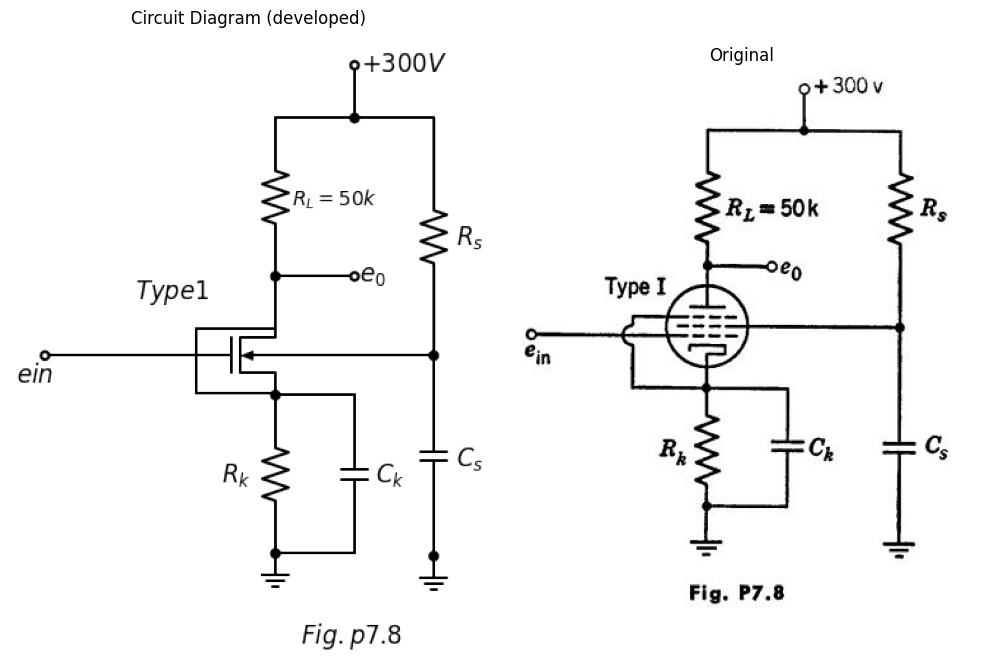

In [414]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
l1 = d.add(elm.Line().right())
d += (M1 := elm.NFet(bulk = True).anchor('gate').reverse())
d += ( R1 := elm.Resistor().down().label(['$ R_k $'] , ofst=0.2 , fontsize = 18).idot().dot())
d += elm.Ground()
l2 = d.add(elm.Line().right().at(R1.end).length(1.5))
d += ( C1 := elm.Capacitor().up().label(['$ C_k $'] , ofst=-1.2 , fontsize = 18))
l3 = d.add(elm.Line().left().length(1.5))      
l4 = d.add(elm.Line().right().at(M1.bulk).dot())
d += ( C2 := elm.Capacitor().down().label(['$ C_s $'] , ofst=-1.2 , fontsize = 18).length(3.8).dot())
d += elm.Ground()
d += ( R2 := elm.Resistor().up().label(['$ R_s $'] , ofst=-1.2 , fontsize = 18).at(l4.end).length(4.5))
l5 = d.add(elm.Line().left().length(1.5).dot())
l6 = d.add(elm.Line().left().length(1.5))
d += ( R3 := elm.Resistor().down().label(['$ R_L=50k $'] , ofst=-2.2 , fontsize = 15).dot())
l7 = d.add(elm.Line().down().length(1))
l8 = d.add(elm.Line().right().length(1.5).at(R3.end).dot(open=True))
l9 = d.add(elm.Line().left().length(1.5).at(l7.end))
l10 = d.add(elm.Line().down().length(1.2))
l11 = d.add(elm.Line().right().length(1.5))
l12 = d.add(elm.Line().up().length(1.0).at(l5.end).dot(open=True))
d += elm.Gap().up().at((6.2,0.3)).label('$ e_0 $'  , fontsize = 18)
d += elm.Gap().up().at((2.4,-0.0)).label('$ Type1 $'  , fontsize = 18)
d += elm.Gap().up().at((-0.2,-1.6)).label('$ e in $'  , fontsize = 18)
d += elm.Gap().up().at((6.8,4.3)).label('$ +300V $'  , fontsize = 18)
d += elm.Gap().up().at((5.8,-6.5)).label('$ Fig.p7.8 $'  , fontsize = 18)

d.save('./Drawings/fig45.png')
d.save('./Drawings/fig45.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig45.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/45.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

**7.13.**	The cathode bias resistor **Rk** in the pentode circuit shown in Fig. P7.8 produces a grid bias voltage of **-1.5** volts and the quiescent screen-grid current through **R**, reduces the screen grid voltage to **100** volt.  Find:


(a)  The quiescent plate current and plate voltage.

(b) The quiescent screen-grid current on the assumption that the ratio of the screen grid current to the plate current  is independent of the negative grid-bias voltage for any plate voltage well above that at the knee of the curves.

(c)	The required value of **Rs**.

(d)	The required value of **Rk**.


(e)	The gain **e0/ ein**.


Assume **Ck** and **Cs** are short circuits for alternating currents.	Use the Type I pentode  characteristics.


**7.14.**	The thyratron shown in Fig. P7.9 may be assumed ideal so that it is replaceable by the model shown in Fig. P7.10.  The relay closes only when current flows in either or both of the coils.	


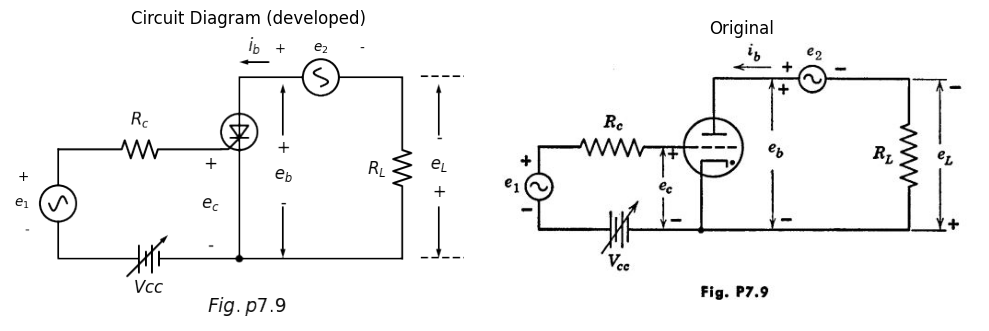

In [505]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += ( V1 := elm.SourceSin().up().label(['-','$ e_1$','+'] , ofst=0.3,fontsize = 15))
d += ( R1 := elm.Resistor().right().length(4.5).label(['$ R_c $'] , ofst=0.3 , fontsize = 18))
D1 = d.add(elm.SCR().down().at((5,4.98)))
E1 = d.add(elm.Source().up())
l1 = d.add(elm.Line().down().at(D1.start).length(5).dot())
d += ( E1 := elm.Battery().left().reverse().length(5).label('$ Vcc $' , ofst=-1.4,fontsize = 18))
l2 = d.add(elm.Line().right().at(l1.end).length(4.5))
d += ( R2 := elm.Resistor().up().length(5.0).label(['$ R_L $'] , ofst=0.2 , fontsize = 18))
d += ( V1 := elm.SourceSin().left().length(4.5).label(['-','$ e_2$','+'] , ofst=0.1,fontsize = 15))
d += elm.Gap().up().at((5.2,-2.5)).label('$ Fig.p7.9 $'  , fontsize = 20)
d += elm.Gap().up().at((4.2,0.0)).label(['-','','','$ e_c$','','','+']  , fontsize = 18)
d += elm.Gap().up().at((6.2,0.8)).label(['-','$ e_b$','+']  , fontsize = 18)
d += elm.Gap().up().at((10.5,1.1)).label(['+','$ e_L$','-']  , fontsize = 18)
d += elm.Line().right().length(1.2).at((10,5.0)).color('black').linestyle('--')
d += elm.Line().right().length(1.2).at((10,0.0)).color('black').linestyle('--')
d += elm.Arrow().up().length(1.4).at((10.5, 3.4)).color('black')
d += elm.Arrow().down().length(1.4).at((10.5, 1.4)).color('black')
d += elm.Arrow().up().length(1.4).at((6.2, 3.4)).color('black')
d += elm.Arrow().down().length(1.4).at((6.2, 1.4)).color('black')
d += elm.Arrow().length(0.8).at((5.8,5.4)).left().label('$ i_b $', ofst=0.2, fontsize = 18)
d += elm.Arrow().length(1.6).theta(+45).at((1.9, -0.5)).color('black')
d.save('./Drawings/fig46.png')
d.save('./Drawings/fig46.svg')

# Load the saved PNG file into the subplot.theta(+45)
img = mpimg.imread('./Drawings/fig46.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/46.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

Coil inductance and resistance are negligible in this idealization.	Let:


**ei = V1 sin ωt**


**e2 = V2 cos ωt**


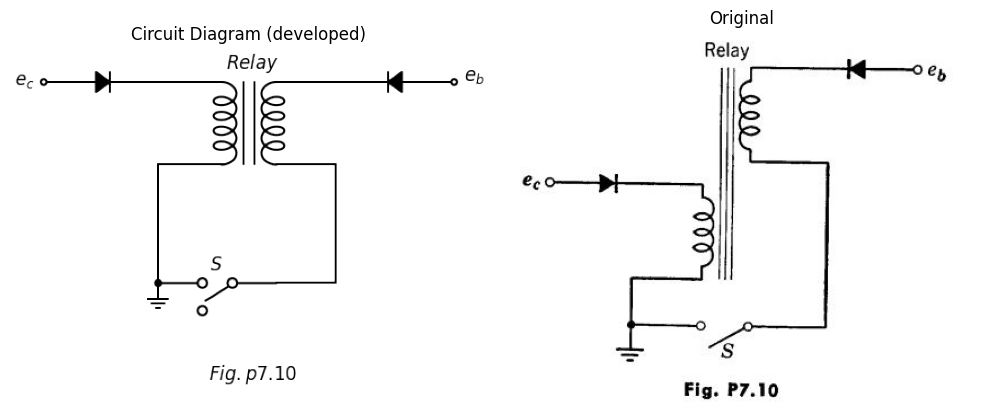

In [555]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()

x = d.add(elm.Transformer(loop=True).tap(name='B', pos=3, side='secondary'))
d += elm.Line().at(x.s1).length(1.5)
D1 = d.add(elm.Diode(fill=True).right().reverse().dot(open=True))
d += elm.Line().at(x.s2).length(1.5)
l1 = d.add(elm.Line().down())
l2 = d.add(elm.Line().left().length(1.5))
S1 = d.add(elm.SwitchSpdt().left().label('$ S $'  , fontsize = 18).dot())
d += elm.Ground()
l3= d.add(elm.Line().up().length(3).at(S1.end))
l4 = d.add(elm.Line().right().length(1.7))
d += elm.Line().at(x.p1).length(1.5).left()
D2 = d.add(elm.Diode(fill=True).reverse().left().dot(open=True))
d += elm.Gap().up().at((6.4,1.0)).label('$ e_b $'  , fontsize = 18)
d += elm.Gap().up().at((0.8,1.4)).label('$ Relay $'  , fontsize = 18)
d += elm.Gap().up().at((-5.0,0.9)).label('$ e _c $' , fontsize = 18)
d += elm.Gap().up().at((0.8,-6.5)).label('$ Fig.p7.10 $'  , fontsize = 18)
d.save('./Drawings/fig47.png')
d.save('./Drawings/fig47.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig47.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/47.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

(a) Plot the time-average value of **eL** as a function of **Vcc** over the control range.


(b)  Repeat part (a) for **e1 = -Vi sin ωt**.


**7.15.** A negative-grid thyratron bas a firing curve specified by the following data:


**Ec** (volts) = **+2** , **Eb** (volts)=**40**


**Ec** (volts) = **0** , **Eb** (volts)=**62**


**Ec** (volts) = **-2** , **Eb** (volts)=**110**


**Ec** (volts) = **-4** , **Eb** (volts)=**200**


**Ec** (volts) = **-6** , **Eb** (volts)=**310**


**Ec** (volts) = **-8** , **Eb** (volts)=**440**


The thyratron is used in the circuit shown in Fig. P7.ll.  Find the firing angle of the thyratron. Find the average d-c current through the **100**-ohm load resistor assuming that the thyratron when conducting has a constant voltage drop of **10** volts. 


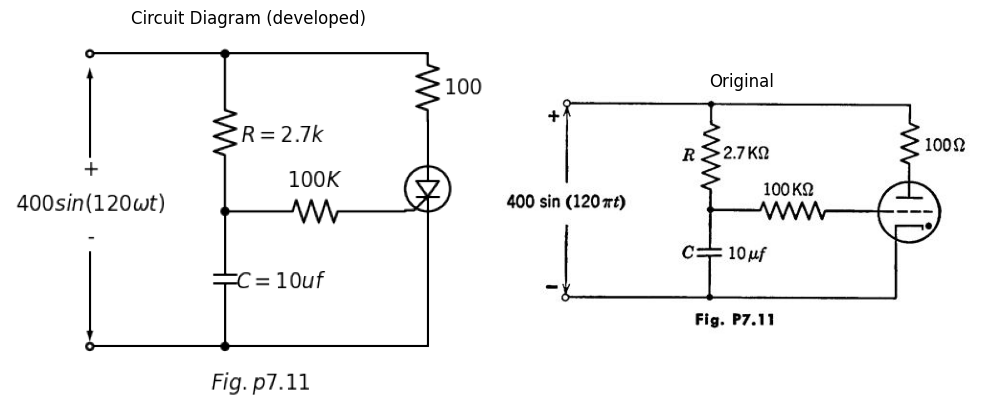

In [611]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
l1 = d.add(elm.Line().right().dot())
d += ( R1 := elm.Resistor().down().length(3.5).label(['$ R=2.7k $'] , ofst=-2.5 , fontsize = 18).dot())
d += ( C1 := elm.Capacitor().down().label(['$ C=10uf $'] , ofst=-2.5 , fontsize = 18).dot())
l2 = d.add(elm.Line().left().dot(open=True))
l3 = d.add(elm.Line().right().length(4.5).at(l1.end))
d += ( R2 := elm.Resistor().down().length(1.5).label(['$ 100 $'] , ofst=-1.5 , fontsize = 18))
D1 = d.add(elm.SCR().down())
E1 = d.add(elm.Source().up())
l4 = d.add(elm.Line().down().at(D1.end).length(2.0))
l5 = d.add(elm.Line().left().length(4.5))
d += ( R3 := elm.Resistor().right().length(4.0).at(R1.end).label(['$ 100K $'] , ofst=0.2 , fontsize = 18))
d += elm.Gap().up().at((0,-4.8)).label(['-','$ 400sin(120ωt) $','+']  , fontsize = 18)
d += elm.Arrow().up().length(2.0).at((0, -2.3)).color('black')
d += elm.Arrow().down().length(2.0).at((0, -4.4)).color('black')
d += elm.Gap().up().at((3.8,-8.5)).label('$ Fig.p7.11 $'  , fontsize = 18)
d.save('./Drawings/fig48.png')
d.save('./Drawings/fig48.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig48.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/48.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

Draw the waveform of the current through the load. If the positions of **R** and **C** are interchanged, what is the new firing angle? The average load current?

**7.16.** In the thyratron rectifier circuit shown in Fig. P7. 12, it is desired to achieve plate current conduction for exactly one-twelf th of each cycle of **e1**. The applied potentials are:


**e1 = 300 sin ωt**


**e2 = -10 + 10 sin(ωt + Φ)**


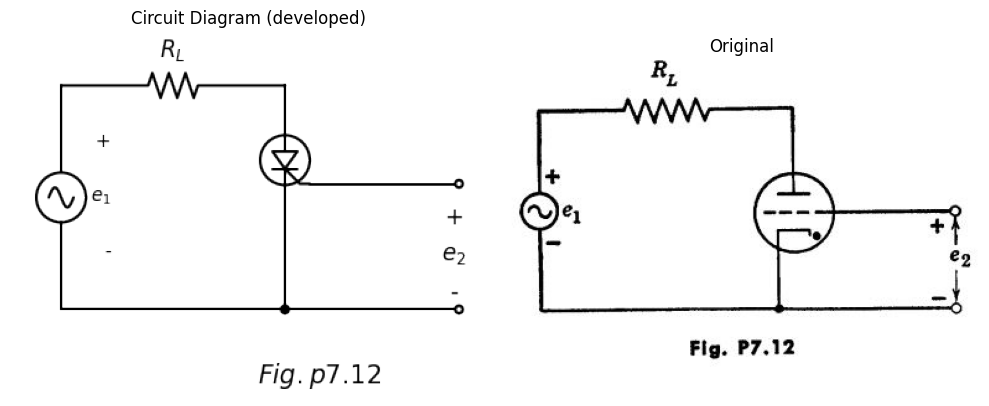

In [696]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += ( V1 := elm.SourceSin().reverse().up().length(4.5).label(['-','$ e_1$','+'] , ofst=-1.5,fontsize = 15))
d += ( R1 := elm.Resistor().right().length(4.5).label(['$ R_L $'] , ofst=0.2 , fontsize = 18))
D1 = d.add(elm.SCR().up().reverse().at((4.5,1.5)))
E1 = d.add(elm.Source().down())
l1 = d.add(elm.Line().down().at(D1.start).length(1.5).dot())
l2 = d.add(elm.Line().left().length(4.5))
l3 = d.add(elm.Line().right().at(l1.end).length(3.5).dot(open=True))
l4 = d.add(elm.Line().right().at(D1.gate).dot(open=True))
d += elm.Gap().up().at((5.2,-2.5)).label('$ Fig.p7.12 $'  , fontsize = 20)
d += elm.Gap().up().at((7.9,-0.4)).label(['-','$ e_2$','+']  , fontsize = 18)
d.save('./Drawings/fig49.png')
d.save('./Drawings/fig49.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig49.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/49.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

The critical grid potential is given as **e1 crit = - eb/ 50**.	Neglect the tube drop during conduction.


(a) Sketch the locus of firing points in the **e2** vs. **t** plane as  **Φ** varies.


(b)  Find the value of  **Φ**  to produce plate conduction for exactly one-twelf th of each cycle of **e1**.


(c) If the plate circuit conducts for one-twelf th of each cycle of **e1**, find the nns value of the current in **RL**.


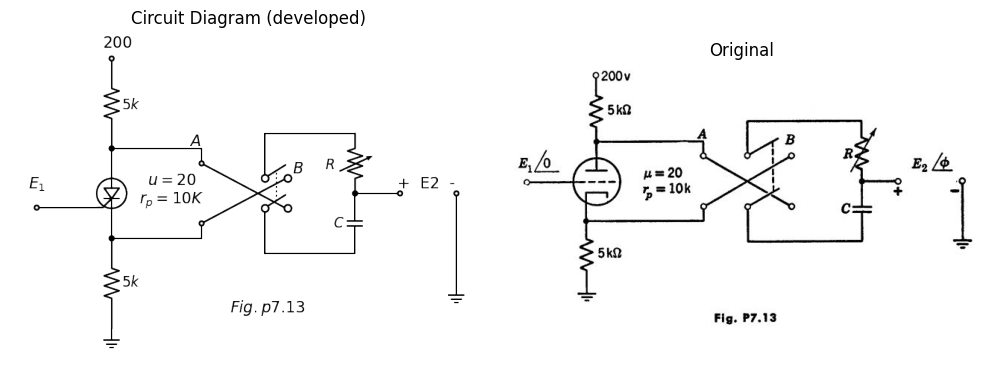

In [717]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += elm.Dot(open=True)
d += ( R1 := elm.Resistor().down().label(['$ 5k $'] , ofst=-1.2 , fontsize = 18).dot())
D1 = d.add(elm.SCR().down())
E1 = d.add(elm.Source().up())
d += ( R2 := elm.Resistor().down().at(D1.end).label(['$ 5k $'] , ofst=-1.2 , fontsize = 18).idot())
d += elm.Ground()
l1 = d.add(elm.Line().left().length(2).at(D1.gate).dot(open=True))
l2 = d.add(elm.Line().right().at(R1.end))
l3 = d.add(elm.Line().down().length(0.5).dot(open=True))
l4 = d.add(elm.Line().length(3.2).theta(-28))
l5 = d.add(elm.Line().right().at(R2.start))
l6 = d.add(elm.Line().up().length(0.5).dot(open=True))
l7 = d.add(elm.Line().length(3.2).theta(+28))
d += ( S1 := elm.SwitchDpst().right().at((5.0,-4.0)))
l8 = d.add(elm.Line().up().length(1.5).at(S1.p1))
l9 = d.add(elm.Line().right())
d += ( R3 := elm.ResistorVar().down().reverse().length(2).label(['$ R $'] , ofst=0.02 , fontsize = 18).dot())
d += ( C1 := elm.Capacitor().down().length(2).label(['$ C $'] , ofst=0.1 , fontsize = 18))
l10 = d.add(elm.Line().left())
l11 = d.add(elm.Line().up().length(1.5))
l12 = d.add(elm.Line().right().length(1.5).at(R3.end).dot(open=True))
d += elm.Dot(open=True).at((11.5,-4.5))
l13 = d.add(elm.Line().down())
d += elm.Ground()
d += elm.Gap().up().at((5.2,-9.5)).label('$ Fig.p7.13 $'  , fontsize = 20)
d += elm.Gap().up().at((2.0,-5.3)).label('$ u=20 $'  , fontsize = 20)
d += elm.Gap().up().at((2.0,-5.9)).label('$ r_p=10K $'  , fontsize = 20)
d += elm.Gap().up().at((-2.5,-5.4)).label('$ E_1 $'  , fontsize = 20)
d += elm.Gap().up().at((10.5,-5.4)).label('+  E2  -'  , fontsize = 20)
d += elm.Gap().up().at((2.8,-4)).label('$ A $'  , fontsize = 20)
d += elm.Gap().up().at((6.2,-4.9)).label('$ B $'  , fontsize = 20)
d += elm.Gap().up().at((0.2,-0.7)).label('$ 200 $'  , fontsize = 20)

d.save('./Drawings/fig50.png')
d.save('./Drawings/fig50.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig50.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/50.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

 **7.17.**	The circuit shown in Fig. P7.13 can be used for phase-shifting the grid voltage of a thyratron.  Derive an expression for phase shift as a function of the variable resistance for switch position A. Sketch the general appearance of the curve of  **Φ** vs. **R** for switch positions A and B. Let the input frequency be **60** cycles and let the capacitive reactance be **100** kilohms. Assume the triode operates in the linear  amplification  region  and  neglect  the  loading eff ects of the **RC** circuit.

 
**7.18.**	A pair of phototubes are used in a bridge circuit (Fig. P7. 14)  to obtain an output response dependent on the position of a light beam, When the beam is centrally positioned with respect to the phototubes, **0.08** lumen falls on each tube and the output voltage is zero.	



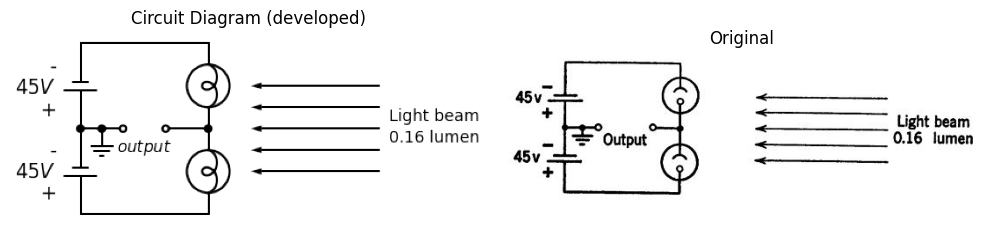

In [747]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
    
d = schemdraw.Drawing()
d.push()
d += ( E1 := elm.BatteryCell().up().length(2).label(['+','$ 45V $','-'] , ofst=0.2,fontsize = 18).idot())
l1 = d.add(elm.Line().right())
d += ( L1 := elm.Lamp().down().length(2).dot())
d += ( L2 := elm.Lamp().down().length(2))
l2 = d.add(elm.Line().left())
d += ( E2 := elm.BatteryCell().up().length(2).label(['+','$ 45V $','-'] , ofst=0.2,fontsize = 18))
l3 = d.add(elm.Line().right().length(0.5).at(E2.end).dot())
d += elm.Ground()
l4 = d.add(elm.Line().right().length(0.5).at(l3.end).dot(open=True))
l5 = d.add(elm.Line().left().length(1).at(L1.end).dot(open=True))
d += elm.Arrow().length(3).left().at((7, 1.0)).color('black')
d += elm.Arrow().length(3).left().at((7, 0.5)).color('black')
d += elm.Arrow().length(3).left().at((7, 0.0)).color('black')
d += elm.Arrow().length(3).left().at((7, -0.5)).color('black')
d += elm.Arrow().length(3).left().at((7, -1.0)).color('black')
d += elm.Gap().up().at((1.5,-1.7)).label('$ output $'  , fontsize = 15)
d += elm.Gap().up().at((8.3,-1.0)).label(' Light beam '  , fontsize = 15)
d += elm.Gap().up().at((8.3,-1.5)).label(' 0.16 lumen '  , fontsize = 15)
          
d.save('./Drawings/fig51.png')
d.save('./Drawings/fig51.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/fig51.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/51.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

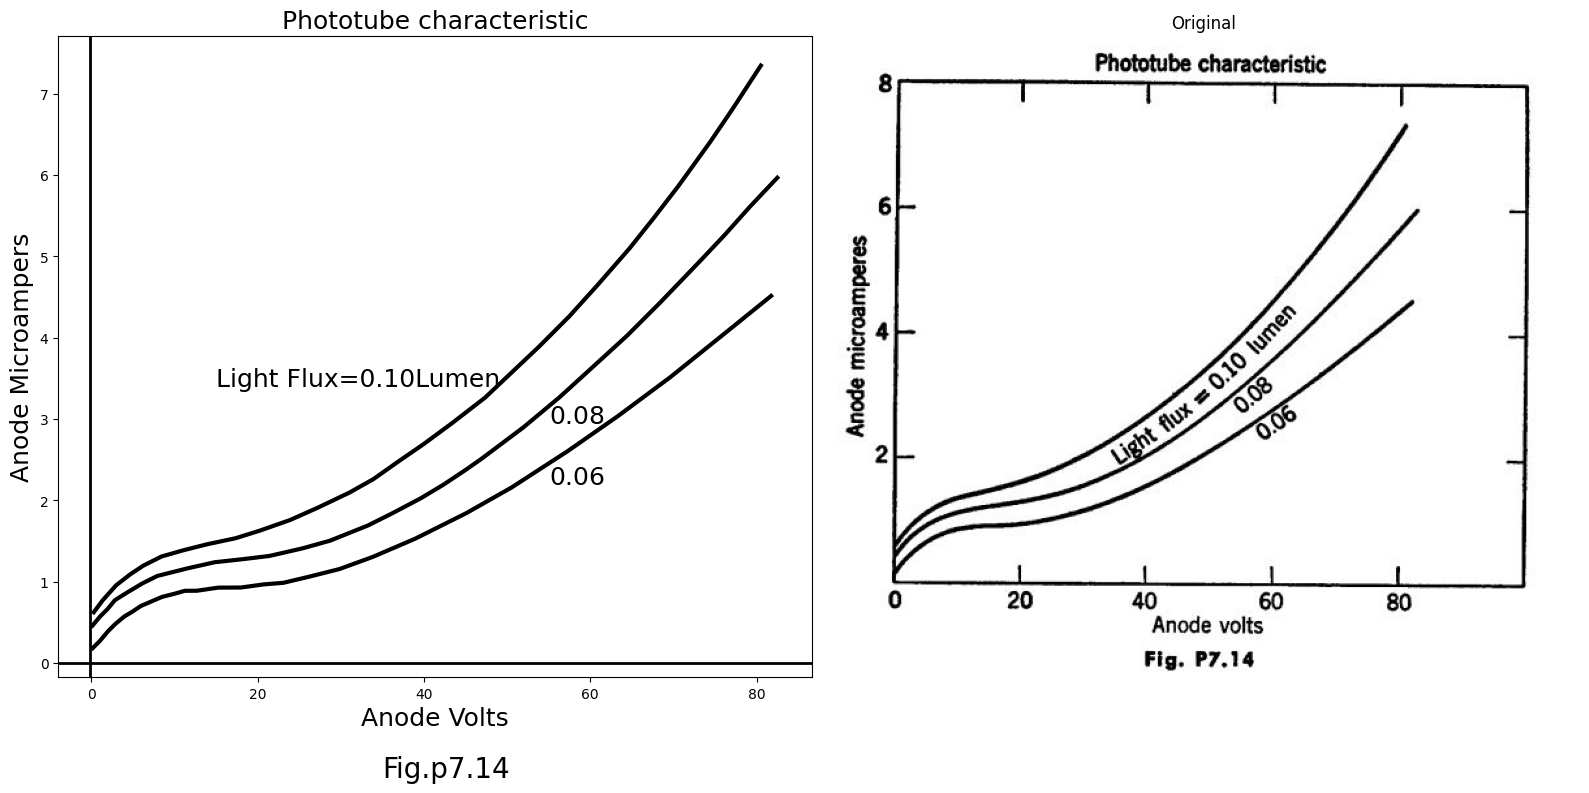

In [780]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

fig, axs = plt.subplots(1, 2, figsize=(16, 8))

#Data
P1 = [0.161791898,1.065305093,1.966717095,2.870230291,3.956547319,4.864262901,5.952681123,7.22600437,8.499327618,9.957555892,11.23298033,12.69541099,
      15.25046226,17.99251975,20.73037485,23.10472348,26.20398386,29.84955455,33.85442932,38.94772231,45.12733232,50.57572701,57.28904017,63.2732392,
      69.61674231,77.04236006,81.75113464]
F1 = [0.18399731,0.276449823,0.387291982,0.479744495,0.572297865,0.627971088,0.702134813,0.75800975,0.813884687,0.851470835,0.888956127,0.889762985,
      0.927954278,0.929467137,0.967759287,0.987460077,1.062733232,1.156698605,1.306034628,1.529534376,1.845587494,2.161237183,2.60632039,3.032610523,
      3.514271306,4.12526475,4.514069592]

P2 = [0.130273996,1.031685998,1.935199193,2.836611195,4.288535888,6.103967053,7.921499412,11.5670701,14.84913431,18.31820474,21.42166751,25.43284586,
      28.71280888,33.26189276,36.16994453,39.62220541,42.34535216,45.06639771,46.87972769,51.95410993,56.29937805,60.27903849,64.43940158,
      68.41485964,73.11102706,76.18087073,79.24861321,82.49915952]
F2 = [0.45984199,0.570684149,0.663136662,0.77397882,0.866733905,0.97808035,1.071037149,1.165002521,1.240376534,1.279072113,1.317565977,1.411733064,
      1.505496722,1.691914607,1.840645487,2.026458228,2.193477895,2.378887208,2.508623298,2.897629854,3.267843335,3.637855102,4.026357371,4.433148428,
      4.932291141,5.265019331,5.616137166,
5.967355858]

P3 = [0.294167087,1.374180535,2.998403093,4.628929232,6.261556564,8.442595394,10.99344428,13.90990082,17.37476887,20.28912422,23.93049252,27.20415196,
      31.02202051,33.92797109,37.01042192,39.91217011,43.35602622,47.34199025,50.59673895,53.85148764,57.46554043,60.89468818,64.68314002,
      67.56597748,70.62741637,74.40536225,77.10119348,80.51353169]
F3 = [0.625449655,0.773171962,0.95797613,1.087611363,1.198856951,1.31040511,1.385375693,1.460547991,1.536022861,1.629584804,1.760329467,1.909262061,
      2.095276517,2.262397042,2.484787359,2.688687174,2.948058497,3.262901328,3.57734073,3.891780131,4.261590183,4.649689023,5.093158514,5.462565137,
      5.868851908,6.404269625,6.810354681,7.345570684 ]


axs[0].plot(P1, F1, 'black',linewidth=3,linestyle='-')
axs[0].plot(P2, F2, 'black',linewidth=3,linestyle='-')
axs[0].plot(P3, F3, 'black',linewidth=3,linestyle='-')
axs[0].axhline(0, color='black',linewidth=2, ls='-')
axs[0].axvline(-0.2, color='black',linewidth=2, ls='-')
axs[0].text(55,2.95, '$ 0.08 $', fontsize=18)
axs[0].text(55,2.2, '$0.06 $', fontsize=18)
axs[0].text(15,3.4, 'Light Flux=0.10Lumen', fontsize=18)
axs[0].set_title('Phototube characteristic', fontsize=18)
axs[0].set_ylabel('Anode Microampers', fontsize=18)
axs[0].set_xlabel('Anode Volts', fontsize=18)
axs[0].text(35,-1.4, 'Fig.p7.14', fontsize=20)


# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/52.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show()

Suppose the beam is shifted so that 0.10 lumen falls on the upper phototube, the remainder falling on the lower tube. Determine the magnitude of the output voltage and it-s polarity with respect to ground potential.

<!--NAVIGATION-->
( Previous: [**6.1 Vacuum Triodes**](../Chapter.6/chapter6.ipynb)( [**TOC**](../TOC.md) | Next: [**8.1 Wave Shaping And Amplification**](../chapter.8/chapter8.ipynb) )


[**This file as MS Word (docx)**](./Docs/chapter7.docx) 
